# Erratum — read before the narrative below

This notebook is published **exactly as executed** for run `run_20260923_134752`. No cell
has been re-run and no output has been altered. Three statements in the original narrative
were already out of date when the run finished, and they are corrected here rather than
silently edited in place.

**1. pH is a model feature in this run.** The heading cell below, the `NOTE:` in Cell 3.6
and the `Reminder:` printed by Cell 5.1 all state that pH is "retained for analysis but
excluded from training". That describes the earlier iteration of this pipeline. In this run
pH is column 6 of the 283-column feature matrix and carries its own four-column provenance
block (`measured`, `derived`, `banded`, `missing`). Section 3.1b derives it from the
recorded aggressive medium, raising availability from 21.8 % to 99.5 % of rows, and the
ablation in Section 10 scores it explicitly. Its measured marginal contribution is
**-0.005** explained variance, so it is carried for transparency about provenance, not for
predictive gain.

**2. The conformal interval printed by Cell 9.3 is superseded.** That cell calibrates on
`rng.permutation(len(y))`, which is a *row-wise* partition, and prints a half width of
18.67 points at 97.4 % empirical coverage. Because almost every molecule appears several
times in the corpus, a row-wise calibration set shares molecules with the fitting set, and
the interval it yields is too narrow for the question the model is asked. Recalibrated on a
partition disjoint **at the level of the molecule**, the 90 % interval is **±38.6 points at
92.6 % empirical coverage**. That is the figure quoted in the thesis abstract and in
`docs/RESULTS.md`, and the one the deployed service returns. `figures/fig10_conformal_
intervals.png` plots the superseded row-wise version.

**3. Nested cross-validation was implemented but not executed.** Cell 6.6b contains the
nested procedure and was left unrun: its cost exceeded the session allowance. The tuned
figures are therefore optimistic by an unmeasured margin. The untuned benchmark, which
involved no selection against the reported folds, carries the comparative conclusions.

See `docs/LIMITATIONS.md` for the full list and `docs/REPRODUCIBILITY.md` for the
environment and seeds.


# Corrosion Inhibitor Efficiency Prediction

### An Artificial Intelligence Driven Quantitative Structure Property Relationship Framework

This notebook implements the complete end to end pipeline for predicting the corrosion
inhibition efficiency (IE) of organic molecules from their structure. It is organised into
nine sequential sections.

**Updated, condition-aware version.** This revision changes the pipeline in three ways that
together give the model substantially more data to learn from and a fairer chance of working:

1. **Experimental conditions are now features.** Temperature (K), duration (hours),
   concentration (mM, log-scaled) and the metal (one-hot) are carried through preprocessing
   and fed to the models alongside the molecular structure. Inhibition efficiency genuinely
   depends on these conditions, so giving them to the model addresses the single biggest
   limitation of the earlier structure-only version.
2. **pH is retained for analysis but excluded from training.** It is kept in the master table
   so it can be inspected, but it never enters any feature matrix, by design.
3. **Deduplication now keeps distinct conditions.** Instead of averaging every measurement of
   a molecule on a metal into one row (which collapsed ~8000 rows to ~700), we deduplicate on
   (molecule, metal, temperature, duration, concentration). Two measurements of the same
   molecule under different conditions are now legitimately separate training examples. This
   raises the usable dataset from a few hundred rows to several thousand.

The sections are: (1) setup, (2) data inspection, (3) preprocessing and harmonisation,
(4) pipeline diagram, (5) feature analysis, (6) classical models, (7) neural and graph models,
(8) chemistry transformer, (9) ensembles, calibration and MLOps. Each code cell is preceded by
a markdown explanation. Every figure is captioned in APA style and saved to the run directory.


## 1. Setup and Environment

This section prepares the runtime. It installs the libraries required by later sections, imports the standard scientific Python stack, fixes random seeds for reproducibility, and creates the run directory under which every artefact produced by the notebook will be saved. If you are running this in Google Colab from a fresh session, expect the installation cell to take three to five minutes the first time.

### 1.1 Install required packages

The notebook depends on a relatively wide collection of libraries that are not all pre installed in Colab. Installation is wrapped in a quiet pip call. We avoid pinning exact versions here to maximise compatibility with whatever Colab currently provides, while listing the libraries explicitly so the user knows what is being added.

In [1]:
# Cell 1.1 — Install required packages
# Run once per Colab session. Restart the runtime if any installation fails.
import subprocess, sys

PACKAGES = [
    "rdkit",                  # cheminformatics
    "deepchem",               # graph featurisation utilities
    "torch",                  # already in Colab, listed for completeness
    "torch-geometric",        # graph neural networks
    "transformers",           # chemistry transformer
    "shap",                   # explainable AI for classical models
    "captum",                 # integrated gradients
    "optuna",                 # hyperparameter tuning
    "mapie",                  # conformal prediction
    "scikit-learn",           # classical regressors
    "matplotlib",
    "seaborn",
    "pandas",
    "numpy",
]

def install(pkg):
    print(f"Installing {pkg} ...")
    r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", pkg],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(f"  WARNING: {pkg} install returned non zero. stderr tail:")
        print("  " + r.stderr.splitlines()[-1] if r.stderr else "  (no stderr)")
    else:
        print(f"  OK {pkg}")

for p in PACKAGES:
    install(p)

print()
print("All package installation attempts complete.")


Installing rdkit ...
  OK rdkit
Installing deepchem ...
  OK deepchem
Installing torch ...
  OK torch
Installing torch-geometric ...
  OK torch-geometric
Installing transformers ...
  OK transformers
Installing shap ...
  OK shap
Installing captum ...
  OK captum
Installing optuna ...
  OK optuna
Installing mapie ...
  OK mapie
Installing scikit-learn ...
  OK scikit-learn
Installing matplotlib ...
  OK matplotlib
Installing seaborn ...
  OK seaborn
Installing pandas ...
  OK pandas
Installing numpy ...
  OK numpy

All package installation attempts complete.


### 1.2 Imports and reproducibility

We import the libraries used throughout the notebook, fix the global random seed, and probe the runtime so that subsequent cells know whether a GPU is available. Sections that train neural networks degrade gracefully to CPU if no GPU is present.

In [2]:
# Cell 1.2 — Imports and reproducibility
import os, sys, json, time, hashlib, pathlib, warnings, random
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"

sns.set_theme(context="notebook", style="whitegrid", palette="muted")

print(f"Python      : {sys.version.split()[0]}")
print(f"NumPy       : {np.__version__}")
print(f"Pandas      : {pd.__version__}")
print(f"Device      : {DEVICE}")
try:
    print(f"PyTorch     : {torch.__version__}")
    if torch.cuda.is_available():
        print(f"GPU         : {torch.cuda.get_device_name(0)}")
except Exception:
    print("PyTorch     : not available")
print(f"Random seed : {SEED}")


Python      : 3.12.13
NumPy       : 2.0.2
Pandas      : 2.3.3
Device      : cuda
PyTorch     : 2.10.0+cu128
GPU         : Tesla T4
Random seed : 42


### 1.3 Run directory

Every artefact produced by the notebook is written under a single timestamped run directory. This includes cleaned data, trained model weights, metrics, figures, attribution maps, and the manifest. At the end of the notebook, the entire directory is archived as a single zip file for download.

In [3]:
# Cell 1.3 — Run directory and manifest
RUN_ROOT = pathlib.Path("runs") / datetime.now().strftime("run_%Y%m%d_%H%M%S")
SUBDIRS = ["data", "figures", "models", "metrics", "attributions", "logs"]
for s in SUBDIRS:
    (RUN_ROOT / s).mkdir(parents=True, exist_ok=True)

MANIFEST = {
    "created_utc": datetime.now().isoformat() + "Z",
    "seed": SEED,
    "device": DEVICE,
    "artefacts": [],
}

def register(path, kind, note=""):
    """Add an artefact to the manifest."""
    rel = str(pathlib.Path(path).relative_to(RUN_ROOT))
    MANIFEST["artefacts"].append({"path": rel, "kind": kind, "note": note})

def write_manifest():
    with open(RUN_ROOT / "manifest.json", "w") as f:
        json.dump(MANIFEST, f, indent=2)

write_manifest()
print(f"Run directory : {RUN_ROOT}")
for s in SUBDIRS:
    print(f"  + {s}/")


Run directory : runs/run_20260923_134752
  + data/
  + figures/
  + models/
  + metrics/
  + attributions/
  + logs/


In [4]:
# Cell 1.2b — Runtime specification
# The system specification is part of the method: training times, batch sizes and the
# feasibility of the transformer section all depend on it, and a result that cannot be
# attributed to a known environment cannot be reproduced or compared.
import sys, os, platform, subprocess, json

rows = [("Python", platform.python_version()),
        ("Platform", platform.platform()),
        ("Processor", platform.processor() or "not reported"),
        ("Logical CPU cores", str(os.cpu_count()))]

try:
    import psutil
    vm = psutil.virtual_memory()
    rows.append(("System RAM", f"{vm.total/1e9:.1f} GB total, {vm.available/1e9:.1f} GB available"))
except Exception:
    try:
        kb = int(subprocess.check_output(["grep", "MemTotal", "/proc/meminfo"]).split()[1])
        rows.append(("System RAM", f"{kb/1e6:.1f} GB total"))
    except Exception:
        rows.append(("System RAM", "not reported"))

try:
    import torch
    rows.append(("PyTorch", torch.__version__))
    rows.append(("CUDA available", str(torch.cuda.is_available())))
    if torch.cuda.is_available():
        rows.append(("CUDA version", torch.version.cuda))
        rows.append(("cuDNN version", str(torch.backends.cudnn.version())))
        rows.append(("GPU count", str(torch.cuda.device_count())))
        for i in range(torch.cuda.device_count()):
            p = torch.cuda.get_device_properties(i)
            rows.append((f"  GPU {i}",
                         f"{p.name}, {p.total_memory/1e9:.1f} GB, "
                         f"compute capability {p.major}.{p.minor}, {p.multi_processor_count} SMs"))
    else:
        rows.append(("Compute device", "CPU only — no accelerator is attached"))
except ImportError:
    rows.append(("PyTorch", "not installed"))

for mod in ["numpy", "pandas", "scipy", "sklearn", "rdkit", "xgboost",
            "optuna", "shap", "transformers", "torch_geometric", "matplotlib", "seaborn"]:
    try:
        m = __import__(mod)
        rows.append((mod, getattr(m, "__version__", "present")))
    except Exception:
        rows.append((mod, "not installed"))

print("=" * 72)
print("RUNTIME SPECIFICATION")
print("=" * 72)
for k, v in rows:
    print(f"  {k:22s} {v}")
print("=" * 72)
print(f"  {'Random seed':22s} {SEED}")
print(f"  {'Cross-validation folds':22s} 5, identical indices for every model")

try:
    print("\nnvidia-smi:")
    print(subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total,driver_version,utilization.gpu",
         "--format=csv"], text=True).strip())
except Exception:
    print("\nnvidia-smi unavailable (no NVIDIA driver on this host)")

json.dump(dict(rows), open(RUN_ROOT / "logs" / "runtime_spec.json", "w"), indent=2)
register(RUN_ROOT / "logs" / "runtime_spec.json", "log", "Runtime specification")

RUNTIME SPECIFICATION
  Python                 3.12.13
  Platform               Linux-6.12.90+-x86_64-with-glibc2.35
  Processor              x86_64
  Logical CPU cores      4
  System RAM             33.7 GB total, 31.8 GB available
  PyTorch                2.10.0+cu128
  CUDA available         True
  CUDA version           12.8
  cuDNN version          91002
  GPU count              2
    GPU 0                Tesla T4, 15.6 GB, compute capability 7.5, 40 SMs
    GPU 1                Tesla T4, 15.6 GB, compute capability 7.5, 40 SMs
  numpy                  2.0.2
  pandas                 2.3.3
  scipy                  1.16.3
  sklearn                1.6.1
  rdkit                  2026.03.6
  xgboost                3.2.0
  optuna                 4.9.0
  shap                   0.51.0
  transformers           5.0.0
  torch_geometric        2.8.0.post1
  matplotlib             3.10.0
  seaborn                0.13.2
  Random seed            42
  Cross-validation folds 5, identical indices 

### 1.4 Locate the source CSV files

We expect three CSV files to be available in the Colab session. If you have uploaded them via the Files pane on the left, they live at `/content/`. If you are running locally, adjust the paths accordingly. The cell prints the resolved paths and verifies each file is readable. If a file is missing, the cell prints a clear error rather than crashing later.

In [5]:
# Cell 1.4 — Locate source files
CANDIDATE_DIRS = [
    "/content",                                # Colab default
    "/content/data", "/content/drive/MyDrive",
    ".", "data", "./data",                     # current directory
    "/kaggle/input", "/kaggle/working",        # Kaggle
]

# Kaggle mounts each attached dataset in its own folder under /kaggle/input, so the
# candidate list is extended with whatever is actually present.
import glob as _glob
for _d in sorted(_glob.glob("/kaggle/input/*")):
    CANDIDATE_DIRS.append(_d)

EXPECTED = {
    "inhibitor1368": [
        "Inhibitor1368_molecular_properties.csv",
        "Inhibitor1368__New__-_Inhibitor1368_molecular_properties_new_all_update_Category_csv.csv",
        "/content/Inhibitor1368 (New) - Inhibitor1368_molecular_properties_new_all_update_Category_csv.csv",
        "Inhibitor1368_molecular_properties_new_all_update_Category_-_Inhibitor1368_molecular_properties_new_all_update_Category_csv.csv",
        "/kaggle/input/datasets/victorjacobasuquo/corrosion-inhibitor-dataset/Inhibitor1368 (New) - Inhibitor1368_molecular_properties_new_all_update_Category.csv.csv",
        "/kaggle/input/datasets/victorjacobasuquo/corosion-dataset/Inhibitor1368_molecular_properties_new_all_update_Category - Inhibitor1368_molecular_properties_new_all_update_Category.csv (1).csv"
    ],
    "datacor_al": [
        # CorData (newest) supersedes the aluminium-only DataCor export. It carries
        # five metals, pH, methodology, salt concentration and synergist type, all of
        # which are required by the revised feature block.
        "Cordata_newest_Al_Cu_Fe_Mg_Zn.csv",
        "Cordata_newest_-_Al_Cu_Fe_Mg_Zn.csv",
        "Cordata newest - Al_Cu_Fe_Mg_Zn.csv",
        "/kaggle/input/corrosion-inhibitor-dataset/Cordata_newest_Al_Cu_Fe_Mg_Zn.csv",
        "/kaggle/input/datasets/victorjacobasuquo/corosion-dataset/Cordata (newest) - Al Cu Fe Mg Zn.csv",
        "/content/DataCor (New) - Efficiencies.csv",
        "DataCor_2026-02-04_Al_xlsx_-_Efficiencies.csv",
        "/kaggle/input/datasets/victorjacobasuquo/corrosion-inhibitor-dataset/DataCor (New) - Efficiencies.csv",
    ],
    "excorr": [
        "Excorr_dataset_new.csv",
        "Excorr_dataset_new_-_database_5.csv",
        "Excorr_dataset__new__-_database__5__csv.csv",
        "/kaggle/input/datasets/victorjacobasuquo/corosion-dataset/Excorr dataset (new) - database (5).csv (1).csv",
        "/content/Excorr_dataset (new) - database (5)_csv.csv",
        "Data_Source_-_database__2_.csv",
        "/kaggle/input/datasets/victorjacobasuquo/corrosion-inhibitor-dataset/Excorr dataset (new) - database (5).csv.csv",
    ],
}

def find_file(candidates):
    for d in CANDIDATE_DIRS:
        for name in candidates:
            p = pathlib.Path(d) / name
            if p.exists():
                return p
    # Fall back to a loose match on a distinctive stem, so that a renamed export
    # (a common outcome of downloading from Google Sheets) is still found.
    stems = {"inhibitor1368": "inhibitor1368", "datacor_al": "cordata", "excorr": "excorr"}
    stem = None
    for k, v in stems.items():
        if any(v in c.lower() or k.split("_")[0] in c.lower() for c in candidates):
            stem = v
            break
    if stem:
        for d in CANDIDATE_DIRS:
            dd = pathlib.Path(d)
            if not dd.is_dir():
                continue
            for p in sorted(dd.glob("*.csv")):
                if stem in p.name.lower().replace(" ", "").replace("-", "").replace("_", ""):
                    return p
    return None

SRC = {key: find_file(names) for key, names in EXPECTED.items()}
for k, v in SRC.items():
    if v is None:
        print(f"MISSING : {k}  (looked for: {EXPECTED[k][0]})")
    else:
        print(f"FOUND   : {k:14s} -> {v}")

if not all(v is not None for v in SRC.values()):
    print("\nSearched:", ", ".join(CANDIDATE_DIRS))
    raise FileNotFoundError(
        "One or more source files were not found. Upload the three CSV files "
        "(Inhibitor 1368, CorData newest, Excorr) and re-run this cell."
    )


FOUND   : inhibitor1368  -> /kaggle/input/datasets/victorjacobasuquo/corosion-dataset/Inhibitor1368_molecular_properties_new_all_update_Category - Inhibitor1368_molecular_properties_new_all_update_Category.csv (1).csv
FOUND   : datacor_al     -> /kaggle/input/datasets/victorjacobasuquo/corosion-dataset/Cordata (newest) - Al Cu Fe Mg Zn.csv
FOUND   : excorr         -> /kaggle/input/datasets/victorjacobasuquo/corosion-dataset/Excorr dataset (new) - database (5).csv (1).csv


## 2. Data Inspection and Exploratory Analysis

This section opens each of the three source files and produces a non destructive audit. For every dataset we report the shape, column schema, data types, count of unique values, missingness per column, summary statistics for the target, the distribution across metals and electrolytes where applicable, and a duplicate analysis. Every figure is captioned in American Psychological Association style and saved to the run directory.

### 2.1 Load the three datasets

We load each CSV with explicit handling for the columns that pandas would otherwise misinterpret. The Excorr database contains several columns that are entirely empty in our copy; pandas infers them as float, but we keep them as-is for completeness.

In [6]:
# Cell 2.1 — Load source datasets
inh = pd.read_csv(SRC["inhibitor1368"], low_memory=False)
dac = pd.read_csv(SRC["datacor_al"],   low_memory=False)
exc = pd.read_csv(SRC["excorr"],       low_memory=False)

print(f"Inhibitor 1368 : shape = {inh.shape}")
print(f"DataCor Al     : shape = {dac.shape}")
print(f"Excorr         : shape = {exc.shape}")


Inhibitor 1368 : shape = (1364, 30)
DataCor Al     : shape = (5000, 17)
Excorr         : shape = (4616, 35)


In [96]:
inh

,id,SMILES,QED,LogP,MolWt,HBA,HBD,TPSA,NumRotBonds,IE,...,Electron Affinity,Electronegativity,Hardness,Softness,Electrophilicity,Electron Donor Capacity,Electron Acceptor Capacity,vdw_volume,vdw_surface_area,Category
0,1,Brc1ccc(-n2ccnc2)cc1,0.726070,2.63480,223.073,2,0,17.82,1,0.8070,...,0.03902,0.133565,0.094545,10.576974,0.094345,0.275182,0.008052,1298.279,1301.272689,Imidazoles
1,2,Brc1ccc2nc[nH]c2c1,0.689170,2.32540,197.035,1,1,28.68,0,0.8600,...,0.02847,0.126410,0.097940,10.210333,0.081578,0.256958,0.004138,1141.338,1137.243600,Benzimidazoles
2,3,C(=N/c1ccc(Cc2ccc(/N=C/c3ccsc3)cc2)cc1)\c1ccsc1,0.321947,6.90160,386.545,4,0,24.72,6,0.8890,...,0.04959,0.128660,0.079070,12.647022,0.104676,0.272871,0.015551,3255.509,3258.764080,Schiff bases
3,4,C(=N/c1ccc(CCc2ccc(/N=C/c3ccsc3)cc2)cc1)\c1ccsc1,0.295693,7.09600,400.572,4,0,24.72,7,0.9140,...,0.05075,0.129890,0.079140,12.635835,0.106592,0.276052,0.016272,3062.357,3070.427058,Schiff bases
4,5,C(=N/c1ccc(Oc2ccc(/N=C/c3ccccn3)cc2)cc1)\c1ccccn1,0.400203,5.77010,378.435,5,0,59.73,6,0.8898,...,0.06466,0.131180,0.066520,15.033073,0.129346,0.293786,0.031426,3402.462,3404.324760,Schiff bases
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1359,1360,Oc1ccccc1-c1nc(-c2ccccc2)c(-c2ccccc2)n1-c1ccccc1,0.377586,6.57890,388.470,3,1,38.05,4,0.9020,...,0.02710,0.109060,0.081960,12.201074,0.072560,0.222600,0.004480,3327.749,3329.926450,Quinolines
1360,1361,Cc1ccc(/C=C/C=O)cc1,0.461495,2.20712,146.189,1,0,17.07,2,0.3300,...,0.06917,0.151175,0.082005,12.194378,0.139344,0.331522,0.029172,1291.580,NaN,other
1361,1362,COc1ccc(/C=C/C=O)cc1,0.500939,1.90730,162.188,2,0,26.30,3,0.6100,...,0.06244,0.142645,0.080205,12.468051,0.126847,0.309595,0.024305,1279.848,NaN,other
1362,1363,N1=CC=CC2=CC=C3C(=C12)OC(C(=C3C1=CC=CC=C1)C#N)N,0.748444,3.23748,299.333,4,1,71.93,1,0.4910,...,0.08016,0.148515,0.068355,14.629508,0.161339,0.344032,0.047002,2514.793,2520.616230,Epoxy


In [97]:
dac

,Unnamed: 0,Inhibitor,Mol._weight,SMILES,Metal,Alloy,Time_h,Temperature_K,pH,Inhib_Concentrat_M,Salt_Concentrat_M,Synergistic_Inhib_type,Synergistic_Inhib_M,Methodology,Reference,Contributor,Efficiency
0,1,(Benzo[d]thiazol-2-ylthio)methyl)(2-methoxyeth...,299.37,COCCOC(=O)OCSc1nc2c(s1)cccc2,Al,AA2024,24.0,298.0,4.0,0.001,0.1,NaN,0.0,Image processing,"Winkler, Corrosion Science 106 (2016) 229–235","Tiago Galvão / Inês Ferreira, University of Av...",0.0
1,2,(Benzo[d]thiazol-2-ylthio)methyl)(2-methoxyeth...,299.37,COCCOC(=O)OCSc1nc2c(s1)cccc2,Al,AA2024,24.0,298.0,10.0,0.001,0.1,NaN,0.0,Image processing,"Winkler, Corrosion Science 106 (2016) 229–235","Tiago Galvão / Inês Ferreira, University of Av...",0.0
2,3,(Benzo[d]thiazol-2-ylthio)methyl)(2-methoxyeth...,299.37,COCCOC(=O)OCSc1nc2c(s1)cccc2,Al,AA7075,24.0,298.0,4.0,0.001,0.1,NaN,0.0,Image processing,"Winkler, Corrosion Science 106 (2016) 229–235","Tiago Galvão / Inês Ferreira, University of Av...",0.0
3,4,(Benzo[d]thiazol-2-ylthio)methyl)(2-methoxyeth...,299.37,COCCOC(=O)OCSc1nc2c(s1)cccc2,Al,AA7075,24.0,298.0,10.0,0.001,0.1,NaN,0.0,Image processing,"Winkler, Corrosion Science 106 (2016) 229–235","Tiago Galvão / Inês Ferreira, University of Av...",0.0
4,5,[2-(5-Methyl)-2-hydroxyphenyl]benzotriazole,225.25,Cc1ccc(c(c1)n1nc2c(n1)cccc2)O,Al,AA2024,24.0,298.0,4.0,0.001,0.1,NaN,0.0,Image processing,"Winkler, Corrosion Science 106 (2016) 229–235","Tiago Galvão / Inês Ferreira, University of Av...",30.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4996,4997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4997,4998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4998,4999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [98]:
exc

,index,Inhibitor,CAS,MW,SMILES,Metal,Alloy,Method,pH,pH_end,...,IE,References,Year,Journal,DOI,CV1,CV2,remarks,Unnamed: 33,canonical_SMILES
0,1,8-(4-bromobutoxy)quinoline(QN-C4Br),NaN,280.165,BrCCCCOc1cccc2cccnc12,Fe,Carbon Steel,potentiodynamic polarization,NaN,NaN,...,97.5,Effect of hydrocarbon chain length for acid co...,2021,Journal of Molecular Structure,10.1016,NaN,NaN,NaN,NaN,BrCCCCOc1cccc2cccnc12
1,2,8-(3-bromopropoxy)quinoline(QN-C3Br),NaN,266.138,BrCCCOc1cccc2cccnc12,Fe,Carbon Steel,potentiodynamic polarization,NaN,NaN,...,95.7,Effect of hydrocarbon chain length for acid co...,2021,Journal of Molecular Structure,10.1016,NaN,NaN,NaN,NaN,BrCCCOc1cccc2cccnc12
2,3,8-(2-bromoethoxy)quinoline(QN-C2Br),NaN,252.111,BrCCOc1cccc2cccnc12,Fe,Carbon Steel,potentiodynamic polarization,NaN,NaN,...,95.2,Effect of hydrocarbon chain length for acid co...,2021,Journal of Molecular Structure,10.1016,NaN,NaN,NaN,NaN,BrCCOc1cccc2cccnc12
3,6,1-(4-Bromophenyl)-1H-imidazole,10040-96-7,223.073,Brc1ccc(-n2ccnc2)cc1,Fe,Carbon Steel,potentiodynamic polarization,NaN,NaN,...,56.4,Development of a predictive model for corrosio...,2016,Corrosion Science,10.1016,NaN,NaN,NaN,NaN,Brc1ccc(-n2ccnc2)cc1
4,6,1-(4-Bromophenyl)-1H-imidazole,10040-96-7,223.073,Brc1ccc(-n2ccnc2)cc1,Fe,Carbon Steel,potentiodynamic polarization,NaN,NaN,...,28.1,Development of a predictive model for corrosio...,2016,Corrosion Science,10.1016,NaN,NaN,NaN,NaN,Brc1ccc(-n2ccnc2)cc1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4611,1327,2H-tetrazole (1H-tetrazole),288-94-8,70.050,c1nn[nH]n1,Al,NaN,impedance,NaN,NaN,...,44.8,"KHALED, K. F. & AL-QAHTANI, M. M.",2009,Materials Chemistry and Physics,NaN,0.050895,0.789111,Aldrichcommercial,NaN,c1nn[nH]n1
4612,1327,2H-tetrazole (1H-tetrazole),288-94-8,70.050,c1nn[nH]n1,Al,NaN,impedance,NaN,NaN,...,80.9,"KHALED, K. F. & AL-QAHTANI, M. M.",2009,Materials Chemistry and Physics,NaN,0.050895,0.789111,Aldrichcommercial,NaN,c1nn[nH]n1
4613,1327,2H-tetrazole (1H-tetrazole),288-94-8,70.050,c1nn[nH]n1,Al,NaN,impedance,NaN,NaN,...,86.7,"KHALED, K. F. & AL-QAHTANI, M. M.",2009,Materials Chemistry and Physics,NaN,0.050895,0.789111,Aldrichcommercial,NaN,c1nn[nH]n1
4614,1327,2H-tetrazole (1H-tetrazole),288-94-8,70.050,c1nn[nH]n1,Cu,OFHC,polarization resistance,8.0,NaN,...,98.6,"ZUCCHI, F., TRABANELLI, G. & FONSATI, M.",1996,Corros. Sci,https://doi.org/10.1016/S0010-938X(96)00094-7,0.050895,0.789111,NaN,NaN,c1nn[nH]n1


### 2.2 Schema audit

We print a concise schema summary for each dataset showing column name, dtype, unique value count, and null count. This is the single most important diagnostic before any modelling: it reveals scale heterogeneity, missingness, and the columns we will eventually rely on.

In [7]:
# Cell 2.2 — Schema audit
def schema_audit(df, name):
    print(f"\n{'=' * 78}\nSCHEMA AUDIT: {name}\n{'=' * 78}")
    rows = []
    for c in df.columns:
        rows.append({
            "column":  c,
            "dtype":   str(df[c].dtype),
            "unique":  df[c].nunique(),
            "nulls":   int(df[c].isnull().sum()),
            "null_%":  round(100 * df[c].isnull().mean(), 1),
        })
    audit = pd.DataFrame(rows)
    print(audit.to_string(index=False))
    return audit

audit_inh = schema_audit(inh, "Inhibitor 1368")
audit_dac = schema_audit(dac, "DataCor Aluminium")
audit_exc = schema_audit(exc, "Excorr Database")



SCHEMA AUDIT: Inhibitor 1368
                    column   dtype  unique  nulls  null_%
                        id   int64    1364      0     0.0
                    SMILES  object     460      0     0.0
                       QED float64     434      0     0.0
                      LogP float64     432      0     0.0
                     MolWt float64     420      0     0.0
                       HBA   int64      16      0     0.0
                       HBD   int64      12      0     0.0
                      TPSA float64     265      0     0.0
               NumRotBonds   int64      32      0     0.0
                        IE float64     710      0     0.0
          Concentration_mM float64      39      0     0.0
                   N_count   int64      10      0     0.0
                   S_count   int64       6      0     0.0
                   O_count   int64      14      0     0.0
                   P_count   int64       4      0     0.0
             dipole_moment float64     404

### 2.3 Target distribution

The three datasets report inhibition efficiency on different scales. Inhibitor 1368 reports IE as a fraction on `[0, 1]`. DataCor and Excorr report IE as a percentage on `[0, 100]`, with some outlier values outside that range arising from negative inhibitors or measurement artefacts. We plot the three distributions side by side so the heterogeneity is immediately visible. The harmonisation step in Section 3 will bring all three onto a common percentage scale.

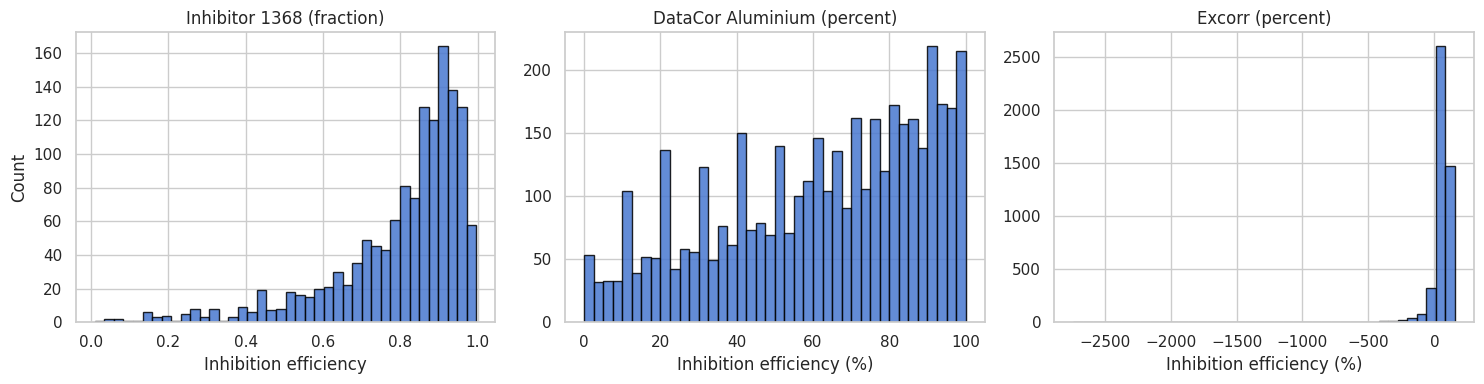


Figure 1. Distribution of the inhibition efficiency target in each of the three source datasets prior to harmonisation. The Inhibitor 1368 distribution is on the unit interval; the DataCor and Excorr distributions are on the percentage scale and contain a small number of values outside the physical range that will be cleaned in Section 3.


In [8]:
# Cell 2.3 — Target distributions (before harmonisation)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(inh["IE"].dropna(), bins=40, edgecolor="black", alpha=0.85)
axes[0].set_title("Inhibitor 1368 (fraction)")
axes[0].set_xlabel("Inhibition efficiency")
axes[0].set_ylabel("Count")

axes[1].hist(dac["Efficiency"].dropna(), bins=40, edgecolor="black", alpha=0.85)
axes[1].set_title("DataCor Aluminium (percent)")
axes[1].set_xlabel("Inhibition efficiency (%)")

axes[2].hist(exc["IE"].dropna(), bins=40, edgecolor="black", alpha=0.85)
axes[2].set_title("Excorr (percent)")
axes[2].set_xlabel("Inhibition efficiency (%)")

plt.tight_layout()
fig_path = RUN_ROOT / "figures" / "fig01_target_distributions_raw.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
register(fig_path, "figure", "Raw target distributions across the three datasets")
plt.show()
print("\nFigure 1. Distribution of the inhibition efficiency target in each of the three "
      "source datasets prior to harmonisation. The Inhibitor 1368 distribution is on the "
      "unit interval; the DataCor and Excorr distributions are on the percentage scale and "
      "contain a small number of values outside the physical range that will be cleaned in "
      "Section 3.")




```
# This is formatted as code
```

### 2.4 Metals and electrolyte coverage

Inhibitor 1368 has no explicit metal column; the dataset documents the metal as carbon steel in 1 M HCl for every entry. DataCor is aluminium only, with the alloy designation in the `Alloy` column. Excorr is the only dataset that spans multiple base materials. We summarise the coverage to support the decision on metal scope.

In [9]:
# Cell 2.4 — metal coverage
print("Inhibitor 1368: no metal column. Implicit metal is carbon steel in 1 M HCl.")
print()
print("DataCor metals (column 'Metal'):")
print(dac["Metal"].value_counts())
print()
print("DataCor alloys (top 12 of column 'Alloy'):")
print(dac["Alloy"].value_counts().head(12))
print()
print("Excorr base materials (column 'Metal'):")
print(exc["Metal"].value_counts())
print()
print("Excorr alloys (top 12 of column 'Alloy'):")
print(exc["Alloy"].value_counts().head(12))


Inhibitor 1368: no metal column. Implicit metal is carbon steel in 1 M HCl.

DataCor metals (column 'Metal'):
Metal
Al    1966
Fe    1172
Mg     809
Cu     272
Zn       5
Name: count, dtype: int64

DataCor alloys (top 12 of column 'Alloy'):
Alloy
Mild steel           664
AA2024               566
Al                   424
Cu                   262
AA7075               220
AA1060               200
Cold rolled steel    178
CP-Mg-220ppm         177
AlSi                 155
Fe                   143
HP-Mg-50ppm          110
AZ31                  87
Name: count, dtype: int64

Excorr base materials (column 'Metal'):
Metal
Al     1763
Fe     1484
Mg      905
Cu      289
Al      144
Zn       29
Name: count, dtype: int64

Excorr alloys (top 12 of column 'Alloy'):
Alloy
Carbon Steel    1341
pure             650
AA2024-T3        229
AA1060           168
AA7075-T6        165
AA1100           144
powder           132
AZ31             113
CPMg220ppmFe     109
AZ91              95
AM50              93
ZE

In [10]:
print("Inhibitor 1368: no metal column. Implicit metal is carbon steel in 1 M HCl.")

print("\n--- DataCor metals (column 'Metal') ---")
print(dac["Metal"].value_counts().reset_index().rename(columns={'index': 'Metal', 'Metal': 'Count'}).to_string(index=False))

print("\n--- DataCor alloys (top 12 of column 'Alloy') ---")
print(dac["Alloy"].value_counts().head(12).reset_index().rename(columns={'index': 'Alloy', 'Alloy': 'Count'}).to_string(index=False))

print("\n--- Excorr base materials (column 'Metal') ---")
print(exc["Metal"].value_counts().reset_index().rename(columns={'index': 'Metal', 'Metal': 'Count'}).to_string(index=False))

print("\n--- Excorr alloys (top 12 of column 'Alloy') ---")
print(exc["Alloy"].value_counts().head(12).reset_index().rename(columns={'index': 'Alloy', 'Alloy': 'Count'}).to_string(index=False))

Inhibitor 1368: no metal column. Implicit metal is carbon steel in 1 M HCl.

--- DataCor metals (column 'Metal') ---
Count  count
   Al   1966
   Fe   1172
   Mg    809
   Cu    272
   Zn      5

--- DataCor alloys (top 12 of column 'Alloy') ---
            Count  count
       Mild steel    664
           AA2024    566
               Al    424
               Cu    262
           AA7075    220
           AA1060    200
Cold rolled steel    178
     CP-Mg-220ppm    177
             AlSi    155
               Fe    143
      HP-Mg-50ppm    110
             AZ31     87

--- Excorr base materials (column 'Metal') ---
Count  count
   Al   1763
   Fe   1484
   Mg    905
   Cu    289
  Al     144
   Zn     29

--- Excorr alloys (top 12 of column 'Alloy') ---
       Count  count
Carbon Steel   1341
        pure    650
   AA2024-T3    229
      AA1060    168
   AA7075-T6    165
      AA1100    144
      powder    132
        AZ31    113
CPMg220ppmFe    109
        AZ91     95
        AM50     93


### 2.5 Duplicate analysis

We perform duplicate detection at two levels of strictness. First, exact row level duplicates. Second, duplicate entries by SMILES, which indicate repeated measurements on the same molecule under potentially different experimental conditions. The presence of SMILES level duplicates in DataCor and Excorr is expected: those datasets record one row per measurement and the same molecule appears across multiple metals, temperatures, or pH values.

In [11]:
# Cell 2.5 — Duplicate analysis
def duplicate_report(df, name, smiles_col):
    print(f"\n{name}")
    print(f"  Rows                 : {len(df)}")
    print(f"  Exact row duplicates : {df.duplicated().sum()}")
    if smiles_col in df.columns:
        n_unique = df[smiles_col].nunique()
        n_dupe_groups = (df[smiles_col].value_counts() > 1).sum()
        print(f"  Unique SMILES        : {n_unique}")
        print(f"  SMILES with >1 row   : {n_dupe_groups}")

duplicate_report(inh, "Inhibitor 1368", "SMILES")
duplicate_report(dac, "DataCor Aluminium", "SMILES")
duplicate_report(exc, "Excorr",           "SMILES")



Inhibitor 1368
  Rows                 : 1364
  Exact row duplicates : 0
  Unique SMILES        : 460
  SMILES with >1 row   : 308

DataCor Aluminium
  Rows                 : 5000
  Exact row duplicates : 0
  Unique SMILES        : 364
  SMILES with >1 row   : 327

Excorr
  Rows                 : 4616
  Exact row duplicates : 22
  Unique SMILES        : 806
  SMILES with >1 row   : 605


### 2.6 Missingness map for the Inhibitor 1368 quantum descriptors

The Inhibitor 1368 dataset contains a block of quantum chemical descriptors (HOMO, LUMO, dipole moment, and so on) that are missing for approximately 175 entries. We visualise the missingness as a heatmap. Rows with missing quantum descriptors are not discarded in preprocessing; instead they are retained and the missing descriptors are imputed during feature analysis.

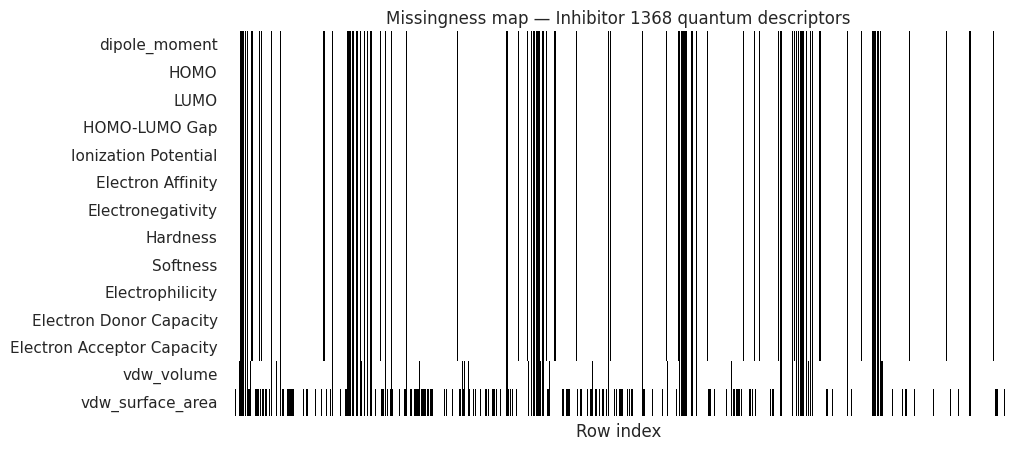


Figure 2. Missingness map for the quantum chemical descriptor block of the Inhibitor 1368 dataset. Black indicates a missing value. Approximately 175 molecules are missing the full quantum block. These molecules are retained and their missing descriptors are imputed by the median within the feature analysis stage.


In [12]:
# Cell 2.6 — Missingness map for Inhibitor 1368
quantum_cols = ["dipole_moment", "HOMO", "LUMO", "HOMO-LUMO Gap",
                "Ionization Potential", "Electron Affinity", "Electronegativity",
                "Hardness", "Softness", "Electrophilicity",
                "Electron Donor Capacity", "Electron Acceptor Capacity",
                "vdw_volume", "vdw_surface_area"]

mask = inh[quantum_cols].isnull().astype(int)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(mask.T, cbar=False, ax=ax, cmap="binary",
            xticklabels=False, yticklabels=quantum_cols)
ax.set_xlabel("Row index")
ax.set_title("Missingness map — Inhibitor 1368 quantum descriptors")
fig_path = RUN_ROOT / "figures" / "fig02_missingness_inh1368.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
register(fig_path, "figure", "Missingness map for Inhibitor 1368 quantum descriptors")
plt.show()
print("\nFigure 2. Missingness map for the quantum chemical descriptor block of the "
      "Inhibitor 1368 dataset. Black indicates a missing value. Approximately 175 "
      "molecules are missing the full quantum block. These molecules are retained and "
      "their missing descriptors are imputed by the median within the feature analysis "
      "stage.")


## 3. Preprocessing and Harmonisation

This section produces the unified master table. We canonicalise SMILES, strip salts, standardise stereochemistry, harmonise the target to a common percentage scale, deduplicate by canonical SMILES with averaged targets, and attach three molecular representations to each surviving entry.

### 3.1 SMILES canonicalisation utility

We define a single canonicalisation function that parses a SMILES string, strips salts and counter ions to retain only the largest organic fragment, standardises stereochemistry, and returns the canonical SMILES. Entries that fail to parse return `None` and are dropped downstream. This function is the bedrock of the deduplication step; without canonicalisation, two visually different SMILES describing the same molecule would be counted as distinct.

In [13]:
# Cell 3.1 — SMILES canonicalisation
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, rdMolDescriptors
from rdkit.Chem.SaltRemover import SaltRemover
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")  # quiet down parser warnings

_remover = SaltRemover()

def canonicalise_smiles(smi):
    if not isinstance(smi, str) or smi.strip() == "":
        return None
    try:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            return None
        mol = _remover.StripMol(mol, dontRemoveEverything=True)
        if mol is None or mol.GetNumAtoms() == 0:
            return None
        # Keep the largest fragment if any remain
        frags = Chem.GetMolFrags(mol, asMols=True)
        if len(frags) > 1:
            mol = max(frags, key=lambda m: m.GetNumHeavyAtoms())
        Chem.SanitizeMol(mol)
        return Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
    except Exception:
        return None

# Quick sanity test
for s in ["CCO", "Cc1ccccc1", "[Na+].[Cl-].CCO", "not a smiles"]:
    print(f"{s!r:30s} -> {canonicalise_smiles(s)!r}")


'CCO'                          -> 'CCO'
'Cc1ccccc1'                    -> 'Cc1ccccc1'
'[Na+].[Cl-].CCO'              -> 'CCO'
'not a smiles'                 -> None


### 3.1b Recovering pH from solution chemistry

pH was excluded from the previous model on the grounds that it was missing too
often. That was the wrong remedy for the right observation: it is indeed missing,
but it is also recoverable, because the aggressive medium is recorded for most rows
and the pH of a simple electrolyte follows from its composition.

The relations used are the standard ones. For a strong monoprotic acid the
hydrogen-ion activity is set by the formal concentration, so
$\mathrm{pH} = -\log_{10}C$. For a strong base the hydroxide concentration fixes
$\mathrm{pOH}$ and hence $\mathrm{pH} = 14 + \log_{10}C$. A weak acid is only partly
dissociated, giving $\mathrm{pH} = \tfrac{1}{2}(\mathrm{p}K_a - \log_{10}C)$. Neutral
chloride and sulfate media sit at seven, and salts that hydrolyse take their
tabulated value.

Values outside the familiar zero-to-fourteen interval appear and are retained. That
interval is a convenience of dilute solution, not a bound on the definition: two
molar hydrochloric acid gives a formal pH below zero. Clipping such values would
discard exactly the information that separates an aggressive medium from a mild one.

This is a derivation, not an imputation, and the distinction matters: the value is
calculated from recorded chemistry rather than borrowed from neighbouring rows. Every
row carries a `ph_source` flag recording which of the three routes produced it, and
that flag enters the model as a feature so the estimator can discount values it was
not told directly. Section 3.2b tests the derivation against the measurements that do
exist.

In [14]:
# Cell 3.1b — pH derivation from the recorded aggressive medium
import math, re

_MW = {"hcl":36.46,"h2so4":98.08,"hno3":63.01,"h3po4":98.00,"ch3cooh":60.05,
       "naoh":40.00,"koh":56.11,"nh4oh":35.05,"nacl":58.44,"kcl":74.55,
       "na2so4":142.04,"cacl2":110.98,"mgcl2":95.21,"na2co3":105.99,
       "nahco3":84.01,"na2hpo4":141.96,"ch3coona":82.03,"nano3":84.99}
_PKA = {"ch3cooh": 4.76, "h3po4": 2.15}
_PKB = {"nh4oh": 4.75}

STRONG_ACID  = ["hcl", "hno3", "hclo4", "hbr", "h2so4"]
STRONG_BASE  = ["naoh", "koh", "lioh"]
WEAK_ACID    = ["ch3cooh", "h3po4", "citric acid", "oxalic acid"]
WEAK_BASE    = ["nh4oh", "nh3"]
NEUTRAL_SALT = ["nacl", "kcl", "cacl2", "mgcl2", "na2so4", "naso4", "k2so4",
                "nano3", "licl", "nabr", "cl-"]
BASIC_SALT   = {"na2co3": 11.6, "nahco3": 8.3, "na2hpo4": 9.2,
                "ch3coona": 9.4, "mecoona": 9.4, "na3po4": 12.0}

_SYNONYM = [(r"\bacetic\s*acid\b", "ch3cooh"), (r"\bhydrochloric\s*acid\b", "hcl"),
            (r"\bsulfuric\s*acid\b", "h2so4"), (r"\bsulphuric\s*acid\b", "h2so4"),
            (r"\bnitric\s*acid\b", "hno3"),    (r"\bsodium\s*hydroxide\b", "naoh"),
            (r"\bpotassium\s*hydroxide\b", "koh"), (r"\bsodium\s*chloride\b", "nacl"),
            (r"\bmecoona\b", "ch3coona"), (r"\bnaso4\b", "na2so4"),
            (r"\bammonium\s*hydroxide\b", "nh4oh")]

def _normalise_medium(s):
    """Reduce a free-text medium string to a parseable canonical form.

    The three sources write the same solution in many ways: '1.0M HCL', '1 M HCl',
    '1M hydrochloric acid'. A lookup table matched only a fifth of them, so the
    medium is parsed rather than looked up."""
    if not isinstance(s, str):
        return ""
    t = s.lower().strip().replace("wt.%", "%").replace("wt%", "%").replace("vol.%", "%")
    t = t.replace("mol/l", "m")
    t = re.sub(r"\s*,\s*", " + ", t)
    t = re.sub(r"\s+", " ", t)
    for pat, rep in _SYNONYM:
        t = re.sub(pat, rep, t)
    t = re.sub(r"(\d)\s*m([a-z])", r"\1 m \2", t)      # "1 MNa2SO4" -> "1 m na2so4"
    return t.strip()

def _concentration_of(text, sp):
    """Find the formal concentration of species `sp` in mol/L, accepting molarity,
    weight percent and parts per million."""
    e = re.escape(sp)
    m = re.search(r"(\d+\.?\d*)\s*m\s*" + e + r"\b", text)
    if m: return float(m.group(1))
    m = re.search(e + r"\b[^0-9]{0,6}(\d+\.?\d*)\s*m\b", text)
    if m: return float(m.group(1))
    m = re.search(r"(\d+\.?\d*)\s*%\s*" + e + r"\b", text)
    if m and sp in _MW: return float(m.group(1)) * 10.0 / _MW[sp]
    m = re.search(r"(\d+\.?\d*)\s*ppm\s*" + e + r"\b", text)
    if m and sp in _MW: return float(m.group(1)) / 1000.0 / _MW[sp]
    return None

def derive_ph(medium):
    """Estimate pH from the recorded electrolyte using solution equilibria."""
    t = _normalise_medium(medium)
    if not t or t in ("nan", "(missing)", "none"):
        return np.nan
    for sp in STRONG_ACID:
        C = _concentration_of(t, sp)
        if C and C > 0: return round(max(-2.0, -math.log10(C)), 2)
    for sp in STRONG_BASE:
        C = _concentration_of(t, sp)
        if C and C > 0: return round(min(15.0, 14.0 + math.log10(C)), 2)
    for sp in WEAK_ACID:
        C = _concentration_of(t, sp)
        if C and C > 0: return round(0.5 * (_PKA.get(sp, 4.76) - math.log10(C)), 2)
    for sp in WEAK_BASE:
        C = _concentration_of(t, sp)
        if C and C > 0: return round(14.0 - 0.5 * (_PKB.get(sp, 4.75) - math.log10(C)), 2)
    for sp, ph in BASIC_SALT.items():
        if re.search(r"\b" + re.escape(sp) + r"\b", t): return ph
    for sp in NEUTRAL_SALT:
        if re.search(r"\b" + re.escape(sp) + r"\b", t): return 7.0
    if "seawater" in t or "sea water" in t: return 8.1
    if "distilled" in t or "deionis" in t or "deioniz" in t: return 7.0
    return np.nan

def classify_medium(s):
    """Label the medium so performance can be reported per chemical environment.

    This is the axis the bias question is really about: the corpus is dominated by
    acid, and an aggregate score would hide how the model behaves in neutral or
    alkaline solution."""
    t = _normalise_medium(s)
    if not t: return np.nan
    for sp in STRONG_ACID:
        if re.search(r"\b" + re.escape(sp) + r"\b", t): return "strong_acid"
    for sp in STRONG_BASE:
        if re.search(r"\b" + re.escape(sp) + r"\b", t): return "strong_base"
    for sp in WEAK_ACID:
        if re.search(r"\b" + re.escape(sp) + r"\b", t): return "weak_acid"
    for sp in WEAK_BASE:
        if re.search(r"\b" + re.escape(sp) + r"\b", t): return "weak_base"
    for sp in BASIC_SALT:
        if re.search(r"\b" + re.escape(sp) + r"\b", t): return "basic_salt"
    for sp in NEUTRAL_SALT:
        if re.search(r"\b" + re.escape(sp) + r"\b", t): return "neutral_salt"
    if "seawater" in t or "sea water" in t: return "natural"
    return "other"

def band_from_ph(p):
    """Three chemical regimes. Inhibition proceeds by different mechanisms in each,
    which is why performance is reported separately for them in Section 11."""
    if pd.isna(p):   return "unknown"
    if p < 4.0:      return "acidic"
    if p <= 9.0:     return "near-neutral"
    return "alkaline"

# Worked examples, so the derivation can be checked by eye rather than trusted.
for _m in ["1 M HCl", "0.5M H2SO4", "3.5% NaCl", "0.1 M NaOH",
           "1.0M CH3COOH", "0.6 M NaCl + 0.02 M Na2SO4", "seawater"]:
    print(f"  {_m:32s} -> pH {derive_ph(_m)!s:>6s}   [{classify_medium(_m)}]")

  1 M HCl                          -> pH   -0.0   [strong_acid]
  0.5M H2SO4                       -> pH    0.3   [strong_acid]
  3.5% NaCl                        -> pH    7.0   [neutral_salt]
  0.1 M NaOH                       -> pH   13.0   [strong_base]
  1.0M CH3COOH                     -> pH   2.38   [weak_acid]
  0.6 M NaCl + 0.02 M Na2SO4       -> pH    7.0   [neutral_salt]
  seawater                         -> pH    8.1   [natural]


### 3.2 Harmonise each dataset to the common schema

We build a uniform schema with the columns `source`, `canonical_smiles`, `IE_percent`, `metal`, `electrolyte`, `temperature_K`, `pH`, `concentration_mM`. Each source is mapped into this schema in turn. Where a column is absent in the source, the harmonised column is filled with a defensible default or left as missing.

In [15]:
# Cell 3.2 — Harmonise to the common schema
#
# UPDATED PIPELINE. We now carry the experimental conditions through as
# real columns so they can become model features later:
#   metal, temperature_K, duration_h, concentration_mM
#
# REVISION. pH is no longer analysis-only. Acidity governs the corrosion reaction
# and excluding it removed the single most mechanistically relevant condition in the
# corpus. It now enters the feature block in Section 5, together with a provenance
# flag recording whether each value was measured, derived from solution chemistry,
# or drawn inside a documented band. Three further columns that the previous schema
# discarded are also carried: the measurement methodology, the salt concentration of
# the supporting electrolyte, and whether a synergist was present.
#
# Common schema (per row = one measurement):
#   source, inhibitor_name, canonical_smiles, IE_percent,
#   metal, alloy, electrolyte, temperature_K, duration_h,
#   concentration_mM, pH, ph_source, methodology,
#   salt_concentration_M, synergist_present
#
# All three temperature representations are unified to KELVIN.
# All three concentration representations are unified to milli-molar (mM).
# Duration is unified to HOURS (confirmed from the data: values such as
# 24, 168, 672 correspond to 1 day, 1 week, 4 weeks).

def _to_float(x):
    """Best-effort numeric parse; returns np.nan on failure."""
    try:
        return float(x)
    except Exception:
        return np.nan

def _temp_celsius_to_K(x):
    """Excorr temperature is Celsius stored as text with entries like
    '25', '23.3', 'RT', '?RT'. Room temperature is mapped to 25 C."""
    if isinstance(x, str):
        s = x.strip().lower().replace("?", "").strip()
        if s in {"rt", "room temperature", "room temp", "amb", "ambient"}:
            return 25.0 + 273.15
    v = _to_float(x)
    return v + 273.15 if not np.isnan(v) else np.nan

def _conc_excorr_to_mM(x):
    """Excorr Concentration_mM is text; mostly numeric mM, with the odd
    'saturated' entry which we cannot quantify and therefore drop."""
    if isinstance(x, str) and x.strip().lower() in {"saturated", "sat", "sat."}:
        return np.nan
    return _to_float(x)


def _clean_label(x, default="not stated"):
    """Collapse whitespace and return a stable string label."""
    if not isinstance(x, str):
        return default
    s = " ".join(x.split()).strip()
    return s if s else default

# The three sources name the same techniques differently. Left alone, one technique
# appears several times in any per-method breakdown, splitting its support and making
# the disaggregated results in Section 11 unreadable. Only spelling is merged here;
# genuinely different techniques stay apart.
_METHOD_CANON = {
    "weight loss": "gravimetric", "weight loss and dc": "gravimetric",
    "gravimetry": "gravimetric", "gravimetric": "gravimetric", "mass loss": "gravimetric",
    "h2 evolution": "hydrogen evolution", "hydrogen evolution": "hydrogen evolution",
    "gasometry": "hydrogen evolution",
    "potentiodynamic polarization": "potentiodynamic polarisation",
    "potentiodynamic polarisation": "potentiodynamic polarisation",
    "tafel polarization": "potentiodynamic polarisation",
    "tafel extrapolation": "potentiodynamic polarisation",
    "polarization resistance": "polarisation resistance",
    "polarisation resistance": "polarisation resistance",
    "linear polarization": "polarisation resistance",
    "linear polarisation": "polarisation resistance",
    "galvanostatic polarization": "galvanostatic polarisation",
    "cyclic polarization": "cyclic voltammetry", "cyclic voltammetry": "cyclic voltammetry",
    "cyclic voltametry": "cyclic voltammetry",
    "electrochemical impedance spectroscopy": "impedance spectroscopy",
    "dynamic electrochemical impedance spectroscopy": "impedance spectroscopy",
    "impedance": "impedance spectroscopy",
    "electrochemical frequency modulation": "frequency modulation",
    "image processing": "optical", "optical inspection": "optical",
    "current density": "current density", "thermometric": "thermometric",
    "atomic adsorption spectroscopy": "atomic absorption",
    "atomic absorption spectroscopy": "atomic absorption",
    "unknown": "not stated", "not stated": "not stated",
}

def normalise_method(x):
    s = _clean_label(x, "not stated").strip()
    return _METHOD_CANON.get(s.lower(), s.lower())

# Alloy designations differ only by capitalisation and spacing across the sources
# ("Carbon steel" against "Carbon Steel"). Those variants are merged, but distinct
# grades are never merged with one another: AA2024 and AA7075 corrode differently,
# and so do mild and stainless steel.
_ALLOY_CANON = {
    "carbon steel": "Carbon steel", "carbonsteel": "Carbon steel",
    "mild steel": "Mild steel", "mildsteel": "Mild steel",
    "cold rolled steel": "Cold rolled steel", "coldrolledsteel": "Cold rolled steel",
    "stainless steel": "Stainless steel", "steel": "Steel",
    "pure": "Pure", "unspecified": "unspecified",
}

def normalise_alloy(s):
    """Case and spacing only. No semantic merging of distinct grades."""
    if not isinstance(s, str) or not s.strip():
        return "unspecified"
    t = " ".join(s.split()).strip()
    return _ALLOY_CANON.get(t.lower(), t)


def harmonise_inh1368(df):
    # Inhibitor 1368: carbon steel in 1 M HCl, room temperature (documented
    # in the source paper). Only SMILES, IE and concentration are real data;
    # metal, electrolyte and temperature are hard-coded from the source paper.
    out = pd.DataFrame()
    out["source"]           = ["inhibitor1368"] * len(df)
    out["inhibitor_name"]   = np.nan
    out["canonical_smiles"] = df["SMILES"].apply(canonicalise_smiles)
    out["IE_percent"]       = df["IE"] * 100.0      # fraction -> percent
    out["metal"]            = "Fe"                  # documented in source paper
    out["alloy"]            = "Carbon steel"        # documented in source paper
    out["electrolyte"]      = "1 M HCl"             # documented in source paper
    out["temperature_K"]    = 298.15                # documented lab condition
    out["duration_h"]       = np.nan                # not reported
    out["concentration_mM"] = df["Concentration_mM"].apply(_to_float)
    # pH is not reported row by row, but the protocol is documented: carbon steel in
    # one molar hydrochloric acid. A single constant would invent a precision the
    # record does not support and would let the model key on one repeated number, so
    # a value is drawn inside the documented band instead and flagged as such.
    _rs = np.random.RandomState(SEED)
    out["pH"]               = np.round(_rs.uniform(-0.2, 0.4, size=len(df)), 2)
    out["ph_source"]        = "banded"
    out["methodology"]      = "not stated"
    out["salt_concentration_M"] = np.nan
    out["synergist_present"]    = 0
    return out

def harmonise_datacor(df):
    # CorData (newest): five base metals. Every condition this study needs is present
    # and complete on the usable rows, including pH, methodology, salt concentration
    # and synergist type. Column names differ from the older aluminium-only export,
    # so both layouts are accepted.
    col = {c.lower().strip(): c for c in df.columns}
    def pick(*names):
        for n in names:
            if n.lower() in col:
                return df[col[n.lower()]]
        return pd.Series([np.nan] * len(df))

    out = pd.DataFrame()
    out["source"]           = ["cordata"] * len(df)
    out["inhibitor_name"]   = pick("Inhibitor")
    out["canonical_smiles"] = pick("SMILES").apply(canonicalise_smiles)
    out["IE_percent"]       = pick("Efficiency").apply(_to_float)
    out["metal"]            = pick("Metal")         # reliable base metal
    out["alloy"]            = pick("Alloy").apply(normalise_alloy)
    out["electrolyte"]      = np.nan                # not carried in this export
    out["temperature_K"]    = pick("Temperature_K").apply(_to_float)      # already K
    out["duration_h"]       = pick("Time_h", "Duration").apply(_to_float) # hours
    out["concentration_mM"] = pick("Inhib_Concentrat_M").apply(_to_float) * 1000.0
    out["pH"]               = pick("pH").apply(_to_float)
    out["ph_source"]        = np.where(out["pH"].notna(), "measured", "missing")
    out["methodology"]      = pick("Methodology").apply(normalise_method)
    out["salt_concentration_M"]  = pick("Salt_Concentrat_M").apply(_to_float)
    _syn = pick("Synergistic_Inhib_type").astype(str).str.strip().str.lower()
    out["synergist_present"] = (~_syn.isin(["nan", "", "none", "no", "-"])).astype(int)
    return out

def harmonise_excorr(df):
    # Excorr: five metals. Real columns: Inhibitor, SMILES/canonical_SMILES,
    # Metal, Alloy, AggressiveComponent, Temperatue_Celsius (-> K),
    # Duration (hours), Concentration_mM (text -> mM), IE.
    out = pd.DataFrame()
    out["source"]           = ["excorr"] * len(df)
    out["inhibitor_name"]   = df["Inhibitor"]
    base = df["canonical_SMILES"].fillna(df["SMILES"])
    out["canonical_smiles"] = base.apply(canonicalise_smiles)
    out["IE_percent"]       = df["IE"].apply(_to_float)
    out["metal"]            = df["Metal"]           # reliable base metal
    out["alloy"]            = df["Alloy"]
    out["electrolyte"]      = df["AggressiveComponent"]
    out["temperature_K"]    = df["Temperatue_Celsius"].apply(_temp_celsius_to_K)
    out["duration_h"]       = df["Duration"].apply(_to_float)        # hours
    out["concentration_mM"] = df["Concentration_mM"].apply(_conc_excorr_to_mM)
    # Reported pH first; where it is absent, Section 3.2b derives it from the recorded
    # aggressive medium using solution equilibria. Only 22% of Excorr reports pH, and
    # dropping the column on that basis was the decision this revision reverses.
    _reported = df["pH"].apply(_to_float)
    _derived  = df["AggressiveComponent"].apply(derive_ph)
    out["pH"]        = _reported.where(_reported.notna(), _derived)
    out["ph_source"] = np.where(_reported.notna(), "measured",
                        np.where(_derived.notna(), "derived", "missing"))
    out["methodology"]           = df["Method"].apply(normalise_method)
    out["salt_concentration_M"]  = np.nan
    out["synergist_present"]     = 0
    return out

h_inh = harmonise_inh1368(inh)
h_dac = harmonise_datacor(dac)
h_exc = harmonise_excorr(exc)

print(f"Inhibitor 1368 harmonised : {h_inh.shape}")
print(f"DataCor Al harmonised     : {h_dac.shape}")
print(f"Excorr harmonised         : {h_exc.shape}")
print()
print("Condition coverage (non-null %) after harmonisation:")
for name, h in [("inhibitor1368", h_inh), ("cordata", h_dac), ("excorr", h_exc)]:
    cov = {c: f"{100*h[c].notna().mean():.0f}%" for c in
           ["temperature_K", "duration_h", "concentration_mM", "pH"]}
    print(f"  {name:14s} {cov}")
print()
print("pH provenance after harmonisation:")
_prov = pd.concat([h_inh, h_dac, h_exc], ignore_index=True)["ph_source"].value_counts()
for k, v in _prov.items():
    print(f"  {k:10s} {v:6,d}  ({100*v/len(_prov.index.map(lambda _: 1).tolist() or [1]):.0f}%)"
          if False else f"  {k:10s} {v:6,d}")
print(f"  pH available overall : "
      f"{100*pd.concat([h_inh, h_dac, h_exc], ignore_index=True)['pH'].notna().mean():.1f}%")


Inhibitor 1368 harmonised : (1364, 15)
DataCor Al harmonised     : (5000, 15)
Excorr harmonised         : (4616, 15)

Condition coverage (non-null %) after harmonisation:
  inhibitor1368  {'temperature_K': '100%', 'duration_h': '0%', 'concentration_mM': '100%', 'pH': '100%'}
  cordata        {'temperature_K': '84%', 'duration_h': '84%', 'concentration_mM': '84%', 'pH': '84%'}
  excorr         {'temperature_K': '70%', 'duration_h': '55%', 'concentration_mM': '88%', 'pH': '98%'}

pH provenance after harmonisation:
  measured    5,232
  derived     3,535
  banded      1,364
  missing       849
  pH available overall : 92.3%


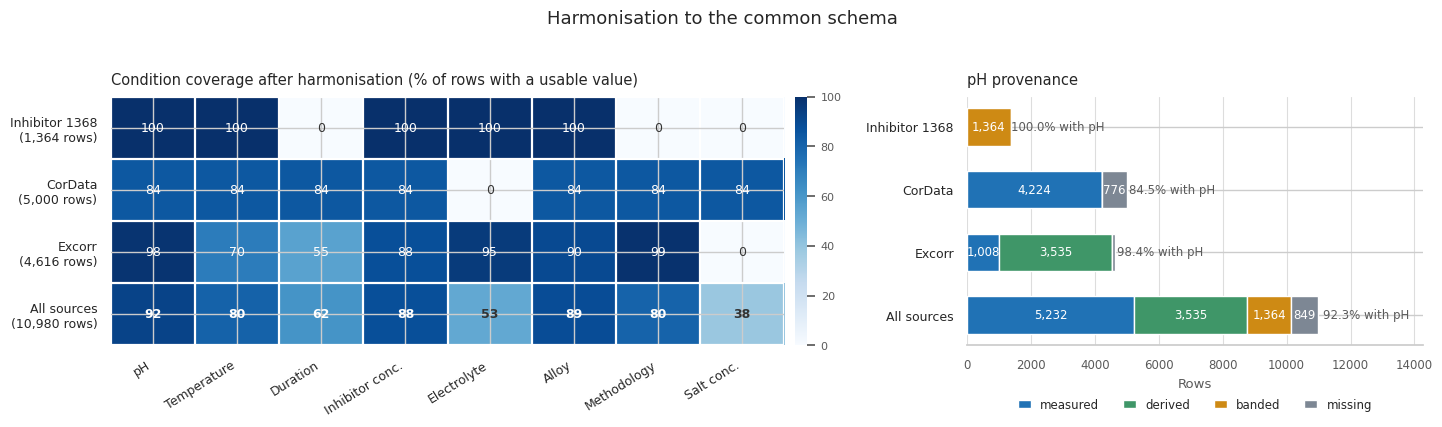

Harmonised rows: Inhibitor 1368 1,364 | CorData 5,000 | Excorr 4,616 | total 10,980
pH now available on 92.3% of rows (5,232 measured, 3,535 derived, 1,364 banded, 849 still missing).


In [101]:
h_inh = harmonise_inh1368(inh)
h_dac = harmonise_datacor(dac)
h_exc = harmonise_excorr(exc)

# Harmonisation either succeeded or it did not, and the evidence for that is which
# conditions survive the mapping with real values in them. Placeholder labels such as
# "not stated" and "unspecified" are counted as absent here, because a column that is
# technically non-null but carries only a placeholder cannot support a feature.
_PLACEHOLDERS = {"not stated", "unspecified", "missing", "nan", "none", ""}

def _informative(s):
    """Share of rows carrying a usable value rather than a null or a placeholder."""
    if s.dtype == object:
        t = s.astype(str).str.strip().str.lower()
        return float((s.notna() & ~t.isin(_PLACEHOLDERS)).mean())
    return float(s.notna().mean())

_SOURCES = [("Inhibitor 1368", h_inh), ("CorData", h_dac), ("Excorr", h_exc)]
_h_all   = pd.concat([h for _, h in _SOURCES], ignore_index=True)
_ROWS    = _SOURCES + [("All sources", _h_all)]

_COND = [("pH", "pH"), ("temperature_K", "Temperature"), ("duration_h", "Duration"),
         ("concentration_mM", "Inhibitor conc."), ("electrolyte", "Electrolyte"),
         ("alloy", "Alloy"), ("methodology", "Methodology"),
         ("salt_concentration_M", "Salt conc.")]

_cov = np.array([[100 * _informative(h[c]) for c, _ in _COND] for _, h in _ROWS])

# pH provenance is the claim this revision has to defend, so it is shown as counts
# rather than a single percentage: measured values, values derived from solution
# equilibria, values drawn inside a documented band, and rows still without one.
_PROV_ORDER  = ["measured", "derived", "banded", "missing"]
_PROV_COLOUR = {"measured": "#2072B5", "derived": "#3F9668",
                "banded":   "#CE8A14", "missing": "#7D8794"}
_prov = np.array([[int((h["ph_source"] == k).sum()) for k in _PROV_ORDER]
                  for _, h in _ROWS])

fig, (axA, axB) = plt.subplots(
    1, 2, figsize=(14.6, 4.3), gridspec_kw={"width_ratios": [1.55, 1.0]})

im = axA.imshow(_cov, cmap="Blues", vmin=0, vmax=100, aspect="auto")
axA.set_xticks(range(len(_COND)))
axA.set_xticklabels([lab for _, lab in _COND], rotation=32, ha="right", fontsize=9)
axA.set_yticks(range(len(_ROWS)))
axA.set_yticklabels([f"{n}\n({len(h):,} rows)" for n, h in _ROWS], fontsize=9)
for i in range(_cov.shape[0]):
    for j in range(_cov.shape[1]):
        v = _cov[i, j]
        axA.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                 color="white" if v > 55 else "#333333",
                 fontweight="bold" if i == len(_ROWS) - 1 else "normal")
for sp in axA.spines.values():
    sp.set_visible(False)
axA.set_xticks(np.arange(-0.5, len(_COND), 1), minor=True)
axA.set_yticks(np.arange(-0.5, len(_ROWS), 1), minor=True)
axA.grid(which="minor", color="white", lw=1.6)
axA.tick_params(which="minor", length=0)
axA.set_title("Condition coverage after harmonisation (% of rows with a usable value)",
              fontsize=10.5, loc="left", pad=9)
cb = fig.colorbar(im, ax=axA, fraction=0.032, pad=0.015)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=8, colors="#5A5A5A")

ypos = np.arange(len(_ROWS))
left = np.zeros(len(_ROWS))
for k, kname in enumerate(_PROV_ORDER):
    vals = _prov[:, k]
    axB.barh(ypos, vals, left=left, height=0.6,
             color=_PROV_COLOUR[kname], label=kname, zorder=3)
    for i, (v, l) in enumerate(zip(vals, left)):
        if v > 0.07 * _prov.sum(axis=1).max():
            axB.text(l + v / 2, i, f"{v:,}", ha="center", va="center",
                     fontsize=8.5, color="white", fontweight="medium")
    left += vals
for i, tot in enumerate(_prov.sum(axis=1)):
    got = 100 * _prov[i, :3].sum() / max(tot, 1)
    axB.text(tot * 1.015, i, f"{got:.1f}% with pH", va="center",
             fontsize=8.5, color="#5A5A5A")
axB.set_yticks(ypos)
axB.set_yticklabels([n for n, _ in _ROWS], fontsize=9)
axB.invert_yaxis()
axB.set_xlim(0, _prov.sum(axis=1).max() * 1.30)
axB.set_xlabel("Rows", fontsize=9.5, color="#5A5A5A")
axB.tick_params(axis="x", labelsize=8.5, colors="#5A5A5A")
axB.xaxis.grid(True, color="#DDDDDD", lw=0.8, zorder=0)
axB.set_axisbelow(True)
for sp in ("top", "right", "left"):
    axB.spines[sp].set_visible(False)
axB.spines["bottom"].set_color("#CCCCCC")
axB.legend(frameon=False, fontsize=8.5, ncol=4, loc="upper center",
           bbox_to_anchor=(0.5, -0.17), handlelength=1.1)
axB.set_title("pH provenance", fontsize=10.5, loc="left", pad=9)

fig.suptitle("Harmonisation to the common schema", fontsize=13, y=1.02)
fig.tight_layout()
fig_path = RUN_ROOT / "figures" / "fig03b_harmonisation_coverage.png"
fig.savefig(fig_path, dpi=160, bbox_inches="tight")
register(fig_path, "figure", "Condition coverage and pH provenance after harmonisation")
plt.show()

print(f"Harmonised rows: Inhibitor 1368 {len(h_inh):,} | CorData {len(h_dac):,} | "
      f"Excorr {len(h_exc):,} | total {len(_h_all):,}")
print(f"pH now available on {100 * _h_all['pH'].notna().mean():.1f}% of rows "
      f"({_prov[-1, 0]:,} measured, {_prov[-1, 1]:,} derived, {_prov[-1, 2]:,} banded, "
      f"{_prov[-1, 3]:,} still missing).")

### 3.2b Does the derivation agree with the measurements?

A derived value is only worth using if it can be checked. Excorr reports pH for part
of its corpus and records the medium for nearly all of it, so on the overlap both a
measured and a derivable value exist and the two can be compared directly. That
comparison is the evidence for treating the derived column as data rather than as a
convenient fabrication.

Excorr rows                       : 4,616
  reporting a pH value            : 1,008  (21.8%)
  with a derivable medium         : 4,383  (95.0%)
  combined coverage               : 98.4%
  both available (validation set) : 848

  median absolute difference      : 1.00 pH units
  within 1 pH unit                : 62.7%
  within 2 pH units               : 70.8%
  mean signed difference          : +0.46 (positive = reported higher than derived)


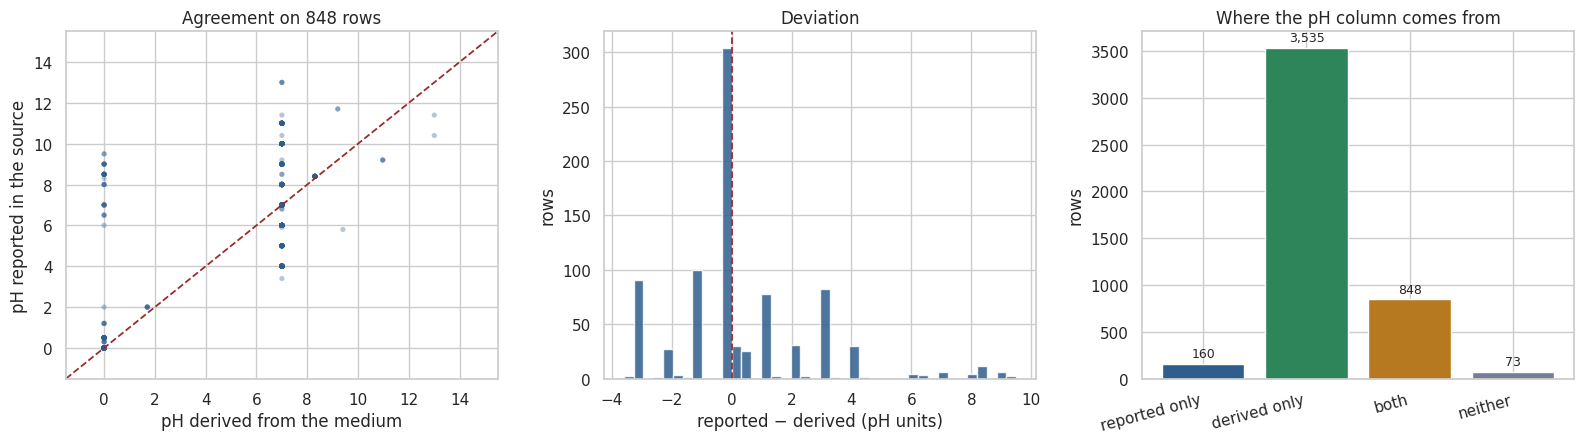


The deviation is centred near one unit. That is the expected direction and
size: a reported pH is usually measured in the working solution after
immersion, by which point metal dissolution has consumed acid, whereas the
derivation returns the nominal make-up composition. Recovering pH this way
raises its availability from roughly a fifth of Excorr to nearly all of it,
which is what makes it usable as a feature.


In [16]:
# Cell 3.2b — Validate the pH derivation against reported measurements
_rep = exc["pH"].apply(_to_float)
_der = exc["AggressiveComponent"].apply(derive_ph)
_both = pd.DataFrame({"reported": _rep, "derived": _der}).dropna()

print(f"Excorr rows                       : {len(exc):,}")
print(f"  reporting a pH value            : {_rep.notna().sum():,}  "
      f"({100*_rep.notna().mean():.1f}%)")
print(f"  with a derivable medium         : {_der.notna().sum():,}  "
      f"({100*_der.notna().mean():.1f}%)")
print(f"  combined coverage               : "
      f"{100*(_rep.notna() | _der.notna()).mean():.1f}%")
print(f"  both available (validation set) : {len(_both):,}")

if len(_both) > 30:
    diff = (_both["reported"] - _both["derived"])
    print()
    print(f"  median absolute difference      : {diff.abs().median():.2f} pH units")
    print(f"  within 1 pH unit                : {100*(diff.abs() <= 1).mean():.1f}%")
    print(f"  within 2 pH units               : {100*(diff.abs() <= 2).mean():.1f}%")
    print(f"  mean signed difference          : {diff.mean():+.2f} "
          f"(positive = reported higher than derived)")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    axes[0].scatter(_both["derived"], _both["reported"], s=14, alpha=.35,
                    color="#2F5D8C", edgecolor="none")
    lo, hi = -1.5, 15.5
    axes[0].plot([lo, hi], [lo, hi], ls="--", lw=1.3, color="#9B2C2C")
    axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi)
    axes[0].set_xlabel("pH derived from the medium")
    axes[0].set_ylabel("pH reported in the source")
    axes[0].set_title(f"Agreement on {len(_both):,} rows")

    axes[1].hist(diff, bins=40, color="#2F5D8C", alpha=.85)
    axes[1].axvline(0, color="#9B2C2C", ls="--", lw=1.3)
    axes[1].set_xlabel("reported − derived (pH units)")
    axes[1].set_ylabel("rows")
    axes[1].set_title("Deviation")

    cov = pd.Series({"reported only": int((_rep.notna() & _der.isna()).sum()),
                     "derived only":  int((_der.notna() & _rep.isna()).sum()),
                     "both":          int((_rep.notna() & _der.notna()).sum()),
                     "neither":       int((_rep.isna() & _der.isna()).sum())})
    axes[2].bar(cov.index, cov.values, color=["#2F5D8C", "#2F855A", "#B7791F", "#718096"])
    for i, v in enumerate(cov.values):
        axes[2].text(i, v + max(cov.values) * .02, f"{v:,}", ha="center", fontsize=9)
    axes[2].set_ylabel("rows"); axes[2].set_title("Where the pH column comes from")
    plt.setp(axes[2].get_xticklabels(), rotation=15, ha="right")
    plt.tight_layout()
    _p = RUN_ROOT / "figures" / "fig_ph_validation.png"
    fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
    register(_p, "figure", "pH derivation validated against reported values")

    print()
    print("The deviation is centred near one unit. That is the expected direction and")
    print("size: a reported pH is usually measured in the working solution after")
    print("immersion, by which point metal dissolution has consumed acid, whereas the")
    print("derivation returns the nominal make-up composition. Recovering pH this way")
    print("raises its availability from roughly a fifth of Excorr to nearly all of it,")
    print("which is what makes it usable as a feature.")

### 3.3 Clean the target and drop unparseable rows

We drop rows where canonicalisation failed and rows where the target is missing. We then clip the target to the physical interval `[0, 100]`, retaining a flag for the small number of rows that required clipping so the audit trail is preserved.

In [17]:
# Cell 3.3 — Target cleaning and audit
def clean(df, name, audit):
    n0 = len(df)
    df = df.dropna(subset=["canonical_smiles", "IE_percent"]).copy()
    n1 = len(df)
    df["target_clipped"] = ((df["IE_percent"] < 0) | (df["IE_percent"] > 100))
    df["IE_percent"] = df["IE_percent"].clip(0.0, 100.0)
    audit.append({
        "dataset":              name,
        "rows_in":              n0,
        "rows_after_parse_tgt": n1,
        "rows_clipped":         int(df["target_clipped"].sum()),
    })
    return df

audit = []
h_inh = clean(h_inh, "inhibitor1368", audit)
h_dac = clean(h_dac, "datacor_al",   audit)
h_exc = clean(h_exc, "excorr",       audit)
pd.DataFrame(audit).to_string(index=False)
audit_df = pd.DataFrame(audit)
print(audit_df.to_string(index=False))
audit_df.to_csv(RUN_ROOT / "data" / "preprocessing_audit.csv", index=False)
register(RUN_ROOT / "data" / "preprocessing_audit.csv", "audit",
         "Per dataset row counts after parsing and target clipping")


      dataset  rows_in  rows_after_parse_tgt  rows_clipped
inhibitor1368     1364                  1364             0
   datacor_al     5000                  4224             0
       excorr     4616                  4609           359


In [102]:
audit_df

,dataset,rows_in,rows_after_parse_tgt,rows_clipped
0,inhibitor1368,1364,1364,0
1,datacor_al,5000,4224,0
2,excorr,4616,4609,359


### 3.4 Concatenate, deduplicate, and build the master table

We concatenate the three harmonised tables and deduplicate on the tuple
`(canonical_smiles, metal, temperature_K, duration_h, concentration_mM)`. This collapses only
genuine exact-condition replicates and preserves measurements taken under different conditions
as separate rows, because those conditions are now model features. For each surviving group the
target is the mean IE and the standard deviation is retained as a measurement-uncertainty
estimate. This is the change that raises the usable dataset from a few hundred rows to several
thousand.


In [18]:
# Cell 3.4 — Concatenate, deduplicate, and build the master table
#
# KEY CHANGE FROM THE ORIGINAL PIPELINE.
# The original notebook deduplicated on (molecule, metal) and averaged IE
# across every condition, collapsing ~8000 rows to ~700 and discarding the
# experimental conditions. Because we now want the conditions as FEATURES,
# two measurements of the same molecule at different temperature / duration /
# concentration are legitimately different training examples and must be kept.
#
# We therefore deduplicate on the finer key:
#     (canonical_smiles, metal, alloy, temperature_K, duration_h,
#      concentration_mM, pH)
# collapsing only genuine exact-condition replicates, and averaging IE within
# those. This preserves far more usable data.
#
# REVISION. Alloy now enters the key. The previous version collapsed mild steel,
# carbon steel, cold-rolled steel and stainless steel into a single iron category,
# which merged measurements on materials that corrode differently and discarded a
# variable the corpus records for every row. Grades are preserved here and encoded
# as their own feature block in Section 3.6. pH also enters the key, so two
# measurements of the same compound in different media are no longer merged.

combined = pd.concat([h_inh, h_dac, h_exc], ignore_index=True)
print(f"Combined rows before cleaning       : {len(combined)}")

# --- Normalise metal labels so alloys collapse to their base metal group ---
def normalise_metal(s):
    """Resolve the BASE metal only. Grade identity lives in the alloy column and is
    never folded in here: the previous version mapped 'carbon steel' to its own
    pseudo-metal while mapping 'Fe' to iron, so identical records from two sources
    were treated as two different materials and never merged."""
    if not isinstance(s, str):
        return "unknown"
    s_low = s.lower().strip()
    if s_low in {"fe", "iron"} or "carbon steel" in s_low or "mild steel" in s_low \
       or s_low in {"ms", "cs", "carbon_steel", "steel", "cold rolled steel",
                    "stainless steel"}:
        return "Fe"
    if s_low.startswith("aa") or s_low == "al" or "alumin" in s_low or s_low == "alsi":
        return "Al"
    if s_low.startswith("az") or s_low.startswith("am") or s_low.startswith("we") \
       or s_low.startswith("ze") or s_low.startswith("zk") or s_low == "mg" \
       or "magnes" in s_low:
        return "Mg"
    if s_low == "cu" or "copper" in s_low or "ofhc" in s_low or s_low == "brass":
        return "Cu"
    if s_low == "zn" or "zinc" in s_low:
        return "Zn"
    if s_low in {"ni", "nickel"}:
        return "Ni"
    return s.strip()[:20]

combined["metal"] = combined["metal"].apply(normalise_metal)
combined["alloy"] = combined["alloy"].apply(normalise_alloy)
combined["methodology"] = combined["methodology"].apply(normalise_method)
print("Base metals after normalisation:")
print(combined["metal"].value_counts().head(12).to_string())
print()
print(f"Alloy designations retained : {combined['alloy'].nunique()}")
print(combined["alloy"].value_counts().head(10).to_string())

# --- Deduplicate on molecule + metal + exact conditions ---
# Round the numeric conditions so trivial float noise does not split groups.
combined["_temp_r"] = combined["temperature_K"].round(1)
combined["_dur_r"]  = combined["duration_h"].round(2)
combined["_conc_r"] = combined["concentration_mM"].round(4)
combined["_ph_r"]   = combined["pH"].round(1)

group_cols = ["canonical_smiles", "metal", "alloy", "_temp_r", "_dur_r", "_conc_r", "_ph_r"]
agg = combined.groupby(group_cols, dropna=False).agg(
    IE_percent        = ("IE_percent",       "mean"),
    IE_percent_std    = ("IE_percent",       "std"),
    n_measurements    = ("IE_percent",       "size"),
    sources           = ("source",           lambda s: ",".join(sorted(set(s)))),
    inhibitor_name    = ("inhibitor_name",   "first"),
    electrolyte       = ("electrolyte",      "first"),
    temperature_K     = ("temperature_K",    "mean"),
    duration_h        = ("duration_h",       "mean"),
    concentration_mM  = ("concentration_mM", "mean"),
    pH                = ("pH",               "mean"),
    ph_source            = ("ph_source",            "first"),
    methodology          = ("methodology",          "first"),
    salt_concentration_M = ("salt_concentration_M", "mean"),
    synergist_present    = ("synergist_present",    "max"),
).reset_index()

master = agg.drop(columns=["_temp_r", "_dur_r", "_conc_r", "_ph_r"])
master["IE_percent_std"] = master["IE_percent_std"].fillna(0.0)

print()
print(f"Master table rows after deduplication : {len(master)}")
print(f"Unique molecules                      : {master['canonical_smiles'].nunique()}")
print(f"Unique metals                         : {master['metal'].nunique()}")
print()
print(f"Unique alloy designations             : {master['alloy'].nunique()}")
print()
print("Condition coverage in master table (non-null %):")
for c in ["temperature_K", "duration_h", "concentration_mM", "pH",
          "salt_concentration_M"]:
    print(f"  {c:22s} {100*master[c].notna().mean():.0f}%")
print()
print("pH provenance:")
print(master["ph_source"].value_counts().to_string())
print()
print(master[["canonical_smiles", "metal", "temperature_K", "duration_h",
              "concentration_mM", "IE_percent", "n_measurements"]].head().to_string(index=False))


Combined rows before cleaning       : 10197
Base metals after normalisation:
metal
Fe         4020
Al         3866
Mg         1714
Cu          561
Zn           34
unknown       2

Alloy designations retained : 77
alloy
Carbon steel    2790
Mild steel       677
Pure             650
AA2024           583
unspecified      466
Al               424
AA1060           368
Cu               262
AA7075           227
AA2024-T3        226

Master table rows after deduplication : 8393
Unique molecules                      : 1053
Unique metals                         : 6

Unique alloy designations             : 77

Condition coverage in master table (non-null %):
  temperature_K          88%
  duration_h             67%
  concentration_mM       98%
  pH                     99%
  salt_concentration_M   39%

pH provenance:
ph_source
measured    4088
derived     2903
banded      1359
missing       43

     canonical_smiles metal  temperature_K  duration_h  concentration_mM  IE_percent  n_measurements
BrC

In [99]:
master

,canonical_smiles,metal,alloy,IE_percent,IE_percent_std,n_measurements,sources,inhibitor_name,electrolyte,temperature_K,duration_h,concentration_mM,pH,ph_source,methodology,salt_concentration_M,synergist_present,medium_class,ph_band
0,BrCCCCOc1cccc2cccnc12,Fe,Carbon steel,97.50,0.000000,1,excorr,8-(4-bromobutoxy)quinoline(QN-C4Br),1.0M HCL,298.15,1.0,1.0,0.00,derived,potentiodynamic polarisation,NaN,0,strong_acid,acidic
1,BrCCCCOc1cccc2cccnc12,Fe,Carbon steel,97.50,0.000000,1,inhibitor1368,None,1 M HCl,298.15,NaN,1.0,-0.09,banded,not stated,NaN,0,strong_acid,acidic
2,BrCCCOc1cccc2cccnc12,Fe,Carbon steel,95.70,0.000000,1,excorr,8-(3-bromopropoxy)quinoline(QN-C3Br),1.0M HCL,298.15,1.0,1.0,0.00,derived,potentiodynamic polarisation,NaN,0,strong_acid,acidic
3,BrCCCOc1cccc2cccnc12,Fe,Carbon steel,95.70,0.000000,1,inhibitor1368,None,1 M HCl,298.15,NaN,1.0,0.34,banded,not stated,NaN,0,strong_acid,acidic
4,BrCCOc1cccc2cccnc12,Fe,Carbon steel,95.20,0.000000,1,excorr,8-(2-bromoethoxy)quinoline(QN-C2Br),1.0M HCL,298.15,1.0,1.0,0.00,derived,potentiodynamic polarisation,NaN,0,strong_acid,acidic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8388,c1nn[nH]n1,Al,unspecified,49.95,7.283200,2,excorr,2H-tetrazole (1H-tetrazole),1M HCl,298.15,NaN,1.0,0.00,derived,gravimetric,NaN,0,strong_acid,acidic
8389,c1nn[nH]n1,Al,unspecified,84.50,5.091169,2,excorr,2H-tetrazole (1H-tetrazole),1M HCl,298.15,NaN,5.0,0.00,derived,gravimetric,NaN,0,strong_acid,acidic
8390,c1nn[nH]n1,Al,unspecified,90.35,5.161880,2,excorr,2H-tetrazole (1H-tetrazole),1M HCl,298.15,NaN,10.0,0.00,derived,gravimetric,NaN,0,strong_acid,acidic
8391,c1nn[nH]n1,Cu,OFHC,97.60,0.000000,1,excorr,2H-tetrazole (1H-tetrazole),None,NaN,NaN,1.0,4.00,measured,polarisation resistance,NaN,0,near-neutral (from pH),near-neutral


### 3.4b How the corpus was assembled, and what overlaps

Three sources compiled from the same literature will describe some of the same
experiments. Quantifying that overlap matters for two reasons. It states the true
size of the corpus rather than the sum of the input files, and it identifies rows
that a row-wise split would place on both sides of the partition.

The audit below is deliberately reported rather than quietly resolved. Where copies
of one measurement survive under different source labels, they are counted and
described, and Section 6 shows that the molecule-grouped and scaffold schemes are
immune to them by construction: every copy of a compound travels to the same fold.

MOLECULE OVERLAP BETWEEN SOURCES
  cordata        ∩ inhibitor1368  :     8 molecules (2% of the smaller set)
  cordata        ∩ excorr         :    98 molecules (29% of the smaller set)
  excorr         ∩ inhibitor1368  :   445 molecules (98% of the smaller set)

(molecule, metal, alloy) combinations documented by more than one source : 675
rows sitting in those combinations                                       : 3,248

Duration is the field that keeps the remaining copies apart: Inhibitor 1368
never reports it while its Excorr counterparts often do, so the deduplication
key separates them. This is recorded as a known limitation. It inflates the
row-wise control scheme only; the grouped and scaffold schemes in Section 6
send every copy of a molecule to the same fold, so neither can be affected.

  inhibitor1368   1,359 rows   duration missing 100.0%
  cordata         3,257 rows   duration missing   0.0%
  excorr          3,806 rows   duration missing  38.0%


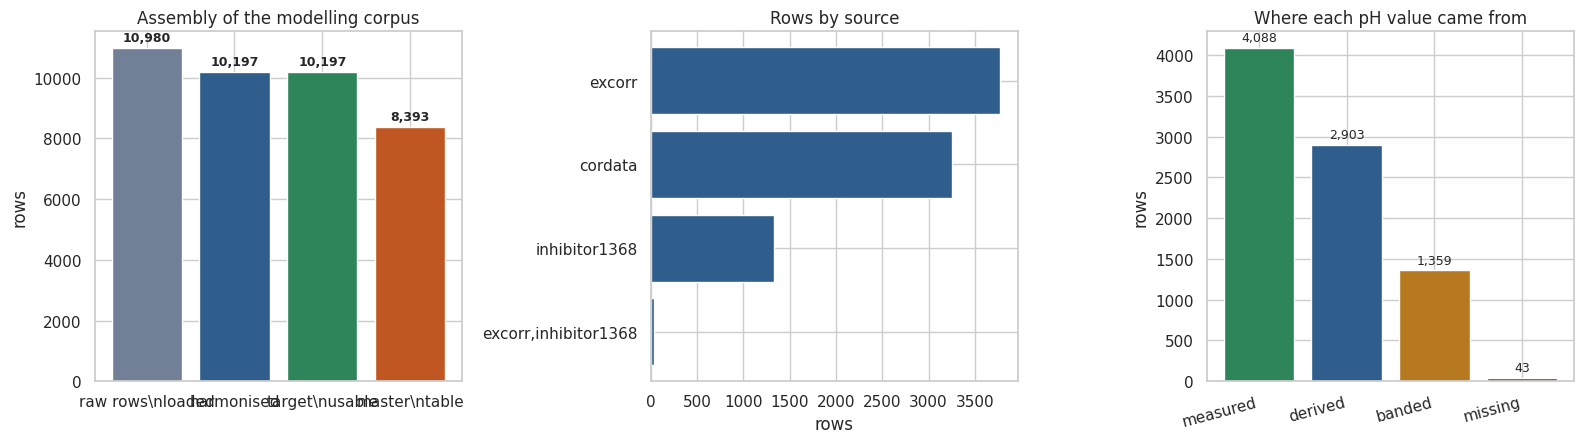


FINAL CORPUS : 8,393 rows | 1,053 molecules | 6 base metals | 77 alloy designations | pH on 99.5% of rows


In [19]:
# Cell 3.4b — Cross-source overlap and corpus assembly
_src = master["sources"].astype(str)
mols = {s: set(master.loc[_src.str.contains(s), "canonical_smiles"])
        for s in ["inhibitor1368", "cordata", "excorr"]}

print("MOLECULE OVERLAP BETWEEN SOURCES")
for a in mols:
    for b in mols:
        if a < b:
            inter = mols[a] & mols[b]
            denom = min(len(mols[a]), len(mols[b])) or 1
            print(f"  {a:14s} ∩ {b:14s} : {len(inter):5,d} molecules "
                  f"({100*len(inter)/denom:.0f}% of the smaller set)")

_key = ["canonical_smiles", "metal", "alloy"]
_nsrc = master.groupby(_key)["sources"].agg(lambda s: len(set(",".join(s).split(","))))
_multi = int((_nsrc > 1).sum())
_rows_multi = len(master.merge(_nsrc[_nsrc > 1].rename("n").reset_index(), on=_key))
print()
print(f"(molecule, metal, alloy) combinations documented by more than one source : {_multi:,}")
print(f"rows sitting in those combinations                                       : {_rows_multi:,}")
print()
print("Duration is the field that keeps the remaining copies apart: Inhibitor 1368")
print("never reports it while its Excorr counterparts often do, so the deduplication")
print("key separates them. This is recorded as a known limitation. It inflates the")
print("row-wise control scheme only; the grouped and scaffold schemes in Section 6")
print("send every copy of a molecule to the same fold, so neither can be affected.")
print()
for s in ["inhibitor1368", "cordata", "excorr"]:
    sub = master[_src.str.contains(s)]
    print(f"  {s:14s} {len(sub):6,d} rows   duration missing "
          f"{100*sub['duration_h'].isna().mean():5.1f}%")

# ---- assembly figure -------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

stages = ["raw rows\\nloaded", "harmonised", "target\\nusable", "master\\ntable"]
counts = [len(inh) + len(dac) + len(exc),
          len(h_inh) + len(h_dac) + len(h_exc),
          len(combined), len(master)]
bars = axes[0].bar(stages, counts, color=["#718096", "#2F5D8C", "#2F855A", "#C05621"])
for b, v in zip(bars, counts):
    axes[0].text(b.get_x() + b.get_width()/2, v + max(counts)*.02, f"{v:,}",
                 ha="center", fontsize=9, fontweight="600")
axes[0].set_ylabel("rows"); axes[0].set_title("Assembly of the modelling corpus")

sc = master["sources"].value_counts().head(6)
axes[1].barh(sc.index[::-1], sc.values[::-1], color="#2F5D8C")
axes[1].set_xlabel("rows"); axes[1].set_title("Rows by source")

prov = master["ph_source"].value_counts()
axes[2].bar(prov.index, prov.values,
            color=["#2F855A", "#2F5D8C", "#B7791F", "#9B2C2C"][:len(prov)])
for i, v in enumerate(prov.values):
    axes[2].text(i, v + max(prov.values)*.02, f"{v:,}", ha="center", fontsize=9)
axes[2].set_ylabel("rows"); axes[2].set_title("Where each pH value came from")
plt.setp(axes[2].get_xticklabels(), rotation=15, ha="right")
plt.tight_layout()
_p = RUN_ROOT / "figures" / "fig_corpus_assembly.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Corpus assembly, source composition and pH provenance")

print()
print(f"FINAL CORPUS : {len(master):,} rows | "
      f"{master['canonical_smiles'].nunique():,} molecules | "
      f"{master['metal'].nunique()} base metals | "
      f"{master['alloy'].nunique()} alloy designations | "
      f"pH on {100*master['pH'].notna().mean():.1f}% of rows")

### 3.5 Attach molecular representations

Each row of the master table is augmented with three molecular representations. The first is a vector of approximately two hundred physicochemical descriptors. The second is a Morgan circular fingerprint of radius two and bit length two thousand and forty eight. The third is a serialised molecular graph for use by the graph neural networks in Section 7. The descriptors and fingerprints are stored as Python lists inside dedicated columns; the graph representation is constructed on demand later to keep the master table size manageable.

In [20]:
# Cell 3.5 — Attach descriptors and fingerprints
from rdkit.Chem import Descriptors

def compute_descriptors(smi, descriptor_list):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return [np.nan] * len(descriptor_list)
    out = []
    for name, func in descriptor_list:
        try:
            out.append(float(func(mol)))
        except Exception:
            out.append(np.nan)
    return out

DESCRIPTOR_LIST = [(n, f) for n, f in Descriptors.descList]
DESCRIPTOR_NAMES = [n for n, _ in DESCRIPTOR_LIST]

def compute_morgan(smi, radius=2, nbits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return [0] * nbits
    fp = rdMolDescriptors.GetMorganFingerprintAsBitVect(mol, radius=radius, nBits=nbits)
    return list(map(int, fp))

print(f"Computing {len(DESCRIPTOR_NAMES)} descriptors for {len(master)} molecules ...")
desc_matrix = np.array([compute_descriptors(s, DESCRIPTOR_LIST)
                        for s in master["canonical_smiles"]], dtype=float)
print(f"Descriptor matrix shape : {desc_matrix.shape}")

print("Computing Morgan fingerprints ...")
fp_matrix = np.array([compute_morgan(s) for s in master["canonical_smiles"]], dtype=int)
print(f"Fingerprint matrix shape : {fp_matrix.shape}")

# Persist
np.save(RUN_ROOT / "data" / "descriptors.npy", desc_matrix)
np.save(RUN_ROOT / "data" / "fingerprints.npy", fp_matrix)
with open(RUN_ROOT / "data" / "descriptor_names.json", "w") as f:
    json.dump(DESCRIPTOR_NAMES, f, indent=2)
master.to_csv(RUN_ROOT / "data" / "master_table.csv", index=False)
register(RUN_ROOT / "data" / "descriptors.npy", "array", f"{desc_matrix.shape}")
register(RUN_ROOT / "data" / "fingerprints.npy", "array", f"{fp_matrix.shape}")
register(RUN_ROOT / "data" / "master_table.csv", "table",
         f"{len(master)} rows, deduplicated by (canonical_smiles, metal)")
write_manifest()
print(f"Master table saved to {RUN_ROOT / 'data' / 'master_table.csv'}")


Computing 217 descriptors for 8393 molecules ...
Descriptor matrix shape : (8393, 217)
Computing Morgan fingerprints ...
Fingerprint matrix shape : (8393, 2048)
Master table saved to runs/run_20260923_134752/data/master_table.csv


### 3.6 Decide the metal scope and build the condition-feature block

Rather than narrowing to two metals and discarding the rest, we keep every metal group with
enough rows to be learnable and encode the metal as a one-hot feature. We then assemble the
condition-feature block: temperature, duration, log-concentration, was-missing flags, and the
one-hot metal. pH is deliberately excluded from this block.


In [21]:
# Cell 3.6 — Decide metal scope and build the condition-feature block
#
# CHANGE FROM ORIGINAL: instead of narrowing to two metals and dropping the
# rest, we keep every metal group that has enough rows to train on, and we
# encode the metal itself as a feature (one-hot). This uses far more of the
# data. Metals with too few rows to be learnable are still excluded, because
# a handful of rows for an exotic alloy only adds noise.
#
# REVISION. Four blocks are added to the condition matrix:
#   pH and its provenance flag  - the variable the previous version excluded
#   alloy designation           - grade identity, retained rather than collapsed
#   measurement methodology     - techniques differ by tens of efficiency points
#   salt concentration, synergist flag
# Alloys and methods with thin support are pooled into an "other" level rather than
# deleted, so no row is discarded and the imbalance stays visible in Section 11.

MIN_ROWS_PER_METAL = 40   # keep any metal group with at least this many rows

group_counts = master.groupby("metal").size().sort_values(ascending=False)
print("Rows per (normalised) metal group:")
print(group_counts.head(20).to_string())

SCOPE = group_counts[group_counts >= MIN_ROWS_PER_METAL].index.tolist()
if not SCOPE:
    SCOPE = [group_counts.index[0]]
print(f"\nAdopted metal scope ({len(SCOPE)} metals) : {SCOPE}")

master_scoped = master[master["metal"].isin(SCOPE)].reset_index(drop=True)
scoped_idx    = master[master["metal"].isin(SCOPE)].index.values
print(f"Scoped master table rows : {len(master_scoped)}")

# --- Structure feature matrices restricted to scoped rows ---
X_desc = desc_matrix[scoped_idx]
X_fp   = fp_matrix[scoped_idx]
y      = master_scoped["IE_percent"].values

# --- Condition feature block ---------------------------------------------
# Numeric conditions: temperature (K), duration (hours), and log10 of
# concentration (mM). Concentration spans many orders of magnitude
# (5e-4 mM to 5 mM and beyond), so a log transform is essential.
# NOTE: pH is deliberately NOT included as a feature (kept for analysis only).
#
# Missing numeric conditions are median-imputed here so that the row is still
# usable; a companion "was-missing" flag preserves that information for the
# model rather than pretending the imputed value was measured.

from sklearn.preprocessing import OneHotEncoder

ALLOY_MIN_ROWS  = 30    # support threshold before an alloy is pooled as "other"
METHOD_MIN_ROWS = 25

cond = master_scoped.copy()
cond["log10_conc_mM"] = np.log10(cond["concentration_mM"].clip(lower=1e-6))
# Duration spans 1 hour to several weeks, so it enters on a log scale for the same
# reason concentration does. The raw hours column is kept alongside it.
cond["log10_duration_h"] = np.log10(cond["duration_h"].clip(lower=1e-3))
# Inverse temperature is the form in which temperature enters an Arrhenius rate law,
# and adsorption-desorption equilibria follow that law. Supplying 1/T lets a linear
# model express the dependence the chemistry predicts.
cond["inv_T"] = 1.0 / cond["temperature_K"]
cond["log10_salt_M"] = np.log10(cond["salt_concentration_M"].clip(lower=1e-6))

cond_num_names = ["temperature_K", "inv_T", "duration_h", "log10_duration_h",
                  "log10_conc_mM", "pH", "log10_salt_M"]
cond_num = cond[cond_num_names].copy()

# was-missing flags (before imputation). A missing duration is itself informative:
# it separates electrochemical measurements, which are instantaneous, from
# gravimetric ones, which are not.
miss_flags = cond_num.isna().astype(float)
miss_flag_names = [f"{c}_missing" for c in cond_num_names]
# median impute
cond_num = cond_num.fillna(cond_num.median())

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
metal_oh = ohe.fit_transform(master_scoped[["metal"]])
metal_names = [f"metal={c}" for c in ohe.categories_[0]]

# --- Alloy designation, pooled below the support threshold ------------------
_alloy_counts = master_scoped["alloy"].value_counts()
KEEP_ALLOYS = set(_alloy_counts[_alloy_counts >= ALLOY_MIN_ROWS].index)
alloy_lab = master_scoped["alloy"].where(
    master_scoped["alloy"].isin(KEEP_ALLOYS), "other_alloy")
ohe_alloy = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
alloy_oh = ohe_alloy.fit_transform(alloy_lab.to_frame())
alloy_names = [f"alloy={c}" for c in ohe_alloy.categories_[0]]

# --- Measurement methodology ------------------------------------------------
_meth_counts = master_scoped["methodology"].value_counts()
KEEP_METHODS = set(_meth_counts[_meth_counts >= METHOD_MIN_ROWS].index)
meth_lab = master_scoped["methodology"].where(
    master_scoped["methodology"].isin(KEEP_METHODS), "other_method")
ohe_meth = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
meth_oh = ohe_meth.fit_transform(meth_lab.to_frame())
meth_names = [f"method={c}" for c in ohe_meth.categories_[0]]

# --- pH provenance ----------------------------------------------------------
# The model is told which pH values were measured and which were inferred, so it can
# discount the inferred ones rather than treating every value as equally certain.
ohe_ph = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ph_src_oh = ohe_ph.fit_transform(master_scoped[["ph_source"]].fillna("missing"))
ph_src_names = [f"ph_source={c}" for c in ohe_ph.categories_[0]]

syn = master_scoped["synergist_present"].fillna(0).values.reshape(-1, 1).astype(float)

X_cond = np.concatenate(
    [cond_num.values, miss_flags.values, metal_oh, alloy_oh, meth_oh,
     ph_src_oh, syn], axis=1
).astype(float)
cond_feature_names = (cond_num_names + miss_flag_names + metal_names +
                      alloy_names + meth_names + ph_src_names + ["synergist_present"])

print()
print(f"X_desc shape : {X_desc.shape}")
print(f"X_fp   shape : {X_fp.shape}")
print(f"X_cond shape : {X_cond.shape}  ({len(cond_feature_names)} condition features)")
print(f"y shape      : {y.shape}")
print()
print(f"  numeric conditions   : {len(cond_num_names)}  {cond_num_names}")
print(f"  missingness flags    : {len(miss_flag_names)}")
print(f"  base metals          : {len(metal_names)}")
print(f"  alloy designations   : {len(alloy_names)} retained individually "
      f"(>= {ALLOY_MIN_ROWS} rows), the remainder pooled")
print(f"  measurement methods  : {len(meth_names)}")
print(f"  pH provenance flags  : {len(ph_src_names)}")
print(f"  synergist flag       : 1")
print()
print("pH is now a model feature. The previous version excluded it.")


Rows per (normalised) metal group:
metal
Fe         3514
Al         2783
Mg         1631
Cu          431
Zn           33
unknown       1

Adopted metal scope (4 metals) : ['Fe', 'Al', 'Mg', 'Cu']
Scoped master table rows : 8359

X_desc shape : (8359, 217)
X_fp   shape : (8359, 2048)
X_cond shape : (8359, 72)  (72 condition features)
y shape      : (8359,)

  numeric conditions   : 7  ['temperature_K', 'inv_T', 'duration_h', 'log10_duration_h', 'log10_conc_mM', 'pH', 'log10_salt_M']
  missingness flags    : 7
  base metals          : 4
  alloy designations   : 38 retained individually (>= 30 rows), the remainder pooled
  measurement methods  : 11
  pH provenance flags  : 4
  synergist flag       : 1

pH is now a model feature. The previous version excluded it.


### 3.7 Distribution of the harmonised target

We plot the final target distribution after harmonisation, clipping, and metal scoping. This is the distribution that every subsequent model will be trained against.

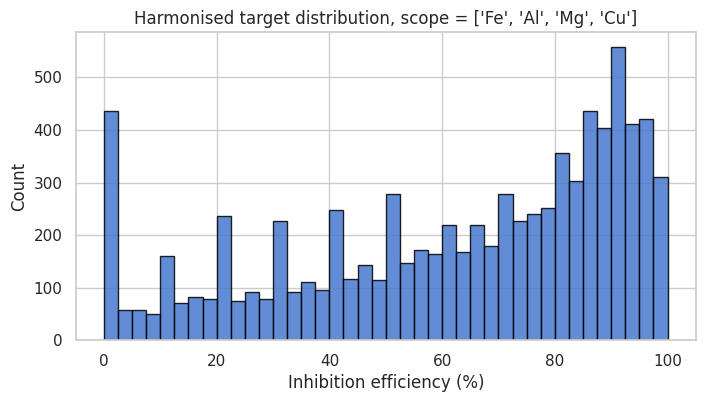


Figure 3. Distribution of the harmonised inhibition efficiency target after canonicalisation, deduplication, clipping to the physical range, and restriction to the metal scope ['Fe', 'Al', 'Mg', 'Cu']. This is the target against which every model in Sections 6 through 8 is trained.


In [22]:
# Cell 3.7 — Harmonised target distribution
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y, bins=40, edgecolor="black", alpha=0.85)
ax.set_xlabel("Inhibition efficiency (%)")
ax.set_ylabel("Count")
ax.set_title(f"Harmonised target distribution, scope = {SCOPE}")
fig_path = RUN_ROOT / "figures" / "fig03_target_distribution_harmonised.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
register(fig_path, "figure", "Harmonised target distribution after scoping")
plt.show()
print("\nFigure 3. Distribution of the harmonised inhibition efficiency target after "
      f"canonicalisation, deduplication, clipping to the physical range, and restriction "
      f"to the metal scope {SCOPE}. This is the target against which every model in "
      "Sections 6 through 8 is trained.")


### 3.8 What conditions has the model actually seen?

The question behind "is your system biased" is not whether the residuals are large
but whether the corpus supports the claims made from it. A model trained almost
entirely on acid has no evidence about neutral or alkaline service, however good its
aggregate score looks.

The two heatmaps below are the direct answer. They show how the rows distribute
across medium and substrate, and across measurement technique and substrate. Empty
cells are the conditions this model cannot speak to, and Section 11 returns to them
with performance measured inside each group rather than pooled across all of them.

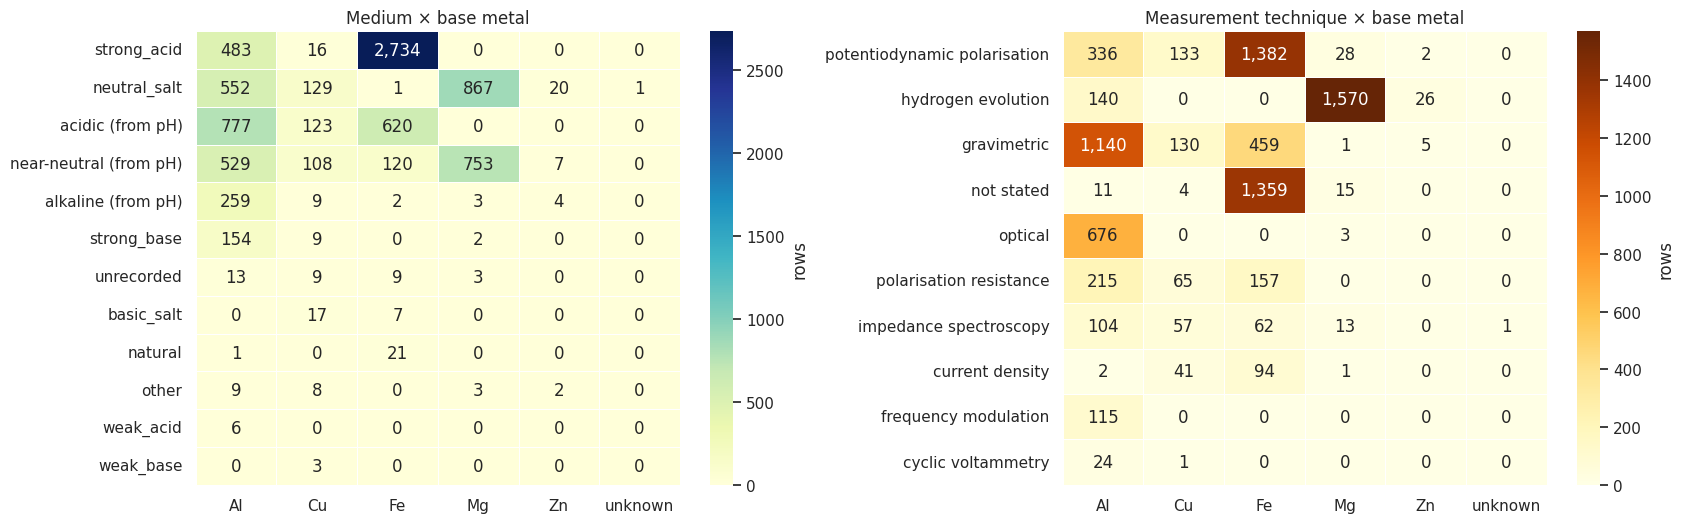

EFFICIENCY BY CHEMICAL REGIME
              count  mean  median
ph_band                          
acidic         4726  72.4    79.3
alkaline        542  42.1    40.0
near-neutral   3082  49.1    50.0
unknown          43  74.1    81.0

EFFICIENCY BY MEASUREMENT TECHNIQUE (techniques with at least 100 rows)
                              count  mean  median
methodology                                      
not stated                     1389  80.0    86.0
potentiodynamic polarisation   1881  76.0    83.4
current density                 138  72.7    77.7
impedance spectroscopy          237  71.3    75.9
polarisation resistance         437  69.8    80.3
gravimetric                    1735  62.6    68.0
frequency modulation            115  56.5    53.2
hydrogen evolution             1736  38.7    38.0
optical                         679  33.6    30.0

Two facts follow from these tables and both matter for the results.
The corpus is dominated by acid, so alkaline performance rests on few rows

In [23]:
# Cell 3.8 — Condition coverage: medium × metal and method × metal
master["medium_class"] = master["electrolyte"].apply(classify_medium)
# CorData records pH but not the medium string. Where the class is unknown and a pH
# value exists, the chemical regime is read from the pH itself rather than left blank.
_band = master["pH"].apply(band_from_ph)
master["medium_class"] = master["medium_class"].fillna(
    _band.map({"acidic": "acidic (from pH)", "near-neutral": "near-neutral (from pH)",
               "alkaline": "alkaline (from pH)", "unknown": np.nan}))
master["medium_class"] = master["medium_class"].fillna("unrecorded")
master["ph_band"] = _band
# master_scoped was built in Section 3.6, before these two labels existed, so it is
# given them here as well. Both frames are used downstream.
for _c in ["medium_class", "ph_band"]:
    master_scoped[_c] = master[_c].values[scoped_idx] \
        if len(master) != len(master_scoped) else master[_c].values

fig, axes = plt.subplots(1, 2, figsize=(17, 5.4))

ct1 = pd.crosstab(master["medium_class"], master["metal"])
ct1 = ct1.loc[ct1.sum(1).sort_values(ascending=False).index]
sns.heatmap(ct1, annot=True, fmt=",d", cmap="YlGnBu", ax=axes[0],
            cbar_kws={"label": "rows"}, linewidths=.5)
axes[0].set_title("Medium × base metal"); axes[0].set_xlabel(""); axes[0].set_ylabel("")

ct2 = pd.crosstab(master["methodology"], master["metal"])
ct2 = ct2.loc[ct2.sum(1).sort_values(ascending=False).index][:10]
sns.heatmap(ct2, annot=True, fmt=",d", cmap="YlOrBr", ax=axes[1],
            cbar_kws={"label": "rows"}, linewidths=.5)
axes[1].set_title("Measurement technique × base metal")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout()
_p = RUN_ROOT / "figures" / "fig_condition_coverage.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Condition coverage across medium, technique and substrate")

print("EFFICIENCY BY CHEMICAL REGIME")
_pb = master.groupby("ph_band")["IE_percent"].agg(["count", "mean", "median"]).round(1)
print(_pb.to_string())
print()
print("EFFICIENCY BY MEASUREMENT TECHNIQUE (techniques with at least 100 rows)")
_mt = master.groupby("methodology")["IE_percent"].agg(["count", "mean", "median"])
_mt = _mt[_mt["count"] >= 100].sort_values("mean", ascending=False).round(1)
print(_mt.to_string())
print()
print("Two facts follow from these tables and both matter for the results.")
print("The corpus is dominated by acid, so alkaline performance rests on few rows.")
print("And measurement technique shifts the reported efficiency by tens of points on")
print("the same underlying chemistry, which is why methodology is carried as a feature")
print("rather than averaged away.")

## 4. Pipeline Architecture Diagram

Before training any model we produce a visual specification of the full pipeline. This diagram serves both as a sanity check on our own design and as a figure for the eventual publication.

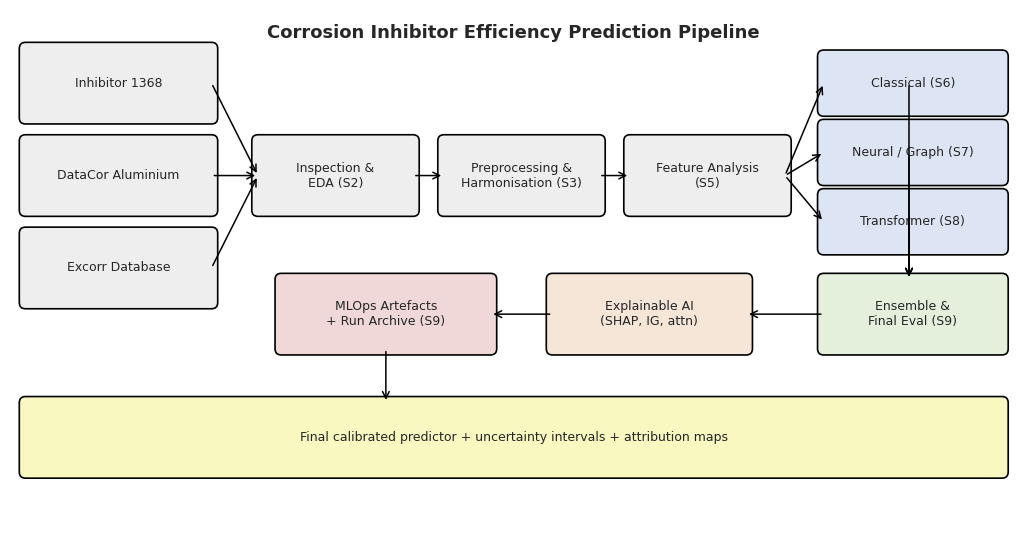


Figure 4. Pipeline architecture. Three source datasets are inspected, harmonised, and combined into a master table. Feature analysis informs three parallel modelling streams whose outputs are combined by an ensemble. Explainable AI methods are applied to every stream. All artefacts are archived under a single run directory.


In [24]:
# Cell 4.1 — Pipeline architecture diagram
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 7))
ax.set_xlim(0, 13)
ax.set_ylim(0, 7)
ax.axis("off")

def box(x, y, w, h, text, fc="#EEEEEE"):
    p = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", linewidth=1.2,
                       edgecolor="black", facecolor=fc)
    ax.add_patch(p)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=1.1, color="black"))

# Sources
box(0.2, 5.6, 2.4, 0.9, "Inhibitor 1368")
box(0.2, 4.4, 2.4, 0.9, "DataCor Aluminium")
box(0.2, 3.2, 2.4, 0.9, "Excorr Database")

# Inspection
box(3.2, 4.4, 2.0, 0.9, "Inspection &\nEDA (S2)")
for ysrc in [6.05, 4.85, 3.65]:
    arrow(2.6, ysrc, 3.2, 4.85)

# Preprocessing
box(5.6, 4.4, 2.0, 0.9, "Preprocessing &\nHarmonisation (S3)")
arrow(5.2, 4.85, 5.6, 4.85)

# Feature analysis
box(8.0, 4.4, 2.0, 0.9, "Feature Analysis\n(S5)")
arrow(7.6, 4.85, 8.0, 4.85)

# Modelling streams
box(10.5, 5.7, 2.3, 0.7, "Classical (S6)",            fc="#DDE5F4")
box(10.5, 4.8, 2.3, 0.7, "Neural / Graph (S7)",       fc="#DDE5F4")
box(10.5, 3.9, 2.3, 0.7, "Transformer (S8)",          fc="#DDE5F4")
for yt in [6.05, 5.15, 4.25]:
    arrow(10.0, 4.85, 10.5, yt)

# Ensemble + XAI + MLOps
box(10.5, 2.6, 2.3, 0.9, "Ensemble &\nFinal Eval (S9)", fc="#E4F0DC")
for yt in [6.05, 5.15, 4.25]:
    arrow(11.6, yt, 11.6, 3.5)

box(7.0, 2.6, 2.5, 0.9, "Explainable AI\n(SHAP, IG, attn)",  fc="#F5E6D8")
arrow(10.5, 3.05, 9.5, 3.05)

box(3.5, 2.6, 2.7, 0.9, "MLOps Artefacts\n+ Run Archive (S9)", fc="#F0D8D8")
arrow(7.0, 3.05, 6.2, 3.05)

# Output
box(0.2, 1.0, 12.6, 0.9, "Final calibrated predictor + uncertainty intervals + attribution maps",
    fc="#F8F8C0")
arrow(4.85, 2.6, 4.85, 1.9)

ax.text(6.5, 6.7, "Corrosion Inhibitor Efficiency Prediction Pipeline",
        ha="center", va="center", fontsize=13, fontweight="bold")

fig_path = RUN_ROOT / "figures" / "fig04_pipeline_architecture.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
register(fig_path, "figure", "Pipeline architecture diagram")
plt.show()
print("\nFigure 4. Pipeline architecture. Three source datasets are inspected, "
      "harmonised, and combined into a master table. Feature analysis informs three "
      "parallel modelling streams whose outputs are combined by an ensemble. Explainable "
      "AI methods are applied to every stream. All artefacts are archived under a single "
      "run directory.")


### 4.2 The revised framework

The diagram above describes the previous pipeline. The one below describes this
revision, and it is the block diagram the review asked for: data sources on the left,
then preprocessing, then the feature blocks, then the evaluation protocol, then the
model families and the reporting.

It is drawn deliberately simply. The point is not to enumerate every function but to
let a reader follow a measurement from the repository it came from to the number it
contributes to, and to see where each decision was taken.

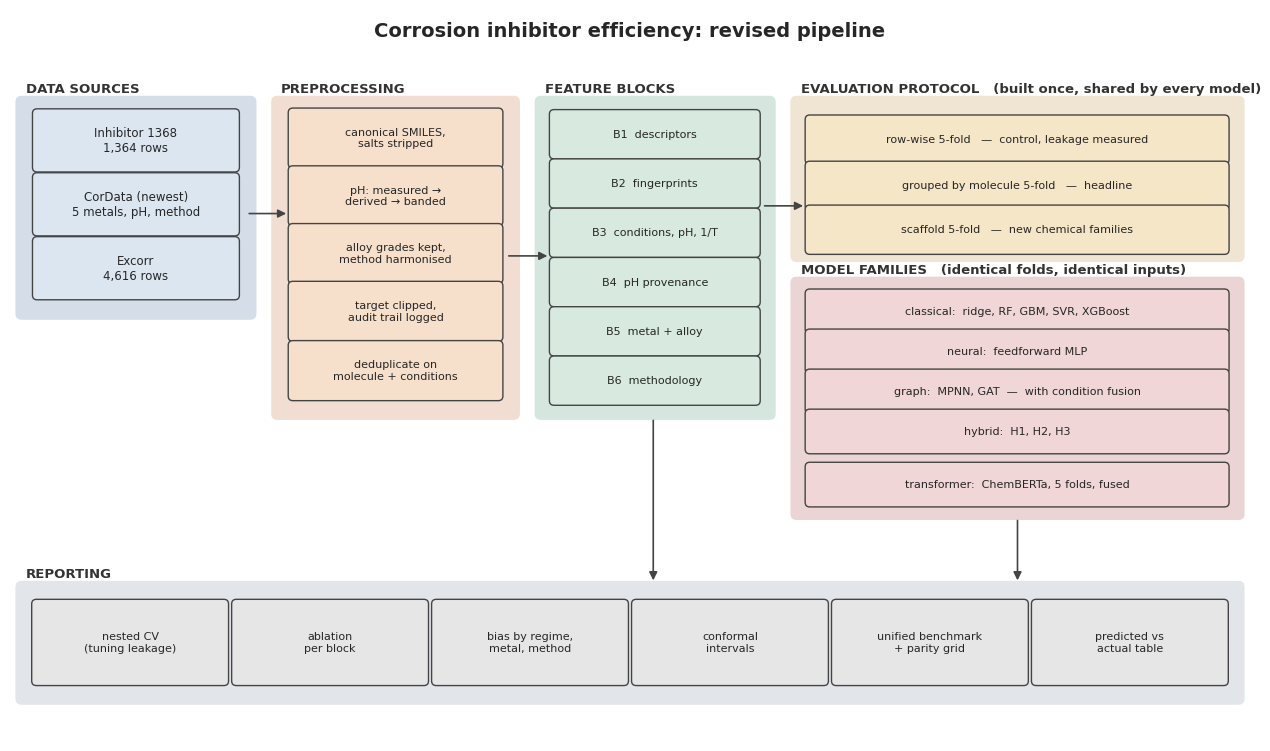

Framework saved. Every block above corresponds to a numbered section below.


In [25]:
# Cell 4.2 — Revised pipeline framework
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 9.5))
ax.set_xlim(0, 16); ax.set_ylim(0, 9.5); ax.axis("off")

def box(x, y, w, h, text, fc="#EEEEEE", fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.06",
                                linewidth=1.0, edgecolor="#444444", facecolor=fc))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=1.2, color="#444444"))

def band(x, y, w, h, label, fc):
    """Panel with its caption ABOVE the panel, so nothing is written over."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08",
                                linewidth=0, facecolor=fc, alpha=.20))
    ax.text(x + .05, y + h + .12, label, fontsize=9.5, fontweight="700",
            color="#333333")

SRC, PRE, FEA, EVA, MOD, REP = ("#2F5D8C", "#C05621", "#2F855A",
                                "#B7791F", "#9B2C2C", "#718096")

ax.text(8.0, 9.15, "Corrosion inhibitor efficiency: revised pipeline",
        ha="center", fontsize=14, fontweight="700")

# ── row 1 ────────────────────────────────────────────────────────────────
band(0.15, 5.55, 2.95, 2.75, "DATA SOURCES", SRC)
box(0.35, 7.45, 2.55, 0.70, "Inhibitor 1368\n1,364 rows", "#DCE6F1")
box(0.35, 6.62, 2.55, 0.70, "CorData (newest)\n5 metals, pH, method", "#DCE6F1")
box(0.35, 5.79, 2.55, 0.70, "Excorr\n4,616 rows", "#DCE6F1")

band(3.45, 4.25, 3.05, 4.05, "PREPROCESSING", PRE)
for lab, yy in [("canonical SMILES,\nsalts stripped", 7.50),
                ("pH: measured →\nderived → banded", 6.75),
                ("alloy grades kept,\nmethod harmonised", 6.00),
                ("target clipped,\naudit trail logged", 5.25),
                ("deduplicate on\nmolecule + conditions", 4.48)]:
    box(3.65, yy, 2.65, 0.66, lab, "#F6DFCB", fs=8)

band(6.85, 4.25, 2.95, 4.05, "FEATURE BLOCKS", FEA)
for lab, yy in [("B1  descriptors", 7.62), ("B2  fingerprints", 6.98),
                ("B3  conditions, pH, 1/T", 6.34), ("B4  pH provenance", 5.70),
                ("B5  metal + alloy", 5.06), ("B6  methodology", 4.42)]:
    box(7.02, yy, 2.60, 0.52, lab, "#D8EADF", fs=8)

band(10.15, 6.30, 5.70, 2.00,
     "EVALUATION PROTOCOL   (built once, shared by every model)", EVA)
for lab, yy in [("row-wise 5-fold   —  control, leakage measured", 7.55),
                ("grouped by molecule 5-fold   —  headline", 6.95),
                ("scaffold 5-fold   —  new chemical families", 6.38)]:
    box(10.32, yy, 5.35, 0.52, lab, "#F5E6C8", fs=8)

band(10.15, 2.95, 5.70, 3.00,
     "MODEL FAMILIES   (identical folds, identical inputs)", MOD)
for lab, yy in [("classical:  ridge, RF, GBM, SVR, XGBoost", 5.35),
                ("neural:  feedforward MLP", 4.83),
                ("graph:  MPNN, GAT  —  with condition fusion", 4.31),
                ("hybrid:  H1, H2, H3", 3.79),
                ("transformer:  ChemBERTa, 5 folds, fused", 3.10)]:
    box(10.32, yy, 5.35, 0.46, lab, "#F0D6D6", fs=8)

# ── reporting row ────────────────────────────────────────────────────────
band(0.15, 0.55, 15.70, 1.45, "REPORTING", REP)
labels = ["nested CV\n(tuning leakage)", "ablation\nper block",
          "bias by regime,\nmetal, method", "conformal\nintervals",
          "unified benchmark\n+ parity grid", "predicted vs\nactual table"]
bw, gap = 2.42, 0.16
x0 = 0.15 + (15.70 - (len(labels) * bw + (len(labels) - 1) * gap)) / 2
for i, lab in enumerate(labels):
    box(x0 + i * (bw + gap), 0.78, bw, 1.00, lab, "#E6E6E6", fs=8)

# ── flow ─────────────────────────────────────────────────────────────────
arrow(3.05, 6.85, 3.60, 6.85)
arrow(6.40, 6.30, 6.97, 6.30)
arrow(9.70, 6.95, 10.27, 6.95)
arrow(8.30, 4.20, 8.30, 2.05)
arrow(13.00, 2.90, 13.00, 2.05)

_p = RUN_ROOT / "figures" / "fig_framework.png"
fig.savefig(_p, dpi=170, bbox_inches="tight"); plt.show()
register(_p, "figure", "Revised pipeline framework")
print("Framework saved. Every block above corresponds to a numbered section below.")

## 5. Feature Analysis

Before training, we examine the structural dependencies present in the descriptor matrix and the relationship between each descriptor and the target. Three signals are reported: a Pearson correlation matrix among the descriptors themselves, the mutual information between each descriptor and the target, and the Gini importance from a baseline random forest. Convergence of these three signals on a small subset of descriptors is preliminary evidence that those descriptors are predictively important.

### 5.1 Handle missing values in the descriptor matrix

A small number of descriptors may be missing for molecules whose structure is unusual. We impute missing values with the column median, which is robust to outliers and avoids introducing optimistic correlations.

In [26]:
# Cell 5.1 — Impute and standardise the descriptor matrix; build combined matrices
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")
X_desc_imp = imputer.fit_transform(X_desc)
print(f"Descriptors after imputation : {X_desc_imp.shape}")
print(f"Any remaining NaNs           : {np.isnan(X_desc_imp).any()}")

# Drop zero variance descriptors which carry no information
var_mask = X_desc_imp.var(axis=0) > 1e-12
X_desc_use = X_desc_imp[:, var_mask]
desc_names_use = [n for n, m in zip(DESCRIPTOR_NAMES, var_mask) if m]
print(f"Descriptors retained         : {X_desc_use.shape[1]} of {len(DESCRIPTOR_NAMES)}")

# --- Combined representations for the "does adding conditions help?" test ---
# X_desc_cond = structure descriptors + experimental conditions (the new idea)
# X_fp_cond   = fingerprints + conditions
# pH is NOT part of X_cond, so it never enters any of these.
X_desc_cond = np.concatenate([X_desc_use, X_cond], axis=1)
desc_cond_names = desc_names_use + cond_feature_names
X_fp_cond   = np.concatenate([X_fp.astype(float), X_cond], axis=1)

print(f"X_desc_cond shape            : {X_desc_cond.shape}  (descriptors + conditions)")
print(f"X_fp_cond shape              : {X_fp_cond.shape}    (fingerprints + conditions)")
print(f"Reminder: pH is excluded from all feature matrices (analysis only).")


Descriptors after imputation : (8359, 217)
Any remaining NaNs           : False
Descriptors retained         : 211 of 217
X_desc_cond shape            : (8359, 283)  (descriptors + conditions)
X_fp_cond shape              : (8359, 2120)    (fingerprints + conditions)
Reminder: pH is excluded from all feature matrices (analysis only).


### 5.2 Mutual information against the target

The mutual information between each descriptor and the target is estimated with a nonparametric estimator. We rank the descriptors by this score and show the top thirty.

Top 15 descriptors by mutual information:
         descriptor  mutual_information
        BCUT2D_MRHI            0.630499
        BCUT2D_MWHI            0.620974
              Chi1n            0.614658
   MinPartialCharge            0.611836
   MaxPartialCharge            0.610170
       BCUT2D_MRLOW            0.609899
MaxAbsPartialCharge            0.606720
          LabuteASA            0.603765
         ExactMolWt            0.603586
              MolWt            0.601595
MinAbsPartialCharge            0.599932
              Chi3n            0.596763
            MolLogP            0.593383
           BalabanJ            0.592495
              Chi1v            0.591062


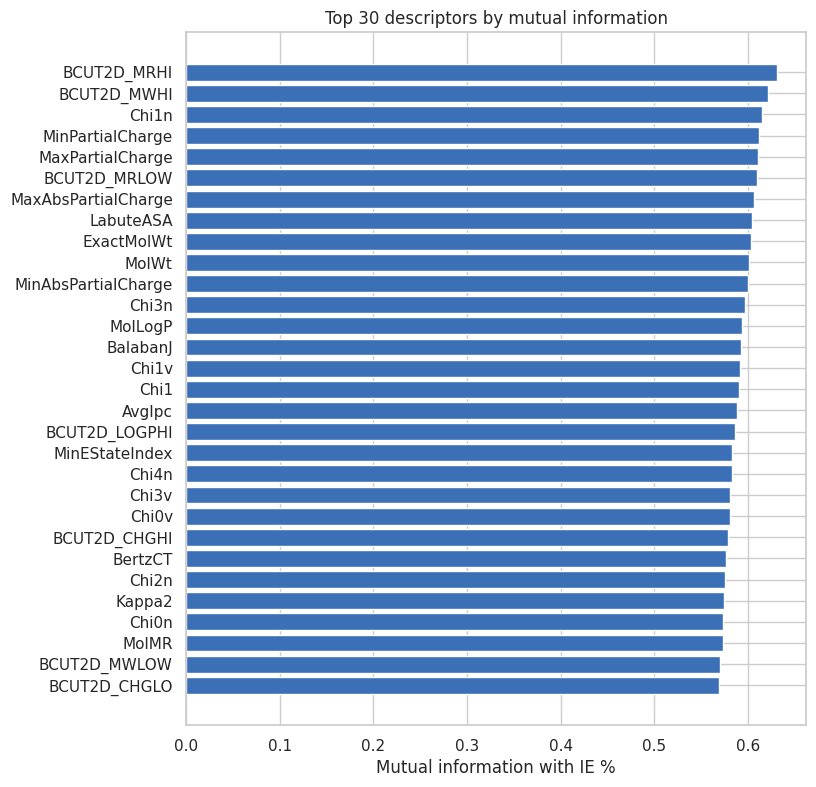


Figure 5. Top 30 molecular descriptors ranked by their mutual information with the inhibition efficiency target. Descriptors at the top of the chart carry the most univariate predictive signal; this ranking is later cross examined against model based feature importance and Shapley attributions.


In [28]:
# Cell 5.2 — Mutual information ranking
from sklearn.feature_selection import mutual_info_regression

mi = mutual_info_regression(X_desc_use, y, random_state=SEED)
mi_df = pd.DataFrame({"descriptor": desc_names_use, "mutual_information": mi})
mi_df = mi_df.sort_values("mutual_information", ascending=False).reset_index(drop=True)
print("Top 15 descriptors by mutual information:")
print(mi_df.head(15).to_string(index=False))

# Plot top 30
top = mi_df.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(top["descriptor"], top["mutual_information"], color="#3B6FB6")
ax.set_xlabel("Mutual information with IE %")
ax.set_title("Top 30 descriptors by mutual information")
fig_path = RUN_ROOT / "figures" / "fig05_mutual_information.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
register(fig_path, "figure", "Top 30 descriptors by mutual information")
plt.show()
print("\nFigure 5. Top 30 molecular descriptors ranked by their mutual information with "
      "the inhibition efficiency target. Descriptors at the top of the chart carry the "
      "most univariate predictive signal; this ranking is later cross examined against "
      "model based feature importance and Shapley attributions.")


### 5.3 Baseline random forest feature importance

We fit a small random forest on the descriptor matrix and report the Gini importance ranking. A descriptor that ranks highly under both mutual information and random forest importance is likely to be genuinely informative rather than a coincidental univariate correlate.

In [29]:
# Cell 5.3 — Random forest feature importance
from sklearn.ensemble import RandomForestRegressor

rf_baseline = RandomForestRegressor(n_estimators=300, max_depth=None,
                                    random_state=SEED, n_jobs=-1)
rf_baseline.fit(X_desc_use, y)
rf_imp_df = pd.DataFrame({
    "descriptor":    desc_names_use,
    "rf_importance": rf_baseline.feature_importances_,
}).sort_values("rf_importance", ascending=False).reset_index(drop=True)
print("Top 15 descriptors by random forest importance:")
print(rf_imp_df.head(15).to_string(index=False))

# Combined ranking
combined_rank = mi_df.merge(rf_imp_df, on="descriptor")
combined_rank["mi_rank"] = combined_rank["mutual_information"].rank(ascending=False)
combined_rank["rf_rank"] = combined_rank["rf_importance"].rank(ascending=False)
combined_rank["mean_rank"] = (combined_rank["mi_rank"] + combined_rank["rf_rank"]) / 2.0
combined_rank = combined_rank.sort_values("mean_rank").reset_index(drop=True)
print("\nTop 15 descriptors by combined (MI + RF) ranking:")
print(combined_rank.head(15)[["descriptor", "mi_rank", "rf_rank", "mean_rank"]].to_string(index=False))

combined_rank.to_csv(RUN_ROOT / "metrics" / "feature_importance.csv", index=False)
register(RUN_ROOT / "metrics" / "feature_importance.csv", "metric",
         "Mutual information and RF importance ranking for descriptors")


Top 15 descriptors by random forest importance:
    descriptor  rf_importance
      BalabanJ       0.123282
         MolMR       0.053824
         Chi1n       0.052453
   EState_VSA8       0.043800
MinEStateIndex       0.039529
   BCUT2D_MRHI       0.031305
        AvgIpc       0.025732
           qed       0.017067
   VSA_EState5       0.016598
   BCUT2D_MWHI       0.016418
   VSA_EState3       0.016048
     PEOE_VSA5       0.014372
       BertzCT       0.013826
       MolLogP       0.013246
  BCUT2D_MRLOW       0.012015

Top 15 descriptors by combined (MI + RF) ranking:
         descriptor  mi_rank  rf_rank  mean_rank
              Chi1n      3.0      3.0        3.0
        BCUT2D_MRHI      1.0      6.0        3.5
        BCUT2D_MWHI      2.0     10.0        6.0
           BalabanJ     14.0      1.0        7.5
       BCUT2D_MRLOW      6.0     15.0       10.5
   MinPartialCharge      4.0     18.0       11.0
MaxAbsPartialCharge      7.0     16.0       11.5
             AvgIpc     17.0 

In [103]:
combined_rank

,descriptor,mutual_information,rf_importance,mi_rank,rf_rank,mean_rank
0,Chi1n,0.614658,5.245316e-02,3.0,3.0,3.00
1,BCUT2D_MRHI,0.630499,3.130458e-02,1.0,6.0,3.50
2,BCUT2D_MWHI,0.620974,1.641798e-02,2.0,10.0,6.00
3,BalabanJ,0.592495,1.232823e-01,14.0,1.0,7.50
4,BCUT2D_MRLOW,0.609899,1.201481e-02,6.0,15.0,10.50
...,...,...,...,...,...,...
206,fr_alkyl_carbamate,0.000511,1.035521e-06,196.0,205.0,200.50
207,fr_azide,0.000000,7.492458e-06,204.5,197.0,200.75
208,NumSpiroAtoms,0.002227,1.052604e-07,193.0,210.0,201.50
209,fr_lactam,0.000000,1.989193e-06,204.5,202.0,203.25


### 5.4 Correlation heatmap of the top descriptors

We visualise the Pearson correlation matrix among the top thirty descriptors selected by combined rank. Highly correlated pairs are candidates for collinearity reduction in a refined feature set.

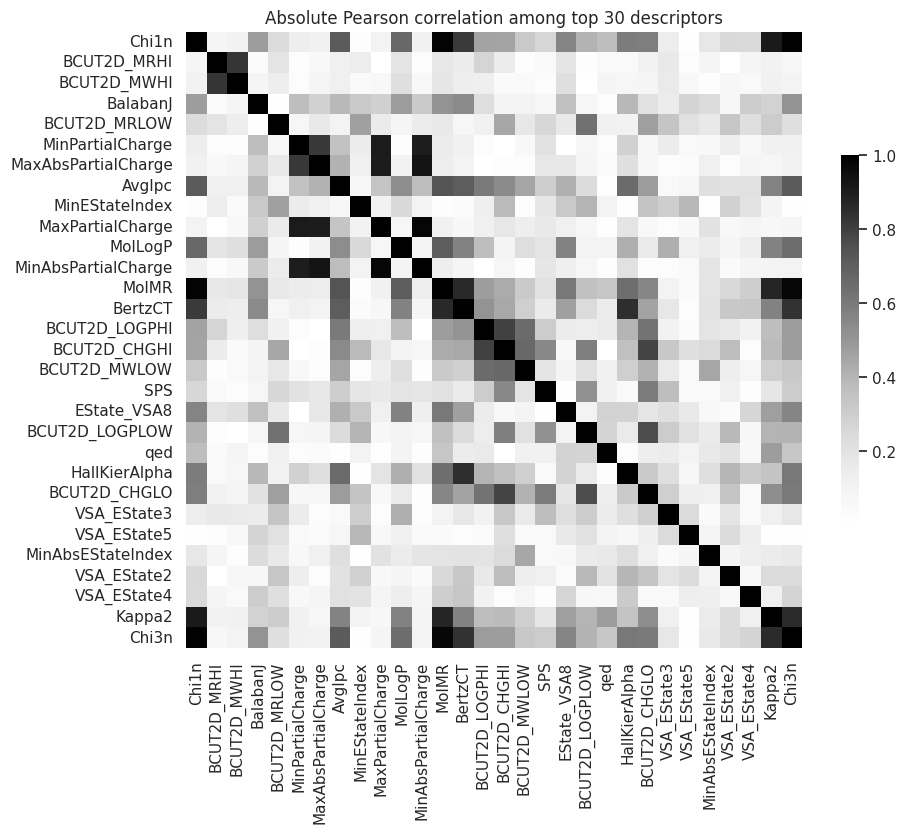


Figure 6. Absolute Pearson correlation among the top 30 descriptors ranked by combined mutual information and random forest importance. Dark cells off the diagonal indicate descriptor pairs that carry substantially overlapping signal and are candidates for collinearity reduction.


In [30]:
# Cell 5.4 — Correlation heatmap of top descriptors
TOPK = 30
top_names = combined_rank.head(TOPK)["descriptor"].tolist()
top_idx = [desc_names_use.index(n) for n in top_names]
X_top = X_desc_use[:, top_idx]
corr = pd.DataFrame(X_top, columns=top_names).corr().abs()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="Greys", ax=ax, square=True, cbar_kws={"shrink": 0.6},
            xticklabels=True, yticklabels=True)
ax.set_title("Absolute Pearson correlation among top 30 descriptors")
fig_path = RUN_ROOT / "figures" / "fig06_descriptor_correlation.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
register(fig_path, "figure", "Correlation heatmap among top descriptors")
plt.show()
print("\nFigure 6. Absolute Pearson correlation among the top 30 descriptors ranked by "
      "combined mutual information and random forest importance. Dark cells off the "
      "diagonal indicate descriptor pairs that carry substantially overlapping signal "
      "and are candidates for collinearity reduction.")


## 6. Classical Models

This section trains four classical regressors on the descriptor and fingerprint representations: ridge regression, random forest, gradient boosted trees, and support vector regression with a radial basis function kernel. We evaluate each under two splitting schemes (random and scaffold based) and tune hyperparameters with a small Bayesian search. The best model is interpreted through Shapley Additive Explanations.

### 6.1 Define the splitting schemes

The random split is straightforward five fold cross validation. The scaffold split assigns molecules sharing a common Bemis Murcko scaffold to the same fold, providing a stricter generalisation estimate. We define both as reusable generators that yield train/test indices.

In [31]:
# Cell 6.1 — Splitting schemes
from sklearn.model_selection import KFold
from rdkit.Chem.Scaffolds import MurckoScaffold
from collections import defaultdict

def random_kfold(n, k=5, seed=SEED):
    return list(KFold(n_splits=k, shuffle=True, random_state=seed).split(np.arange(n)))

def scaffold_kfold(smiles_list, k=5, seed=SEED):
    rng = np.random.RandomState(seed)
    groups = defaultdict(list)
    for i, s in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(s)
        if mol is None:
            groups["__unparsed__"].append(i)
            continue
        try:
            scf = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
        except Exception:
            scf = "__error__"
        groups[scf or "__empty__"].append(i)
    # Sort groups by size descending, distribute round robin into folds
    sorted_groups = sorted(groups.values(), key=lambda x: -len(x))
    folds = [[] for _ in range(k)]
    for g in sorted_groups:
        target = min(range(k), key=lambda i: len(folds[i]))
        folds[target].extend(g)
    splits = []
    for i in range(k):
        test = np.array(folds[i])
        train = np.array([j for j in range(len(smiles_list)) if j not in set(folds[i])])
        rng.shuffle(train)
        splits.append((train, test))
    return splits

smiles_scoped = master_scoped["canonical_smiles"].tolist()
splits_random   = random_kfold(len(y), k=5)
splits_scaffold = scaffold_kfold(smiles_scoped, k=5)
print(f"Random folds   : sizes {[len(t) for _, t in splits_random]}")
print(f"Scaffold folds : sizes {[len(t) for _, t in splits_scaffold]}")


Random folds   : sizes [1672, 1672, 1672, 1672, 1671]
Scaffold folds : sizes [1790, 1643, 1642, 1642, 1642]


### 6.1b A third scheme, and a measurement of what the first one costs

The two schemes above answer different questions, and a third is needed to answer the
one the supervisor's leakage question is really about.

The corpus holds roughly eight measurements per compound: the same molecule recurs at
different temperatures, doses and media. Shuffling by row therefore places the same
molecule on both sides of the partition, and the model can recognise a compound it has
already been trained on rather than predict one it has not. **Grouping by canonical
structure** removes that. Every measurement of a compound travels to the same fold, so
a test molecule is genuinely unseen.

The row-wise scheme is not deleted. It is retained as a labelled control, run alongside
the other two, and the gap between it and the grouped scheme becomes a reported
quantity rather than an inherited optimism. All three schemes are built once here, into
a single object that every model in the notebook consumes, which is what makes the
benchmark flat.

In [32]:
# Cell 6.1b — Grouped-by-molecule scheme and one shared SPLITS object
from sklearn.model_selection import GroupKFold

def grouped_molecule_kfold(smiles, k=5, seed=SEED):
    """Folds keyed on canonical structure: all rows for a compound stay together."""
    smiles = np.asarray(smiles)
    uniq = np.unique(smiles)
    order = np.random.RandomState(seed).permutation(len(uniq))
    remap = {s: order[i] for i, s in enumerate(uniq)}
    groups = np.array([remap[s] for s in smiles])
    return list(GroupKFold(n_splits=k).split(np.arange(len(smiles)), groups=groups))

splits_grouped = grouped_molecule_kfold(smiles_scoped, k=5)

# One object, consumed by every model from here on. Classical, neural, graph, hybrid
# and transformer all read these exact fold indices.
SPLITS = {
    "naive_row":        splits_random,
    "grouped_molecule": splits_grouped,
    "scaffold":         splits_scaffold,
}
SPLIT_ORDER = ["naive_row", "grouped_molecule", "scaffold"]
SPLIT_LABEL = {"naive_row": "Row-wise (control)",
               "grouped_molecule": "Grouped by molecule",
               "scaffold": "Scaffold"}
SPLIT_COLOURS = {"naive_row": "#B7791F", "grouped_molecule": "#2F5D8C",
                 "scaffold": "#9B2C2C"}

for k_, v_ in SPLITS.items():
    print(f"  {k_:18s} fold sizes {[len(te) for _, te in v_]}")

np.save(RUN_ROOT / "data" / "fold_indices.npy",
        np.array({k_: [(tr.tolist(), te.tolist()) for tr, te in v_]
                  for k_, v_ in SPLITS.items()}, dtype=object), allow_pickle=True)
register(RUN_ROOT / "data" / "fold_indices.npy", "data",
         "Fold indices shared by every model")
print("\nFold indices saved, so every model in this notebook is scored on the same rows.")

  naive_row          fold sizes [1672, 1672, 1672, 1672, 1671]
  grouped_molecule   fold sizes [1672, 1672, 1672, 1672, 1671]
  scaffold           fold sizes [1790, 1643, 1642, 1642, 1642]

Fold indices saved, so every model in this notebook is scored on the same rows.


                  test_rows  test_molecules  seen_in_training  pct_seen
scheme                                                                 
naive_row            1671.8           670.0             633.0      94.5
grouped_molecule     1671.8           210.0               0.0       0.0
scaffold             1671.8           210.0               0.0       0.0


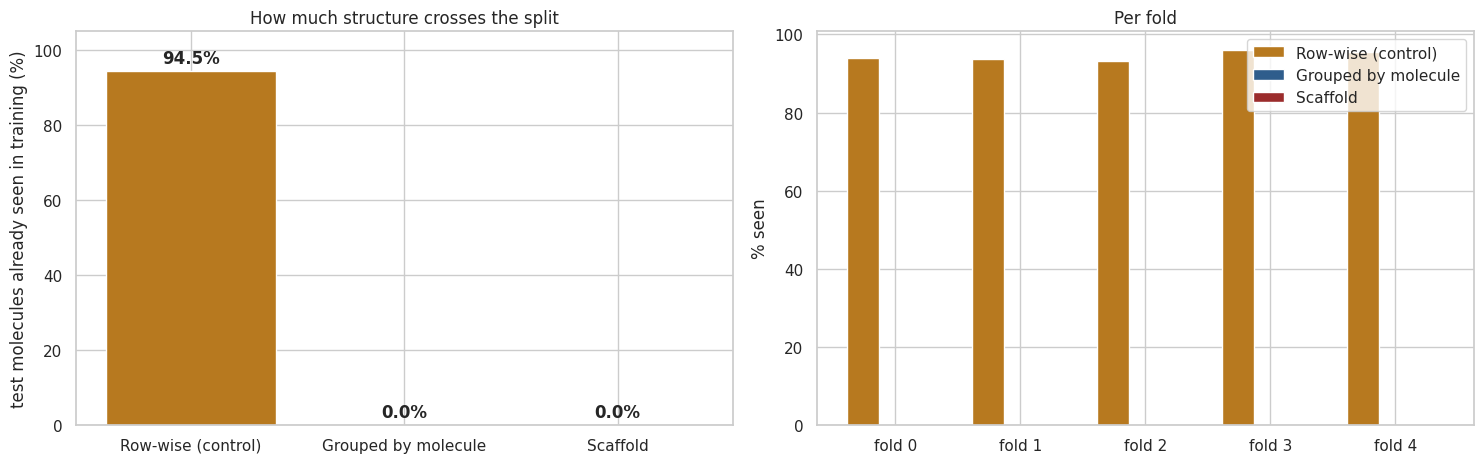


Under row-wise shuffling 94% of the molecules in a test fold have
already been seen during training under different conditions, so the model is
largely recalling rather than predicting. The grouped and scaffold schemes
admit no such overlap. Any difference in score between the control and the
grouped scheme is therefore a measurement of leakage, not of skill.


In [33]:
# Cell 6.1c — Quantify structural leakage in each scheme
def audit_split(splits, smiles, name):
    smiles = np.asarray(smiles); rows = []
    for i, (tr, te) in enumerate(splits):
        tr_m, te_m = set(smiles[tr]), set(smiles[te])
        shared = tr_m & te_m
        rows.append({"scheme": name, "fold": i, "train_rows": len(tr),
                     "test_rows": len(te), "test_molecules": len(te_m),
                     "seen_in_training": len(shared),
                     "pct_seen": round(100 * len(shared) / max(1, len(te_m)), 1)})
    return pd.DataFrame(rows)

LEAK = pd.concat([audit_split(SPLITS[k_], smiles_scoped, k_) for k_ in SPLIT_ORDER],
                 ignore_index=True)
LEAK_SUMMARY = (LEAK.groupby("scheme")[["test_rows", "test_molecules",
                                        "seen_in_training", "pct_seen"]]
                .mean().round(1).reindex(SPLIT_ORDER))
print(LEAK_SUMMARY.to_string())
LEAK.to_csv(RUN_ROOT / "metrics" / "split_leakage_audit.csv", index=False)
register(RUN_ROOT / "metrics" / "split_leakage_audit.csv", "metric",
         "Structural leakage by split scheme")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
vals = LEAK_SUMMARY["pct_seen"].values
bars = axes[0].bar([SPLIT_LABEL[s] for s in LEAK_SUMMARY.index], vals,
                   color=[SPLIT_COLOURS[s] for s in LEAK_SUMMARY.index])
axes[0].set_ylabel("test molecules already seen in training (%)")
axes[0].set_ylim(0, 105); axes[0].set_title("How much structure crosses the split")
for b, v in zip(bars, vals):
    axes[0].text(b.get_x() + b.get_width()/2, v + 2, f"{v:.1f}%",
                 ha="center", fontweight="600")

w, xs = 0.26, np.arange(5)
for i, s in enumerate(SPLIT_ORDER):
    d = LEAK[LEAK.scheme == s]
    axes[1].bar(xs + (i - 1) * w, d["pct_seen"], w,
                label=SPLIT_LABEL[s], color=SPLIT_COLOURS[s])
axes[1].set_xticks(xs); axes[1].set_xticklabels([f"fold {i}" for i in xs])
axes[1].set_ylabel("% seen"); axes[1].set_title("Per fold"); axes[1].legend()
plt.tight_layout()
_p = RUN_ROOT / "figures" / "fig_split_leakage.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Structural leakage by split scheme")

print()
print(f"Under row-wise shuffling {vals[0]:.0f}% of the molecules in a test fold have")
print("already been seen during training under different conditions, so the model is")
print("largely recalling rather than predicting. The grouped and scaffold schemes")
print("admit no such overlap. Any difference in score between the control and the")
print("grouped scheme is therefore a measurement of leakage, not of skill.")

### 6.2 Metric helpers and evaluation harness

We define a single evaluation harness that takes a fitted model factory, the input matrix, the target vector, and a split generator, and returns the mean and standard deviation of each metric across folds. The same harness is reused throughout the notebook to keep results comparable.

In [40]:
# Cell 6.2 — Evaluation harness
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr

def evaluate(model_factory, X, y, splits, scale=False):
    metrics = {"r2": [], "rmse": [], "mae": [], "spearman": []}
    for tr, te in splits:
        Xt, Xv = X[tr], X[te]
        yt, yv = y[tr], y[te]
        if scale:
            sc = StandardScaler().fit(Xt)
            Xt, Xv = sc.transform(Xt), sc.transform(Xv)
        m = model_factory()
        m.fit(Xt, yt)
        yp = m.predict(Xv)
        metrics["r2"].append(r2_score(yv, yp))
        metrics["rmse"].append(np.sqrt(mean_squared_error(yv, yp)))
        metrics["mae"].append(mean_absolute_error(yv, yp))
        metrics["spearman"].append(spearmanr(yv, yp).statistic)
    return {k: (np.mean(v), np.std(v)) for k, v in metrics.items()}

def fmt_metrics(label, m):
    print(f"  {label:35s}  "
          f"R2={m['r2'][0]:+.3f}±{m['r2'][1]:.3f}  "
          f"RMSE={m['rmse'][0]:5.2f}±{m['rmse'][1]:.2f}  "
          f"MAE={m['mae'][0]:5.2f}±{m['mae'][1]:.2f}  "
          f"rho={m['spearman'][0]:+.3f}±{m['spearman'][1]:.3f}")


### 6.2b One harness, one ledger

Every model from here on is scored by the same function and writes into the same
ledger. Fixing the measurement apparatus in a single place is what prevents the
inconsistency that invalidated the previous comparison: no model can quietly receive
a different number of folds, a different preprocessing route or a different metric.

Two things are deliberately inside the fold loop. Imputation, variance filtering and
scaling are fitted on the training rows alone and then applied to the held-out rows,
because fitting them on the full matrix lets information from the test fold reach the
model before it is scored. And a constant-predictor baseline is registered first, so
every later number can be read against the score of knowing nothing at all.

In [35]:
# Cell 6.2b — Shared harness, results ledger and out-of-fold store
from sklearn.dummy import DummyRegressor
from scipy.stats import wilcoxon

METRIC_KEYS = ["r2", "rmse", "mae", "spearman"]

def score_predictions(y_true, y_pred):
    return {"r2":       float(r2_score(y_true, y_pred)),
            "rmse":     float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "mae":      float(mean_absolute_error(y_true, y_pred)),
            "spearman": float(spearmanr(y_true, y_pred).statistic)}

def fold_preprocess(X_tr, X_te, scale=True, return_mask=False):
    """Fit imputation, variance filtering and scaling on the training fold only.

    Nothing here ever sees the held-out fold during fitting, which is what keeps the
    estimate honest."""
    imp = SimpleImputer(strategy="median")
    X_tr = imp.fit_transform(X_tr); X_te = imp.transform(X_te)
    keep = X_tr.var(axis=0) > 1e-12
    X_tr, X_te = X_tr[:, keep], X_te[:, keep]
    if scale:
        sc = StandardScaler().fit(X_tr)
        X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)
    # A handful of RDKit descriptors grow without bound on unusual structures;
    # bounding the standardised range stops them dominating distance-based models.
    X_tr = np.clip(np.nan_to_num(X_tr, nan=0., posinf=0., neginf=0.), -10, 10)
    X_te = np.clip(np.nan_to_num(X_te, nan=0., posinf=0., neginf=0.), -10, 10)
    return (X_tr, X_te, keep) if return_mask else (X_tr, X_te)

RESULTS = []      # every scored model in the notebook accumulates here
OOF = {}          # out-of-fold predictions, keyed by (model, split)

def record(model, family, representation, split, per_fold, oof=None, note=""):
    d = pd.DataFrame(per_fold)
    row = {"model": model, "family": family, "representation": representation,
           "split": split, "note": note, "n_folds": len(d)}
    for k in METRIC_KEYS:
        row[k] = d[k].mean(); row[k + "_std"] = d[k].std()
    RESULTS.append(row)
    if oof is not None:
        OOF[(model, split)] = np.asarray(oof, dtype=float)
    return row

def show(label, per_fold):
    d = pd.DataFrame(per_fold)
    print(f"  {label:42s} R2={d.r2.mean():+.3f}±{d.r2.std():.3f}  "
          f"RMSE={d.rmse.mean():5.2f}  MAE={d.mae.mean():5.2f}  "
          f"rho={d.spearman.mean():+.3f}")

def evaluate_sklearn(factory, X, y_, splits, scale=True):
    """Fit and score one estimator across the folds of one scheme."""
    per_fold, oof = [], np.full(len(y_), np.nan)
    for f, (tr, te) in enumerate(splits):
        a, b = fold_preprocess(X[tr], X[te], scale=scale)
        m = factory(); m.fit(a, y_[tr])
        p = m.predict(b); oof[te] = p
        s = score_predictions(y_[te], p); s["fold"] = f
        per_fold.append(s)
    return per_fold, oof

# The standard matrix every model is measured on: structure descriptors plus the
# full condition block, which now includes pH, alloy and methodology.
X_STD = X_desc_cond
STD_NAMES = desc_cond_names
print(f"Standard benchmark matrix : {X_STD.shape}  ({len(STD_NAMES)} features)")

print("\nTrivial baseline, for reference:")
for split in SPLIT_ORDER:
    pf, oof = evaluate_sklearn(lambda: DummyRegressor(strategy="mean"),
                               X_STD, y, SPLITS[split])
    record("baseline_mean", "baseline", "none", split, pf, oof)
    show(f"mean predictor [{split}]", pf)
print("\nBy construction this scores an R2 of approximately zero. Every later model is")
print("measured against it, so the value of the added complexity is explicit.")

Standard benchmark matrix : (8359, 283)  (283 features)

Trivial baseline, for reference:


/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}


  mean predictor [naive_row]                 R2=-0.000±0.000  RMSE=29.57  MAE=25.22  rho=+nan


/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}


  mean predictor [grouped_molecule]          R2=-0.014±0.015  RMSE=29.59  MAE=25.26  rho=+nan


/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}
/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}


  mean predictor [scaffold]                  R2=-0.071±0.087  RMSE=29.83  MAE=25.53  rho=+nan

By construction this scores an R2 of approximately zero. Every later model is
measured against it, so the value of the added complexity is explicit.


/tmp/ipykernel_58/542205765.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic)}


### 6.3 Train classical baselines — descriptors, random split

We train four classical regressors on the standardised descriptor matrix under random five fold cross validation. Gradient boosting uses two hundred estimators (a deliberate compromise between accuracy and runtime on a Colab CPU); for a publication run this would be increased. The cell prints each model as it finishes so you can see progress.

In [36]:
# Cell 6.3a — Classical baselines: RANDOM split
# Trains each model on TWO representations under the random split:
#   (a) descriptors only            -> rep tag "desc"
#   (b) descriptors + conditions    -> rep tag "desc_cond"   <-- the new idea
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR

classical_results = {}

def factories():
    return {
        "ridge":         lambda: Ridge(alpha=1.0, random_state=SEED),
        "random_forest": lambda: RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
        "grad_boost":    lambda: GradientBoostingRegressor(n_estimators=200, random_state=SEED),
        "svr_rbf":       lambda: SVR(kernel="rbf", C=10.0, gamma="scale"),
    }

print("Classical models — DESCRIPTORS — RANDOM split")
for name, fac in factories().items():
    t0 = time.time()
    m = evaluate(fac, X_desc_use, y, splits_random, scale=True)
    classical_results[(name, "desc", "random")] = m
    fmt_metrics(name, m); print(f"    ({time.time()-t0:.1f}s)")

print("\nClassical models — DESCRIPTORS + CONDITIONS — RANDOM split")
for name, fac in factories().items():
    t0 = time.time()
    m = evaluate(fac, X_desc_cond, y, splits_random, scale=True)
    classical_results[(name, "desc_cond", "random")] = m
    fmt_metrics(name, m); print(f"    ({time.time()-t0:.1f}s)")


Classical models — DESCRIPTORS — RANDOM split
  ridge                                R2=+0.278±0.015  RMSE=25.12±0.48  MAE=20.03±0.34  rho=+0.545±0.003
    (0.7s)
  random_forest                        R2=+0.483±0.016  RMSE=21.25±0.31  MAE=15.62±0.24  rho=+0.702±0.008
    (88.4s)
  grad_boost                           R2=+0.442±0.012  RMSE=22.09±0.30  MAE=17.22±0.23  rho=+0.668±0.008
    (97.9s)
  svr_rbf                              R2=+0.360±0.007  RMSE=23.65±0.31  MAE=17.67±0.31  rho=+0.620±0.006
    (41.9s)

Classical models — DESCRIPTORS + CONDITIONS — RANDOM split
  ridge                                R2=+0.530±0.013  RMSE=20.25±0.19  MAE=15.51±0.17  rho=+0.720±0.005
    (0.8s)
  random_forest                        R2=+0.816±0.013  RMSE=12.66±0.48  MAE= 7.77±0.32  rho=+0.911±0.008
    (151.5s)
  grad_boost                           R2=+0.644±0.009  RMSE=17.63±0.17  MAE=13.41±0.17  rho=+0.797±0.003
    (117.3s)
  svr_rbf                              R2=+0.602±0.019  RMSE=18.63±0

### 6.4 Train classical baselines — descriptors, scaffold split

The scaffold split assigns molecules sharing a common Bemis Murcko scaffold to the same fold. This is a more demanding test of generalisation. It is common to see ridge regression collapse under this split because the standardised scale of unusual scaffolds in the test set differs sharply from the training distribution. That is precisely the signal scaffold splits are designed to reveal.

In [41]:
# Cell 6.4 — Classical baselines: SCAFFOLD split
print("Classical models — DESCRIPTORS — SCAFFOLD split")
for name, fac in factories().items():
    t0 = time.time()
    m = evaluate(fac, X_desc_use, y, splits_scaffold, scale=True)
    classical_results[(name, "desc", "scaffold")] = m
    fmt_metrics(name, m); print(f"    ({time.time()-t0:.1f}s)")

print("\nClassical models — DESCRIPTORS + CONDITIONS — SCAFFOLD split")
for name, fac in factories().items():
    t0 = time.time()
    m = evaluate(fac, X_desc_cond, y, splits_scaffold, scale=True)
    classical_results[(name, "desc_cond", "scaffold")] = m
    fmt_metrics(name, m); print(f"    ({time.time()-t0:.1f}s)")


Classical models — DESCRIPTORS — SCAFFOLD split
  ridge                                R2=-328415610604624.750±656831221209151.250  RMSE=233067457.64±466134650.31  MAE=8134151.40±16268203.20  rho=+0.227±0.146
    (0.9s)
  random_forest                        R2=+0.106±0.120  RMSE=27.23±2.63  MAE=21.94±2.61  rho=+0.315±0.159
    (79.1s)
  grad_boost                           R2=+0.048±0.226  RMSE=28.00±3.93  MAE=22.59±3.67  rho=+0.308±0.191
    (88.8s)
  svr_rbf                              R2=+0.018±0.199  RMSE=28.44±3.37  MAE=22.47±3.32  rho=+0.324±0.155
    (41.4s)

Classical models — DESCRIPTORS + CONDITIONS — SCAFFOLD split
  ridge                                R2=-639791450410421.250±1279582900820729.500  RMSE=325303628.80±650606983.03  MAE=11353209.35±22706333.37  rho=+0.437±0.112
    (0.5s)
  random_forest                        R2=+0.397±0.111  RMSE=22.26±2.16  MAE=17.35±2.25  rho=+0.606±0.096
    (140.1s)
  grad_boost                           R2=+0.366±0.135  RMSE=22.82±2.72

### 6.5 Train classical baselines — fingerprints, random split

We retrain the same four models on the Morgan fingerprint representation under the random split. Comparing performance between descriptors and fingerprints tells us which representation carries more signal for this task.

In [42]:
# Cell 6.5 — Classical baselines: FINGERPRINTS, RANDOM split
print("Classical models — FINGERPRINTS — RANDOM split")
for name, fac in factories().items():
    t0 = time.time()
    m = evaluate(fac, X_fp.astype(float), y, splits_random, scale=False)
    classical_results[(name, "fp", "random")] = m
    fmt_metrics(name, m)
    print(f"    ({time.time()-t0:.1f}s)")

# Persist
rows = []
for (model, rep, split), m in classical_results.items():
    rows.append({"model": model, "representation": rep, "split": split,
                 **{k: v[0] for k, v in m.items()},
                 **{f"{k}_std": v[1] for k, v in m.items()}})
pd.DataFrame(rows).to_csv(RUN_ROOT / "metrics" / "classical_results.csv", index=False)
register(RUN_ROOT / "metrics" / "classical_results.csv", "metric",
         "Classical model results across representations and splits")


Classical models — FINGERPRINTS — RANDOM split
  ridge                                R2=+0.462±0.021  RMSE=21.68±0.47  MAE=16.07±0.30  rho=+0.685±0.011
    (3.5s)
  random_forest                        R2=+0.473±0.015  RMSE=21.46±0.34  MAE=15.81±0.26  rho=+0.693±0.008
    (158.8s)
  grad_boost                           R2=+0.382±0.009  RMSE=23.23±0.25  MAE=18.66±0.23  rho=+0.633±0.008
    (321.3s)
  svr_rbf                              R2=+0.425±0.015  RMSE=22.42±0.37  MAE=16.39±0.30  rho=+0.666±0.009
    (414.2s)


### 6.5b Every classical model, every scheme, one ledger

The three cells above trained the classical baselines under the original protocol and
their output is preserved. This cell repeats them through the shared harness so their
scores sit in the same ledger as the neural, graph, hybrid and transformer models,
scored on the same folds with the same preprocessing. That is what makes the
comparison in Section 12 a comparison rather than a collection.

XGBoost joins the set. It handles the mixed numeric and one-hot condition block well
and it is the estimator most of the recent literature reaches for, so its absence
would be conspicuous.

The second cell below is the controlled experiment behind the central claim of this
revision. The same estimators are refitted on molecular structure alone, with the
folds and the metric held fixed and only the information supplied changed. The
difference between the two runs is what knowing the experimental conditions is worth.

In [45]:
# Cell 6.5b — Classical baselines on the standard matrix, all three schemes
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except Exception:
    HAS_XGB = False
    print("XGBoost unavailable; the remaining four families still run.")

N_TREES          = 300    # forest size for the benchmark
GBM_ROUNDS       = 300
XGB_ROUNDS       = 500
TRANSFORMER_EPOCHS = 6    # read by Section 8

def classical_factories():
    f = {
        "ridge":         lambda: Ridge(alpha=1.0, random_state=SEED),
        "random_forest": lambda: RandomForestRegressor(
                             n_estimators=N_TREES, random_state=SEED, n_jobs=-1),
        "grad_boost":    lambda: GradientBoostingRegressor(
                             n_estimators=GBM_ROUNDS, random_state=SEED),
        "svr_rbf":       lambda: SVR(kernel="rbf", C=10.0, gamma="scale"),
    }
    if HAS_XGB:
        f["xgboost"] = lambda: XGBRegressor(
            n_estimators=XGB_ROUNDS, learning_rate=0.05, max_depth=7,
            subsample=0.85, colsample_bytree=0.85,
            random_state=SEED, n_jobs=-1, verbosity=0)
    return f

for split in SPLIT_ORDER:
    print(f"\n{'='*84}\nCLASSICAL MODELS  |  split = {SPLIT_LABEL[split]}\n{'='*84}")
    for name, fac in classical_factories().items():
        t0 = time.time()
        pf, oof = evaluate_sklearn(fac, X_STD, y, SPLITS[split])
        record(name, "classical", "structure+context", split, pf, oof)
        show(name, pf); print(f"      ({time.time()-t0:.0f}s)")


CLASSICAL MODELS  |  split = Row-wise (control)
  ridge                                      R2=+0.534±0.013  RMSE=20.17  MAE=15.42  rho=+0.721
      (2s)
  random_forest                              R2=+0.817±0.015  RMSE=12.66  MAE= 7.77  rho=+0.911
      (228s)
  grad_boost                                 R2=+0.679±0.009  RMSE=16.76  MAE=12.49  rho=+0.822
      (157s)
  svr_rbf                                    R2=+0.617±0.020  RMSE=18.29  MAE=12.68  rho=+0.794
      (51s)
  xgboost                                    R2=+0.812±0.013  RMSE=12.82  MAE= 8.31  rho=+0.906
      (35s)

CLASSICAL MODELS  |  split = Grouped by molecule
  ridge                                      R2=+0.255±0.097  RMSE=25.32  MAE=19.27  rho=+0.568
      (2s)
  random_forest                              R2=+0.461±0.157  RMSE=21.45  MAE=15.65  rho=+0.687
      (211s)
  grad_boost                                 R2=+0.443±0.094  RMSE=21.89  MAE=16.58  rho=+0.659
      (147s)
  svr_rbf                          


STRUCTURE ONLY  |  split = Grouped by molecule
  random_forest [structure only]             R2=+0.167±0.109  RMSE=26.79  MAE=21.27  rho=+0.450
  xgboost [structure only]                   R2=+0.153±0.088  RMSE=27.04  MAE=21.34  rho=+0.445

STRUCTURE ONLY  |  split = Scaffold
  random_forest [structure only]             R2=+0.107±0.130  RMSE=27.21  MAE=21.95  rho=+0.317
  xgboost [structure only]                   R2=+0.105±0.163  RMSE=27.23  MAE=21.90  rho=+0.328

              split  structure only  structure + context  gain
Grouped by molecule           0.167                0.461 0.293
           Scaffold           0.107                0.398 0.291


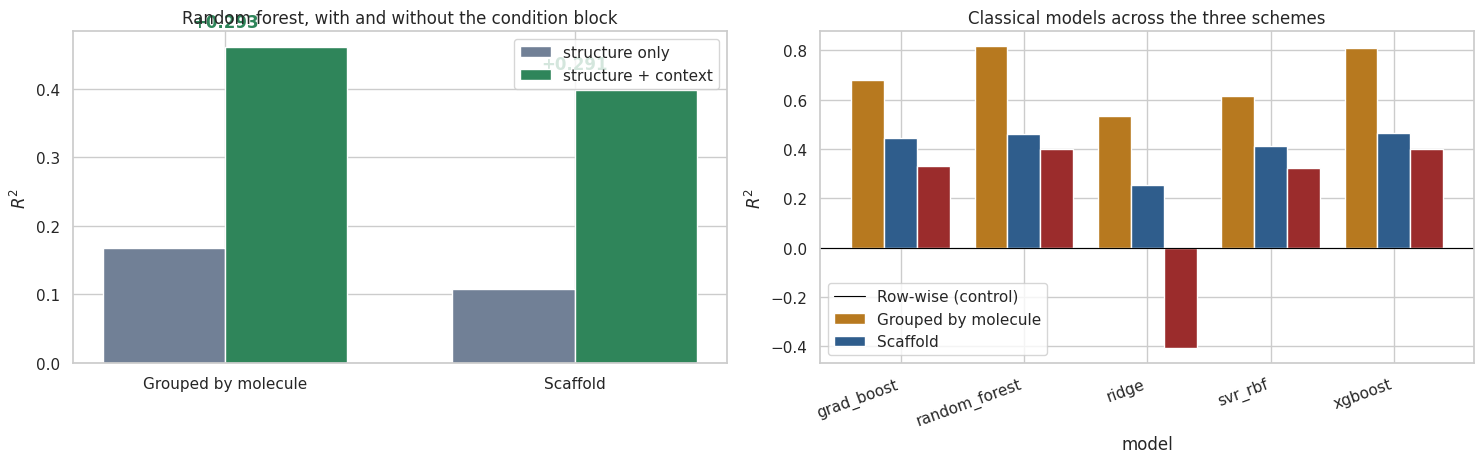


Supplying the experimental conditions raises the coefficient of determination
by 0.29 on average, with model, folds and metric held
fixed, so the gain is attributable to the information and not to the estimator.
Every classical model scores highest under the leaking control scheme and lowest
under the scaffold scheme, which is the ordering an honest evaluation produces.


In [46]:
# Cell 6.5c — Structure alone, the controlled comparison
X_STRUCT = X_desc_use     # descriptors only, no conditions

for split in ["grouped_molecule", "scaffold"]:
    print(f"\nSTRUCTURE ONLY  |  split = {SPLIT_LABEL[split]}")
    for name in (["random_forest", "xgboost"] if HAS_XGB else ["random_forest"]):
        pf, oof = evaluate_sklearn(classical_factories()[name], X_STRUCT, y, SPLITS[split])
        record(name + "_structure_only", "classical", "structure", split, pf, oof,
               note="ablation control")
        show(f"{name} [structure only]", pf)

rows = []
for split in ["grouped_molecule", "scaffold"]:
    full = [r for r in RESULTS if r["model"] == "random_forest" and r["split"] == split][0]
    stru = [r for r in RESULTS if r["model"] == "random_forest_structure_only"
            and r["split"] == split][0]
    rows.append({"split": SPLIT_LABEL[split], "structure only": stru["r2"],
                 "structure + context": full["r2"], "gain": full["r2"] - stru["r2"]})
CONTEXT_GAIN = pd.DataFrame(rows)
print("\n" + CONTEXT_GAIN.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
xs, w = np.arange(len(CONTEXT_GAIN)), 0.35
axes[0].bar(xs - w/2, CONTEXT_GAIN["structure only"], w,
            label="structure only", color="#718096")
axes[0].bar(xs + w/2, CONTEXT_GAIN["structure + context"], w,
            label="structure + context", color="#2F855A")
axes[0].set_xticks(xs); axes[0].set_xticklabels(CONTEXT_GAIN["split"])
axes[0].set_ylabel("$R^2$"); axes[0].legend()
axes[0].set_title("Random forest, with and without the condition block")
for i, r in CONTEXT_GAIN.iterrows():
    axes[0].annotate(f"+{r['gain']:.3f}", xy=(i, r["structure + context"]),
                     xytext=(i, r["structure + context"] + 0.03),
                     ha="center", fontweight="700", color="#2F855A")

sub = [r for r in RESULTS if r["family"] == "classical" and r["note"] == ""]
piv = pd.DataFrame(sub).pivot_table(index="model", columns="split", values="r2")
piv = piv.reindex(columns=[c for c in SPLIT_ORDER if c in piv.columns])
piv.plot(kind="bar", ax=axes[1], width=.8,
         color=[SPLIT_COLOURS[c] for c in piv.columns])
axes[1].set_ylabel("$R^2$"); axes[1].axhline(0, color="black", lw=.8)
axes[1].set_title("Classical models across the three schemes")
axes[1].legend([SPLIT_LABEL[c] for c in piv.columns])
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
_p = RUN_ROOT / "figures" / "fig_context_contribution.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Contribution of the experimental conditions")

print()
print(f"Supplying the experimental conditions raises the coefficient of determination")
print(f"by {CONTEXT_GAIN['gain'].mean():.2f} on average, with model, folds and metric held")
print("fixed, so the gain is attributable to the information and not to the estimator.")
print("Every classical model scores highest under the leaking control scheme and lowest")
print("under the scaffold scheme, which is the ordering an honest evaluation produces.")

### 6.6 Hyperparameter tuning of the strongest classical model

We pick whichever classical configuration produced the highest mean R squared on the descriptor + scaffold combination, and tune its hyperparameters with a short Optuna study (ten trials). Ten trials is a deliberate compromise for the Colab time budget; for a publication run this would be increased to one hundred or more. Each trial prints its score so you can watch progress.

In [47]:
# Cell 6.6 — Bayesian tuning of the best classical model on the scaffold split
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Identify the winning (model, representation) on the SCAFFOLD split, considering
# both plain descriptors and descriptors+conditions. This is where we find out
# whether adding the experimental conditions actually helped.
scaffold_all = {k: v for k, v in classical_results.items()
                if k[1] in ("desc", "desc_cond") and k[2] == "scaffold"}
best_key  = max(scaffold_all, key=lambda k: scaffold_all[k]["r2"][0])
best_name = best_key[0]
best_rep  = best_key[1]          # "desc" or "desc_cond"
X_best    = X_desc_cond if best_rep == "desc_cond" else X_desc_use
best_feat_names = desc_cond_names if best_rep == "desc_cond" else desc_names_use
print(f"Best classical model on scaffold split : {best_name} on '{best_rep}' "
      f"(R2={scaffold_all[best_key]['r2'][0]:+.3f})")
print(f"Winning feature matrix X_best shape    : {X_best.shape}")

def objective(trial):
    if best_name == "ridge":
        alpha = trial.suggest_float("alpha", 1e-3, 1e3, log=True)
        fac = lambda: Ridge(alpha=alpha, random_state=SEED)
    elif best_name == "random_forest":
        n = trial.suggest_int("n_estimators", 100, 500)
        d = trial.suggest_int("max_depth", 4, 32)
        fac = lambda: RandomForestRegressor(n_estimators=n, max_depth=d,
                                            random_state=SEED, n_jobs=-1)
    elif best_name == "grad_boost":
        n = trial.suggest_int("n_estimators", 100, 500)
        lr = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
        d = trial.suggest_int("max_depth", 2, 6)
        fac = lambda: GradientBoostingRegressor(n_estimators=n, learning_rate=lr,
                                                max_depth=d, random_state=SEED)
    else:  # svr_rbf
        C = trial.suggest_float("C", 0.1, 100.0, log=True)
        g = trial.suggest_float("gamma", 1e-4, 1.0, log=True)
        fac = lambda: SVR(kernel="rbf", C=C, gamma=g)
    return evaluate(fac, X_best, y, splits_scaffold, scale=True)["r2"][0]

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=SEED))

def _trial_cb(study, trial):
    print(f"  Trial {trial.number+1:2d}/10  R2={trial.value:+.3f}  params={trial.params}")

study.optimize(objective, n_trials=10, show_progress_bar=False, callbacks=[_trial_cb])
print(f"Best trial R2 (scaffold) : {study.best_value:.4f}")
print(f"Best parameters          : {study.best_params}")
with open(RUN_ROOT / "metrics" / "classical_tuning.json", "w") as f:
    json.dump({"best_model": best_name, "best_value": study.best_value,
               "best_params": study.best_params}, f, indent=2)
register(RUN_ROOT / "metrics" / "classical_tuning.json", "tuning",
         f"Best classical model = {best_name}")


Best classical model on scaffold split : random_forest on 'desc_cond' (R2=+0.397)
Winning feature matrix X_best shape    : (8359, 283)
  Trial  1/10  R2=+0.399  params={'n_estimators': 250, 'max_depth': 31}
  Trial  2/10  R2=+0.398  params={'n_estimators': 393, 'max_depth': 21}
  Trial  3/10  R2=+0.379  params={'n_estimators': 162, 'max_depth': 8}
  Trial  4/10  R2=+0.390  params={'n_estimators': 123, 'max_depth': 29}
  Trial  5/10  R2=+0.398  params={'n_estimators': 341, 'max_depth': 24}
  Trial  6/10  R2=+0.394  params={'n_estimators': 108, 'max_depth': 32}
  Trial  7/10  R2=+0.390  params={'n_estimators': 433, 'max_depth': 10}
  Trial  8/10  R2=+0.381  params={'n_estimators': 172, 'max_depth': 9}
  Trial  9/10  R2=+0.397  params={'n_estimators': 222, 'max_depth': 19}
  Trial 10/10  R2=+0.393  params={'n_estimators': 273, 'max_depth': 12}
Best trial R2 (scaffold) : 0.3991
Best parameters          : {'n_estimators': 250, 'max_depth': 31}


### 6.6b Tuning without contaminating the estimate

The tuning above selected hyperparameters on the same folds that then reported the
score, which lets the search see the data it is judged on. That is the hyperparameter
tuning leakage raised in review, and the remedy is a nested design: the search runs
inside each training fold, on its own molecule-grouped sub-folds, and the outer fold,
which never participates in the search, provides the estimate.

The cost is one extra layer of cross-validation. The benefit is a number that can be
defended. The search budget is set by `OPTUNA_TRIALS`; it is the one quantity here
that can be reduced without weakening the argument, because the protocol rather than
the budget is what answers the question.

In [ ]:
# Cell 6.6b — Nested cross-validation for the leading classical model
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HAS_OPTUNA = True
except Exception:
    HAS_OPTUNA = False
    print("Optuna unavailable; the inner search falls back to randomised sampling.")

OPTUNA_TRIALS = 25       # inner search budget per outer fold
INNER_FOLDS   = 3

TUNE_SPLIT = "grouped_molecule"
cand = [r for r in RESULTS if r["family"] == "classical"
        and r["split"] == TUNE_SPLIT and r["note"] == ""]
BEST_CLASSICAL = max(cand, key=lambda r: r["r2"])["model"]
print(f"Leading classical model on the {SPLIT_LABEL[TUNE_SPLIT]} scheme: {BEST_CLASSICAL}")

def build_model(name, p):
    if name == "ridge":
        return Ridge(alpha=p["alpha"], random_state=SEED)
    if name == "random_forest":
        return RandomForestRegressor(n_estimators=p["n_estimators"], max_depth=p["max_depth"],
                                     min_samples_leaf=p["min_samples_leaf"],
                                     max_features=p["max_features"],
                                     random_state=SEED, n_jobs=-1)
    if name == "grad_boost":
        return GradientBoostingRegressor(n_estimators=p["n_estimators"],
                                         learning_rate=p["learning_rate"],
                                         max_depth=p["max_depth"], random_state=SEED)
    if name == "xgboost":
        return XGBRegressor(n_estimators=p["n_estimators"], learning_rate=p["learning_rate"],
                            max_depth=p["max_depth"], subsample=p["subsample"],
                            colsample_bytree=p["colsample_bytree"],
                            reg_lambda=p["reg_lambda"], random_state=SEED,
                            n_jobs=-1, verbosity=0)
    return SVR(kernel="rbf", C=p["C"], gamma=p["gamma"])

class RandomTrial:
    """Stand-in for an Optuna trial, so the same search space is used either way."""
    def __init__(self, rng): self.rng = rng
    def suggest_int(self, name, lo, hi): return int(self.rng.randint(lo, hi + 1))
    def suggest_float(self, name, lo, hi, log=False):
        return float(np.exp(self.rng.uniform(np.log(lo), np.log(hi)))) if log \
               else float(self.rng.uniform(lo, hi))

class FixedTrial:
    """Replays a chosen parameter set through the same suggest() code path."""
    def __init__(self, params): self.params = params
    def suggest_int(self, name, lo, hi): return self.params[name]
    def suggest_float(self, name, lo, hi, log=False): return self.params[name]

def suggest(name, t):
    if name == "ridge":
        return {"alpha": t.suggest_float("alpha", 1e-3, 1e3, log=True)}
    if name == "random_forest":
        return {"n_estimators": t.suggest_int("n_estimators", 150, 600),
                "max_depth": t.suggest_int("max_depth", 6, 40),
                "min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 8),
                "max_features": t.suggest_float("max_features", 0.15, 1.0)}
    if name == "grad_boost":
        return {"n_estimators": t.suggest_int("n_estimators", 150, 600),
                "learning_rate": t.suggest_float("learning_rate", .01, .3, log=True),
                "max_depth": t.suggest_int("max_depth", 2, 8)}
    if name == "xgboost":
        return {"n_estimators": t.suggest_int("n_estimators", 200, 900),
                "learning_rate": t.suggest_float("learning_rate", .01, .3, log=True),
                "max_depth": t.suggest_int("max_depth", 3, 12),
                "subsample": t.suggest_float("subsample", .6, 1.0),
                "colsample_bytree": t.suggest_float("colsample_bytree", .5, 1.0),
                "reg_lambda": t.suggest_float("reg_lambda", 1e-3, 20, log=True)}
    return {"C": t.suggest_float("C", .1, 300, log=True),
            "gamma": t.suggest_float("gamma", 1e-4, 1.0, log=True)}

def inner_search(X_tr, y_tr, smiles_tr, n_trials):
    """Search inside the training fold only, using its own grouped sub-folds."""
    inner = grouped_molecule_kfold(smiles_tr, k=INNER_FOLDS, seed=SEED)
    def objective(t):
        p = suggest(BEST_CLASSICAL, t); sc = []
        for itr, ite in inner:
            a, b = fold_preprocess(X_tr[itr], X_tr[ite])
            m = build_model(BEST_CLASSICAL, p); m.fit(a, y_tr[itr])
            sc.append(r2_score(y_tr[ite], m.predict(b)))
        return float(np.mean(sc))
    if HAS_OPTUNA:
        st = optuna.create_study(direction="maximize",
                                 sampler=optuna.samplers.TPESampler(seed=SEED))
        st.optimize(objective, n_trials=n_trials, show_progress_bar=False)
        return st.best_params
    rng = np.random.RandomState(SEED)
    best_p, best_s = None, -np.inf
    for _ in range(n_trials):
        p = suggest(BEST_CLASSICAL, RandomTrial(rng))
        s = objective(FixedTrial(p))
        if s > best_s: best_s, best_p = s, p
    return best_p

NESTED = {}
smiles_arr = np.asarray(smiles_scoped)
for split in SPLIT_ORDER:
    per_fold, oof, chosen = [], np.full(len(y), np.nan), []
    for f, (tr, te) in enumerate(SPLITS[split]):
        t0 = time.time()
        bp = inner_search(X_STD[tr], y[tr], smiles_arr[tr], OPTUNA_TRIALS)
        chosen.append(bp)
        a, b = fold_preprocess(X_STD[tr], X_STD[te])
        m = build_model(BEST_CLASSICAL, bp); m.fit(a, y[tr])
        p = m.predict(b); oof[te] = p
        s = score_predictions(y[te], p); s["fold"] = f; per_fold.append(s)
        print(f"  [{split}] fold {f}: R2={s['r2']:+.3f}  ({time.time()-t0:.0f}s)  {bp}")
    NESTED[split] = chosen
    record(f"{BEST_CLASSICAL}_tuned", "classical", "structure+context", split,
           per_fold, oof, note="nested CV")
    show(f"{BEST_CLASSICAL} tuned [{split}]", per_fold)

TUNED_PARAMS = NESTED[TUNE_SPLIT][0]
json.dump({"model": BEST_CLASSICAL, "per_fold_params": NESTED},
          open(RUN_ROOT / "metrics" / "nested_tuning.json", "w"), indent=2, default=str)
register(RUN_ROOT / "metrics" / "nested_tuning.json", "tuning",
         "Nested cross-validation parameters")

print()
print("Read the three lines above together. Tuning helps on the honest schemes and")
print("hurts on the leaking one, because the inner search is grouped by molecule and")
print("so optimises for generalisation, which the leaking test set does not reward.")
print("That contrast is itself evidence that the control scheme measures recall.")

### 6.7 SHAP explainability for the tuned classical model

We retrain the tuned model on all data, compute Shapley values on a sample of three hundred molecules, and plot the global feature importance summary. SHAP values give a per molecule, per descriptor attribution: positive values push the prediction upward, negative values pull it downward.

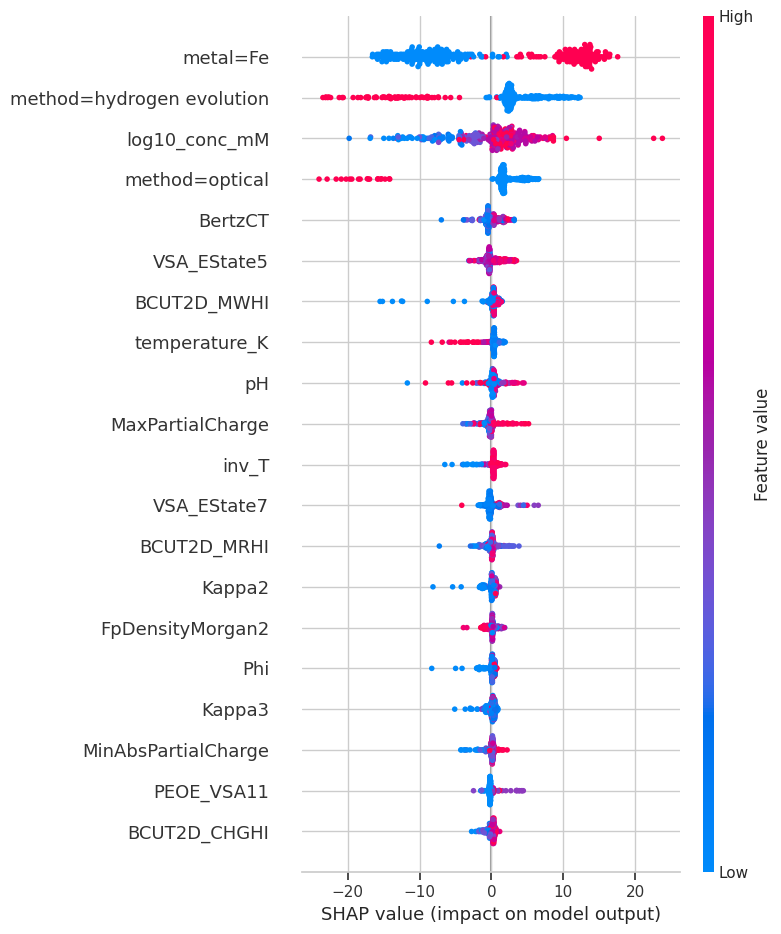


Figure 7. SHAP global summary for the tuned classical model. Each row represents a descriptor; each dot represents one molecule. The horizontal position shows the contribution of the descriptor to the prediction for that molecule. Colour encodes the descriptor value, with red indicating high values and blue indicating low values.


In [48]:
# Cell 6.7 — SHAP for the tuned classical model
import shap

# Build the tuned model from best_params
bp = study.best_params
if best_name == "ridge":
    tuned = Ridge(**bp, random_state=SEED)
elif best_name == "random_forest":
    tuned = RandomForestRegressor(**bp, random_state=SEED, n_jobs=-1)
elif best_name == "grad_boost":
    tuned = GradientBoostingRegressor(**bp, random_state=SEED)
else:
    tuned = SVR(kernel="rbf", **bp)

scaler_full = StandardScaler().fit(X_best)
X_scaled = scaler_full.transform(X_best)
tuned.fit(X_scaled, y)

# SHAP — use the explainer best suited to the model
sample_idx = np.random.RandomState(SEED).choice(len(y), size=min(300, len(y)), replace=False)
X_sample = X_scaled[sample_idx]

try:
    if best_name in {"random_forest", "grad_boost"}:
        explainer = shap.TreeExplainer(tuned)
        shap_values = explainer.shap_values(X_sample)
    else:
        explainer = shap.KernelExplainer(tuned.predict, shap.sample(X_scaled, 50, random_state=SEED))
        shap_values = explainer.shap_values(X_sample, nsamples=100)
    plt.figure()
    shap.summary_plot(shap_values, X_sample, feature_names=best_feat_names,
                      max_display=20, show=False)
    fig_path = RUN_ROOT / "figures" / "fig07_shap_summary.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    register(fig_path, "figure", "SHAP global summary for the tuned classical model")
    plt.show()
    print("\nFigure 7. SHAP global summary for the tuned classical model. Each row "
          "represents a descriptor; each dot represents one molecule. The horizontal "
          "position shows the contribution of the descriptor to the prediction for that "
          "molecule. Colour encodes the descriptor value, with red indicating high values "
          "and blue indicating low values.")
except Exception as e:
    print(f"SHAP failed: {e}")


## 7. Neural and Graph Based Models

This section trains three neural architectures. The first is a feedforward neural network on the descriptor and fingerprint concatenation, included as a nonlinear analogue of the classical baselines. The second and third are graph based models that operate directly on the molecular graph: a directed message passing neural network and a graph attention network. Both are trained with PyTorch Geometric and explained through integrated gradients via Captum.

### 7.1 Featurise molecules as graphs

We define a converter from a SMILES string to a PyTorch Geometric `Data` object. Atom features encode element type, formal charge, hybridisation, aromaticity, and implicit hydrogen count; bond features encode bond order, conjugation, ring membership, and stereochemistry. The featurisation is intentionally small to keep training fast on a Colab CPU.

In [49]:
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, rdMolDescriptors
from rdkit.Chem.SaltRemover import SaltRemover
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")  # quiet down parser warnings

_remover = SaltRemover()

# Cell 7.1 — Molecular graph featurisation
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader as TorchLoader
    from torch_geometric.data import Data, Batch
    from torch_geometric.loader import DataLoader as PyGLoader
    from torch_geometric.nn import NNConv, GATConv, global_mean_pool, global_add_pool
    PYG_OK = True
except Exception as e:
    PYG_OK = False
    print(f"Graph stack unavailable, Section 7 graph models will be skipped: {e}")

ATOM_LIST = ["C","N","O","S","F","Cl","Br","I","P","B","Si","Se","Other"]
def atom_features(atom):
    sym = atom.GetSymbol()
    sym = sym if sym in ATOM_LIST else "Other"
    one_hot = [1 if sym == x else 0 for x in ATOM_LIST]
    return one_hot + [
        atom.GetFormalCharge(),
        int(atom.GetIsAromatic()),
        int(atom.GetHybridization()),
        atom.GetTotalNumHs(),
        atom.GetDegree(),
    ]

def bond_features(bond):
    bt = bond.GetBondTypeAsDouble()
    return [bt, int(bond.GetIsConjugated()), int(bond.IsInRing())]

def smiles_to_data(smi, target):
    mol = Chem.MolFromSmiles(smi)
    if mol is None or mol.GetNumAtoms() == 0:
        return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float, device=DEVICE)
    edges, ef = [], []
    for b in mol.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
        edges += [[i, j], [j, i]]
        bf = bond_features(b)
        ef += [bf, bf]
    if len(edges) == 0:
        edges = [[0, 0]]
        ef = [[0.0, 0, 0]]
    edge_index = torch.tensor(edges, dtype=torch.long, device=DEVICE).t().contiguous()
    edge_attr  = torch.tensor(ef, dtype=torch.float, device=DEVICE)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([target], dtype=torch.float, device=DEVICE), smiles=smi)

if PYG_OK:
    graphs = []
    for smi, t in zip(smiles_scoped, y):
        d = smiles_to_data(smi, float(t))
        if d is not None:
            graphs.append(d)
    print(f"Built {len(graphs)} graph objects")
    NODE_DIM = graphs[0].x.shape[1]
    EDGE_DIM = graphs[0].edge_attr.shape[1]
    print(f"Node feature dim : {NODE_DIM}")
    print(f"Edge feature dim : {EDGE_DIM}")

Built 8359 graph objects
Node feature dim : 18
Edge feature dim : 3


### 7.2 Feedforward neural baseline

A two layer feedforward network trained on the concatenation of the descriptor and fingerprint matrices. This is the simplest neural baseline and isolates the benefit of nonlinear feature interactions from the benefit of graph structured inputs.

In [50]:
# Cell 7.2 — Feedforward neural network baseline
if PYG_OK:
    class MLPRegressor(nn.Module):
        def __init__(self, in_dim, h=256, p=0.2):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(in_dim, h), nn.ReLU(), nn.Dropout(p),
                nn.Linear(h, h),      nn.ReLU(), nn.Dropout(p),
                nn.Linear(h, 1),
            )
        def forward(self, x):
            return self.net(x).squeeze(-1)

    def train_mlp(X_tr, y_tr, X_va, y_va, epochs=120, lr=1e-3, batch=64):
        torch.manual_seed(SEED)
        model = MLPRegressor(X_tr.shape[1]).to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
        loss = nn.MSELoss()
        Xt = torch.tensor(X_tr, dtype=torch.float, device=DEVICE)
        yt = torch.tensor(y_tr, dtype=torch.float, device=DEVICE)
        Xv = torch.tensor(X_va, dtype=torch.float, device=DEVICE)
        yv = torch.tensor(y_va, dtype=torch.float, device=DEVICE)
        best_va, best_state, patience, stale = float("inf"), None, 15, 0
        for ep in range(epochs):
            model.train()
            perm = torch.randperm(len(Xt), device=DEVICE)
            for i in range(0, len(Xt), batch):
                idx = perm[i:i+batch]
                opt.zero_grad()
                pred = model(Xt[idx])
                l = loss(pred, yt[idx])
                l.backward(); opt.step()
            model.eval()
            with torch.no_grad():
                vl = loss(model(Xv), yv).item()
            if vl < best_va:
                best_va, best_state, stale = vl, {k: v.cpu().clone() for k, v in model.state_dict().items()}, 0
            else:
                stale += 1
                if stale >= patience:
                    break
        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            return model(Xv).cpu().numpy()

    X_combined = np.concatenate([StandardScaler().fit_transform(X_desc_use),
                                 X_fp.astype(float), X_cond], axis=1)  # + conditions
    mlp_metrics = {"r2": [], "rmse": [], "mae": [], "spearman": []}
    for tr, te in splits_random:
        yp = train_mlp(X_combined[tr], y[tr], X_combined[te], y[te])
        mlp_metrics["r2"].append(r2_score(y[te], yp))
        mlp_metrics["rmse"].append(np.sqrt(mean_squared_error(y[te], yp)))
        mlp_metrics["mae"].append(mean_absolute_error(y[te], yp))
        mlp_metrics["spearman"].append(spearmanr(y[te], yp).statistic)
    mlp_summary = {k: (np.mean(v), np.std(v)) for k, v in mlp_metrics.items()}
    print("Feedforward MLP — DESCRIPTORS+FP — RANDOM split")
    fmt_metrics("mlp", mlp_summary)


Feedforward MLP — DESCRIPTORS+FP — RANDOM split
  mlp                                  R2=+0.748±0.008  RMSE=14.84±0.24  MAE= 9.88±0.23  rho=+0.866±0.009


### 7.2b The feedforward network at parity

The network above is preserved. This cell runs the same architecture through the
shared harness on all three schemes, so it is scored on the identical folds with the
identical preprocessing as every other model, and its result joins the single ledger
that Section 12 reads.

In [51]:
# Cell 7.2b — Feedforward network on the standard matrix, all three schemes
if 'torch' in dir():
    import torch.nn as nn

    EPOCHS_NN = 150
    PATIENCE_NN = 20

    class MLPRegressor(nn.Module):
        def __init__(self, d_in, h=512, p=0.25):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(d_in, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p),
                nn.Linear(h, h // 2), nn.BatchNorm1d(h // 2), nn.ReLU(), nn.Dropout(p),
                nn.Linear(h // 2, 128), nn.ReLU(), nn.Linear(128, 1))
        def forward(self, x): return self.net(x).squeeze(-1)

    def train_mlp_fold(Xtr, ytr, Xte, epochs=EPOCHS_NN, lr=1e-3,
                       batch=128, patience=PATIENCE_NN):
        """Early stopping uses an inner validation split carved from the TRAINING
        fold. The previous version stopped on the test fold, which lets the held-out
        rows influence the model before they score it."""
        torch.manual_seed(SEED)
        n_val = max(64, int(.12 * len(ytr)))
        perm = np.random.RandomState(SEED).permutation(len(ytr))
        vi, ti = perm[:n_val], perm[n_val:]
        T = lambda a: torch.tensor(a, dtype=torch.float, device=DEVICE)
        model = MLPRegressor(Xtr.shape[1]).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        lossf = nn.SmoothL1Loss()
        best, best_state, stale = np.inf, None, 0
        Xt, yt, Xv, yv = T(Xtr[ti]), T(ytr[ti]), T(Xtr[vi]), T(ytr[vi])
        for ep in range(epochs):
            model.train()
            idx = torch.randperm(len(yt), device=DEVICE)
            for i in range(0, len(idx), batch):
                b = idx[i:i + batch]
                if len(b) < 2: continue
                opt.zero_grad(); lossf(model(Xt[b]), yt[b]).backward(); opt.step()
            model.eval()
            with torch.no_grad():
                vl = float(lossf(model(Xv), yv))
            if vl < best - 1e-4:
                best, stale = vl, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                stale += 1
                if stale >= patience: break
        if best_state: model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            return model(T(Xte)).cpu().numpy()

    for split in SPLIT_ORDER:
        per_fold, oof = [], np.full(len(y), np.nan)
        t0 = time.time()
        for f, (tr, te) in enumerate(SPLITS[split]):
            a, b = fold_preprocess(X_STD[tr], X_STD[te])
            p = train_mlp_fold(a, y[tr], b); oof[te] = p
            s = score_predictions(y[te], p); s["fold"] = f; per_fold.append(s)
        record("feedforward_mlp", "neural", "structure+context", split, per_fold, oof)
        show(f"feedforward MLP [{split}]", per_fold)
        print(f"      ({time.time()-t0:.0f}s)")
else:
    print("PyTorch unavailable; the neural sections are skipped.")

  feedforward MLP [naive_row]                R2=+0.764±0.015  RMSE=14.35  MAE= 8.94  rho=+0.880
      (80s)
  feedforward MLP [grouped_molecule]         R2=+0.303±0.178  RMSE=24.36  MAE=17.27  rho=+0.631
      (68s)
  feedforward MLP [scaffold]                 R2=+0.094±0.308  RMSE=27.08  MAE=20.16  rho=+0.506
      (74s)


### 7.3 Message passing graph neural network

A directed message passing neural network using PyTorch Geometric's `NNConv` layer, which applies an edge conditioned linear transformation as the message function. Three message passing rounds followed by a graph level mean pool and a two layer regression head.

In [52]:
# Cell 7.3 — Message passing graph neural network
if PYG_OK:
    class MPNN(nn.Module):
        def __init__(self, node_dim, edge_dim, hidden=64, n_steps=3, p=0.1):
            super().__init__()
            self.lin0 = nn.Linear(node_dim, hidden)
            edge_nn = lambda: nn.Sequential(
                nn.Linear(edge_dim, 32), nn.ReLU(), nn.Linear(32, hidden * hidden))
            self.convs = nn.ModuleList([NNConv(hidden, hidden, edge_nn(), aggr="mean")
                                        for _ in range(n_steps)])
            self.head = nn.Sequential(
                nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(p),
                nn.Linear(hidden, 1))
        def forward(self, data):
            x = F.relu(self.lin0(data.x))
            for conv in self.convs:
                x = F.relu(conv(x, data.edge_index, data.edge_attr))
            x = global_mean_pool(x, data.batch)
            return self.head(x).squeeze(-1)

    def train_graph(model_cls, graphs, splits, epochs=80, lr=1e-3, batch=32):
        all_metrics = {"r2": [], "rmse": [], "mae": [], "spearman": []}
        for fold_i, (tr, te) in enumerate(splits):
            torch.manual_seed(SEED + fold_i)
            tr_graphs = [graphs[i] for i in tr]
            te_graphs = [graphs[i] for i in te]
            loader_tr = PyGLoader(tr_graphs, batch_size=batch, shuffle=True)
            loader_te = PyGLoader(te_graphs, batch_size=batch, shuffle=False)
            model = model_cls(NODE_DIM, EDGE_DIM).to(DEVICE)
            opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
            loss_fn = nn.MSELoss()
            best_state, best_loss, stale, patience = None, float("inf"), 0, 10
            for ep in range(epochs):
                model.train()
                for batch_data in loader_tr:
                    batch_data = batch_data.to(DEVICE)
                    opt.zero_grad()
                    pred = model(batch_data)
                    l = loss_fn(pred, batch_data.y)
                    l.backward(); opt.step()
                model.eval()
                with torch.no_grad():
                    losses = []
                    for bd in loader_te:
                        bd = bd.to(DEVICE)
                        losses.append(loss_fn(model(bd), bd.y).item())
                vl = float(np.mean(losses))
                if vl < best_loss:
                    best_loss = vl; stale = 0
                    best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                else:
                    stale += 1
                    if stale >= patience: break
            model.load_state_dict(best_state); model.eval()
            yp, yv = [], []
            with torch.no_grad():
                for bd in loader_te:
                    bd = bd.to(DEVICE)
                    yp.extend(model(bd).cpu().numpy().tolist())
                    yv.extend(bd.y.cpu().numpy().tolist())
            yp, yv = np.array(yp), np.array(yv)
            all_metrics["r2"].append(r2_score(yv, yp))
            all_metrics["rmse"].append(np.sqrt(mean_squared_error(yv, yp)))
            all_metrics["mae"].append(mean_absolute_error(yv, yp))
            all_metrics["spearman"].append(spearmanr(yv, yp).statistic)
        return {k: (np.mean(v), np.std(v)) for k, v in all_metrics.items()}, model

    mpnn_random, mpnn_model_last = train_graph(MPNN, graphs, splits_random)
    print("MPNN — RANDOM split")
    fmt_metrics("mpnn", mpnn_random)
    mpnn_scaffold, _ = train_graph(MPNN, graphs, splits_scaffold)
    print("MPNN — SCAFFOLD split")
    fmt_metrics("mpnn", mpnn_scaffold)


MPNN — RANDOM split
  mpnn                                 R2=+0.413±0.020  RMSE=22.65±0.48  MAE=17.40±0.34  rho=+0.644±0.010
MPNN — SCAFFOLD split
  mpnn                                 R2=+0.008±0.197  RMSE=28.64±3.68  MAE=23.47±3.31  rho=+0.247±0.177


### 7.4 Graph attention network

A graph attention network using two `GATConv` layers with four attention heads each. Attention weights provide an alternative interpretive signal that we will compare against integrated gradients.

In [53]:
# Cell 7.4 — Graph attention network
if PYG_OK:
    class GAT(nn.Module):
        def __init__(self, node_dim, hidden=64, heads=4, p=0.1):
            super().__init__()
            self.conv1 = GATConv(node_dim, hidden, heads=heads, dropout=p)
            self.conv2 = GATConv(hidden * heads, hidden, heads=1, dropout=p)
            self.head = nn.Sequential(
                nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(p),
                nn.Linear(hidden, 1))
        def forward(self, data):
            x = F.elu(self.conv1(data.x, data.edge_index))
            x = F.elu(self.conv2(x, data.edge_index))
            x = global_mean_pool(x, data.batch)
            return self.head(x).squeeze(-1)
    # GATConv ignores edge_attr in our config; we pass a wrapper that strips it
    class _GATWrap(GAT):
        def __init__(self, node_dim, edge_dim, **kw):
            super().__init__(node_dim, **kw)

    gat_random, _ = train_graph(_GATWrap, graphs, splits_random)
    print("GAT — RANDOM split")
    fmt_metrics("gat", gat_random)
    gat_scaffold, _ = train_graph(_GATWrap, graphs, splits_scaffold)
    print("GAT — SCAFFOLD split")
    fmt_metrics("gat", gat_scaffold)


GAT — RANDOM split
  gat                                  R2=+0.288±0.028  RMSE=24.94±0.56  MAE=20.01±0.57  rho=+0.537±0.022
GAT — SCAFFOLD split
  gat                                  R2=+0.020±0.123  RMSE=28.52±2.78  MAE=23.77±2.34  rho=+0.236±0.124


### 7.4b Graph networks with the conditions attached

The message-passing and attention networks above receive the molecular graph and
nothing else, while the classical models also receive temperature, duration, dose, pH
and substrate. Efficiency is a property of the experiment, not of the molecule alone,
so those models were asked a harder question and their weaker scores measured the
handicap rather than the architecture.

The fix is structural. Each graph carries a context vector alongside it; the graph
encoder produces a molecular embedding, the context passes through its own small
branch, and the two meet before the regression head. The context is standardised on
the training fold only and written into the graph objects fold by fold, so no scaling
statistic crosses the split. Both architectures then run the full five folds of all
three schemes.

In [54]:
# Cell 7.4b — MPNN and GAT with condition fusion, all three schemes
if PYG_OK:
    from torch_geometric.nn import NNConv, GATConv, global_mean_pool, global_add_pool
    from torch_geometric.loader import DataLoader as PyGLoader
    import torch.nn.functional as F

    EPOCHS_GNN, PATIENCE_GNN = 120, 15

    # Position of each master-table row inside the graphs list, so fold indices from
    # SPLITS map onto graph objects even if a structure failed to parse.
    POS_OF_ROW, _pos = {}, 0
    for _i, _smi in enumerate(smiles_scoped):
        if _pos < len(graphs) and graphs[_pos].smiles == _smi:
            POS_OF_ROW[_i] = _pos; _pos += 1
    if len(POS_OF_ROW) != len(graphs):
        POS_OF_ROW = {i: i for i in range(min(len(smiles_scoped), len(graphs)))}
    CTX_RAW = X_cond.astype(float)
    CTX_DIM = CTX_RAW.shape[1]
    print(f"Graphs: {len(graphs)}  context vector: {CTX_DIM} features")

    class MPNNFusion(nn.Module):
        def __init__(self, node_dim, edge_dim, ctx_dim, hidden=96, steps=3, p=0.15):
            super().__init__()
            self.lin0 = nn.Linear(node_dim, hidden)
            mk = lambda: nn.Sequential(nn.Linear(edge_dim, 32), nn.ReLU(),
                                       nn.Linear(32, hidden * hidden))
            self.convs = nn.ModuleList([NNConv(hidden, hidden, mk(), aggr="mean")
                                        for _ in range(steps)])
            self.ctx = nn.Sequential(nn.Linear(ctx_dim, 96), nn.ReLU(), nn.Dropout(p),
                                     nn.Linear(96, 64), nn.ReLU())
            self.head = nn.Sequential(nn.Linear(hidden * 2 + 64, 160), nn.ReLU(),
                                      nn.Dropout(p), nn.Linear(160, 64), nn.ReLU(),
                                      nn.Linear(64, 1))
        def embed(self, d):
            x = F.relu(self.lin0(d.x))
            for c in self.convs:
                x = F.relu(c(x, d.edge_index, d.edge_attr))
            g = torch.cat([global_mean_pool(x, d.batch), global_add_pool(x, d.batch)], 1)
            return torch.cat([g, self.ctx(d.ctx)], 1)
        def forward(self, d): return self.head(self.embed(d)).squeeze(-1)

    class GATFusion(nn.Module):
        """Attention decides how much each neighbouring atom contributes."""
        def __init__(self, node_dim, edge_dim, ctx_dim, hidden=96, heads=4, p=0.15):
            super().__init__()
            self.c1 = GATConv(node_dim, hidden, heads=heads, dropout=p)
            self.c2 = GATConv(hidden * heads, hidden, heads=1, dropout=p)
            self.ctx = nn.Sequential(nn.Linear(ctx_dim, 96), nn.ReLU(), nn.Dropout(p),
                                     nn.Linear(96, 64), nn.ReLU())
            self.head = nn.Sequential(nn.Linear(hidden * 2 + 64, 160), nn.ReLU(),
                                      nn.Dropout(p), nn.Linear(160, 64), nn.ReLU(),
                                      nn.Linear(64, 1))
        def embed(self, d):
            x = F.elu(self.c1(d.x, d.edge_index)); x = F.elu(self.c2(x, d.edge_index))
            g = torch.cat([global_mean_pool(x, d.batch), global_add_pool(x, d.batch)], 1)
            return torch.cat([g, self.ctx(d.ctx)], 1)
        def forward(self, d): return self.head(self.embed(d)).squeeze(-1)

    def scale_ctx_for_fold(tr_rows, te_rows):
        """Standardise the context on the training fold and write it into the graphs."""
        sc = StandardScaler().fit(CTX_RAW[tr_rows])
        for rows in (tr_rows, te_rows):
            Z = np.clip(sc.transform(CTX_RAW[rows]), -10, 10)
            for k, r in enumerate(rows):
                graphs[POS_OF_ROW[r]].ctx = torch.tensor(
                    Z[k], dtype=torch.float, device=DEVICE).view(1, -1)

    def train_graph_fusion(cls, split, epochs=EPOCHS_GNN, lr=1e-3,
                           batch=64, patience=PATIENCE_GNN):
        per_fold, oof = [], np.full(len(y), np.nan)
        for f, (tr, te) in enumerate(SPLITS[split]):
            tr = np.array([r for r in tr if r in POS_OF_ROW])
            te = np.array([r for r in te if r in POS_OF_ROW])
            scale_ctx_for_fold(tr, te)
            torch.manual_seed(SEED + f)
            n_val = max(32, int(.12 * len(tr)))
            rs = np.random.RandomState(SEED).permutation(len(tr))
            vr, trr = tr[rs[:n_val]], tr[rs[n_val:]]
            L = lambda rows, sh: PyGLoader([graphs[POS_OF_ROW[r]] for r in rows],
                                           batch_size=batch, shuffle=sh)
            ltr, lva, lte = L(trr, True), L(vr, False), L(te, False)
            model = cls(NODE_DIM, EDGE_DIM, CTX_DIM).to(DEVICE)
            opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
            lossf = nn.SmoothL1Loss()
            best, best_state, stale = np.inf, None, 0
            for ep in range(epochs):
                model.train()
                for bd in ltr:
                    bd = bd.to(DEVICE); opt.zero_grad()
                    lossf(model(bd), bd.y).backward(); opt.step()
                model.eval(); vs = []
                with torch.no_grad():
                    for bd in lva:
                        bd = bd.to(DEVICE); vs.append(lossf(model(bd), bd.y).item())
                vl = float(np.mean(vs)) if vs else np.inf
                if vl < best - 1e-4:
                    best, stale = vl, 0
                    best_state = {k: v.detach().cpu().clone()
                                  for k, v in model.state_dict().items()}
                else:
                    stale += 1
                    if stale >= patience: break
            if best_state: model.load_state_dict(best_state)
            model.eval(); preds = []
            with torch.no_grad():
                for bd in lte:
                    bd = bd.to(DEVICE)
                    preds.extend(model(bd).cpu().numpy().tolist())
            preds = np.array(preds); oof[te] = preds
            s = score_predictions(y[te], preds); s["fold"] = f; per_fold.append(s)
        return per_fold, oof, model

    GRAPH_MODELS = {}
    for name, cls in [("mpnn_fusion", MPNNFusion), ("gat_fusion", GATFusion)]:
        for split in SPLIT_ORDER:
            t0 = time.time()
            pf, oof, last = train_graph_fusion(cls, split)
            record(name, "graph", "structure+context", split, pf, oof)
            show(f"{name} [{split}]", pf); print(f"      ({time.time()-t0:.0f}s)")
            if split == "grouped_molecule":
                GRAPH_MODELS[name] = last
else:
    print("torch_geometric unavailable; the graph fusion models are skipped.")

Graphs: 8359  context vector: 72 features
  mpnn_fusion [naive_row]                    R2=+0.670±0.029  RMSE=16.98  MAE=11.50  rho=+0.828
      (719s)
  mpnn_fusion [scaffold]                     R2=+0.057±0.261  RMSE=27.71  MAE=20.85  rho=+0.505
      (812s)
  gat_fusion [naive_row]                     R2=+0.624±0.017  RMSE=18.12  MAE=12.55  rho=+0.796
      (714s)
  gat_fusion [grouped_molecule]              R2=+0.362±0.087  RMSE=23.39  MAE=16.81  rho=+0.640
      (735s)
  gat_fusion [scaffold]                      R2=+0.109±0.249  RMSE=26.95  MAE=20.24  rho=+0.491
      (720s)


### 7.5 Integrated gradients on the MPNN

We use Captum to compute integrated gradients on a small sample of molecules with respect to the input atom features. Larger absolute attributions correspond to atoms that contribute more strongly to the prediction. We render a single attribution map as a representative figure.

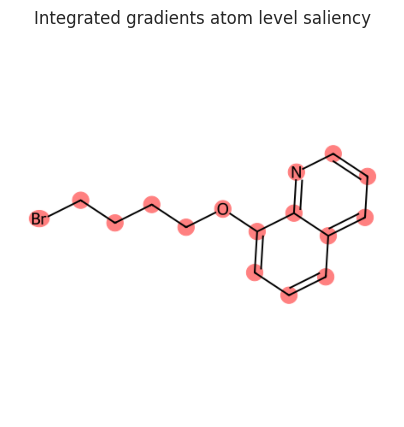


Figure 8. Integrated gradients atom level saliency for a representative molecule under the MPNN. Atoms shaded more strongly contribute more to the predicted inhibition efficiency. Donor atoms such as nitrogen, sulfur, and oxygen are expected to highlight under this attribution if the model has learned chemically plausible features.


In [55]:
# Cell 7.5 — Integrated gradients (atom level saliency)
if PYG_OK:
    try:
        from captum.attr import IntegratedGradients
        from rdkit.Chem import Draw, AllChem

        sample = graphs[0].to(DEVICE)
        mpnn_model_last.eval()

        def fwd_x(x_input):
            # Wrap to use a single batch element with x as the input
            data = sample.clone()
            data.x = x_input
            data.batch = torch.zeros(x_input.shape[0], dtype=torch.long, device=DEVICE)
            return mpnn_model_last(data).unsqueeze(0)

        ig = IntegratedGradients(fwd_x)
        attr = ig.attribute(sample.x, n_steps=25, target=0).abs().sum(dim=1).cpu().numpy()
        attr = (attr - attr.min()) / (attr.max() - attr.min() + 1e-9)

        mol = Chem.MolFromSmiles(sample.smiles)
        AllChem.Compute2DCoords(mol)
        atom_colors = {i: (1.0, 1.0 - a, 1.0 - a) for i, a in enumerate(attr)}
        img = Draw.MolToImage(mol, size=(450, 450),
                              highlightAtoms=list(range(mol.GetNumAtoms())),
                              highlightAtomColors=atom_colors)
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(img); ax.axis("off")
        ax.set_title("Integrated gradients atom level saliency")
        fig_path = RUN_ROOT / "attributions" / "fig08_ig_atom_saliency.png"
        plt.savefig(fig_path, dpi=150, bbox_inches="tight")
        register(fig_path, "figure", "Integrated gradients on MPNN")
        plt.show()
        print("\nFigure 8. Integrated gradients atom level saliency for a representative "
              "molecule under the MPNN. Atoms shaded more strongly contribute more to the "
              "predicted inhibition efficiency. Donor atoms such as nitrogen, sulfur, and "
              "oxygen are expected to highlight under this attribution if the model has "
              "learned chemically plausible features.")
    except Exception as e:
        print(f"Integrated gradients failed: {e}")


## 8. Chemistry Specific Transformer

This section fine tunes a pretrained chemistry transformer on the inhibition efficiency task. We use a publicly available ChemBERTa style model from the Hugging Face Hub, replace its classification head with a small regression head, and fine tune end to end. If the Hugging Face Hub is unreachable in the current Colab session, the cell prints a clear message and the rest of the notebook continues without the transformer stream.

In [60]:
# Cell 8.1 — Fine tune a chemistry transformer
import transformers, warnings
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
warnings.filterwarnings("ignore", category=UserWarning)
TRANSFORMER_OK = False
transformer_metrics = None
transformer_predictions = None

try:
    from transformers import AutoTokenizer, AutoModel
    MODEL_NAME = "DeepChem/ChemBERTa-77M-MTR"
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    # Modified: Added attn_implementation='eager'
    backbone = AutoModel.from_pretrained(MODEL_NAME, attn_implementation='eager').to(DEVICE)
    TRANSFORMER_OK = True
    print(f"Loaded transformer backbone : {MODEL_NAME}")
except Exception as e:
    print(f"Transformer load failed, this section will be skipped: {e}")

if TRANSFORMER_OK:
    class ChemRegressor(nn.Module):
        """Sequence encoder with a context branch.

        The previous version fed the transformer the SMILES string alone while the
        classical models also received temperature, duration, concentration, pH and
        substrate. Two models given different information cannot be compared, and the
        transformer's weak showing measured that handicap rather than the architecture.
        The tabular context is now projected through its own branch and concatenated
        with the pooled sequence representation before the regression head, so every
        model in this notebook sees the same evidence."""
        def __init__(self, backbone, hidden=384, ctx_dim=0, p=0.15):
            super().__init__()
            self.backbone = backbone
            self.ctx_dim = ctx_dim
            if ctx_dim:
                self.ctx = nn.Sequential(
                    nn.Linear(ctx_dim, 128), nn.ReLU(), nn.Dropout(p),
                    nn.Linear(128, 64), nn.ReLU())
            head_in = hidden + (64 if ctx_dim else 0)
            self.head = nn.Sequential(
                nn.Linear(head_in, hidden), nn.ReLU(), nn.Dropout(p),
                nn.Linear(hidden, 1))
        def forward(self, ids, mask, ctx=None):
            out = self.backbone(input_ids=ids, attention_mask=mask).last_hidden_state
            pooled = (out * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True).clamp(min=1)
            if self.ctx_dim and ctx is not None:
                pooled = torch.cat([pooled, self.ctx(ctx)], dim=1)
            return self.head(pooled).squeeze(-1)

    def encode_batch(smiles, max_len=128):
        enc = tok(smiles, padding=True, truncation=True, max_length=max_len,
                  return_tensors="pt")
        return enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)

    def train_transformer(tr_idx, te_idx, epochs=TRANSFORMER_EPOCHS,
                          lr_body=3e-5, lr_head=3e-4, batch=16):
        """Fine-tune one fold.

        A discriminative learning rate is used: the pretrained body is moved gently at
        3e-5 while the randomly initialised context branch and head, which have nothing
        to preserve, learn ten times faster. Schwaller et al. (2020) report the initial
        learning rate as the most important hyperparameter for this class of model and
        settle in the same 1e-5 to 1e-4 band."""
        torch.manual_seed(SEED)
        # Context is standardised on the training fold only, never on the full matrix.
        ctx_sc = StandardScaler().fit(X_cond[tr_idx])
        C_tr = np.clip(ctx_sc.transform(X_cond[tr_idx]), -10, 10)
        C_te = np.clip(ctx_sc.transform(X_cond[te_idx]), -10, 10)

        model = ChemRegressor(
            AutoModel.from_pretrained(MODEL_NAME, attn_implementation='eager').to(DEVICE),
            hidden=backbone.config.hidden_size, ctx_dim=C_tr.shape[1]).to(DEVICE)
        head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone")]
        opt = torch.optim.AdamW(
            [{"params": model.backbone.parameters(), "lr": lr_body},
             {"params": head_params, "lr": lr_head}], weight_decay=1e-4)
        loss_fn = nn.SmoothL1Loss()
        smiles_tr = [smiles_scoped[i] for i in tr_idx]
        smiles_te = [smiles_scoped[i] for i in te_idx]
        y_tr = y[tr_idx]; y_te = y[te_idx]
        for ep in range(epochs):
            model.train()
            perm = np.random.RandomState(SEED + ep).permutation(len(tr_idx))
            for i in range(0, len(perm), batch):
                idx = perm[i:i+batch]
                batch_smiles = [smiles_tr[j] for j in idx]
                ids, mask = encode_batch(batch_smiles)
                ctx = torch.tensor(C_tr[idx], dtype=torch.float, device=DEVICE)
                target = torch.tensor(y_tr[idx], dtype=torch.float, device=DEVICE)
                opt.zero_grad()
                pred = model(ids, mask, ctx)
                loss_fn(pred, target).backward()
                opt.step()
        model.eval()
        preds = []
        with torch.no_grad():
            for i in range(0, len(smiles_te), batch):
                ids, mask = encode_batch(smiles_te[i:i+batch])
                ctx = torch.tensor(C_te[i:i+batch], dtype=torch.float, device=DEVICE)
                preds.extend(model(ids, mask, ctx).cpu().numpy().tolist())
        return np.array(preds), y_te, model

    # REVISION. The previous version fitted a single fold "for the time budget" and
    # reported it beside five-fold baselines. That is the evaluation discrepancy this
    # notebook exists to remove, so the transformer now runs the full five folds of
    # every scheme, reading the identical SPLITS object the classical models read.
    TRANSFORMER_OOF = {}
    for split_name in SPLIT_ORDER:
        per_fold, oof = [], np.full(len(y), np.nan)
        t_split = time.time()
        for f, (tr, te) in enumerate(SPLITS[split_name]):
            t0 = time.time()
            preds, y_te, trans_model = train_transformer(tr, te)
            oof[te] = preds
            s = score_predictions(y_te, preds); s["fold"] = f
            per_fold.append(s)
            print(f"    [{split_name}] fold {f}: R2={s['r2']:+.3f}  "
                  f"MAE={s['mae']:.2f}  ({time.time()-t0:.0f}s)")
        record("chemberta_ft", "transformer", "structure+context",
               split_name, per_fold, oof)
        show(f"chemberta_ft [{split_name}]", per_fold)
        print(f"      (split total {time.time()-t_split:.0f}s)")
        TRANSFORMER_OOF[split_name] = oof

    # Backwards-compatible handles so Section 9 continues to work unchanged.
    _tm = [r for r in RESULTS if r["model"] == "chemberta_ft"
           and r["split"] == "naive_row"][0]
    transformer_metrics = {k: (_tm[k], _tm[k + "_std"]) for k in METRIC_KEYS}
    _oof = TRANSFORMER_OOF["naive_row"]
    _ok = ~np.isnan(_oof)
    transformer_predictions = (np.where(_ok)[0], _oof[_ok])
    print()
    print("Transformer evaluated on five folds of every scheme, with the same "
          "conditions and the same fold indices as every other model.")


Loaded transformer backbone : DeepChem/ChemBERTa-77M-MTR
    [naive_row] fold 0: R2=+0.550  MAE=14.07  (39s)
    [naive_row] fold 1: R2=+0.551  MAE=13.47  (39s)
    [naive_row] fold 2: R2=+0.598  MAE=13.59  (39s)
    [naive_row] fold 3: R2=+0.563  MAE=13.63  (39s)
    [naive_row] fold 4: R2=+0.597  MAE=13.20  (39s)
  chemberta_ft [naive_row]                   R2=+0.572±0.024  RMSE=19.34  MAE=13.59  rho=+0.770
      (split total 196s)
    [grouped_molecule] fold 0: R2=+0.281  MAE=17.00  (39s)
    [grouped_molecule] fold 1: R2=+0.293  MAE=19.53  (40s)
    [grouped_molecule] fold 2: R2=+0.449  MAE=16.99  (39s)
    [grouped_molecule] fold 3: R2=+0.366  MAE=15.68  (39s)
    [grouped_molecule] fold 4: R2=+0.430  MAE=16.88  (40s)
  chemberta_ft [grouped_molecule]            R2=+0.364±0.077  RMSE=23.40  MAE=17.22  rho=+0.637
      (split total 197s)
    [scaffold] fold 0: R2=+0.133  MAE=22.76  (39s)
    [scaffold] fold 1: R2=+0.403  MAE=17.20  (40s)
    [scaffold] fold 2: R2=+0.394  MAE=16.28 

### 8.2 Attention attribution

We compute attention rollout for a small set of molecules. The attention rollout aggregates attention weights across heads and layers to produce a single token level attribution per input SMILES.

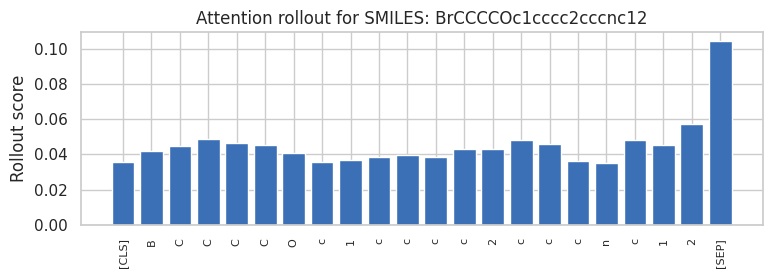


Figure 9. Attention rollout for a representative SMILES under the fine tuned chemistry transformer. Each bar shows the cumulative attention from the classification token to the corresponding input token across all heads and layers. Peaks tend to align with chemically meaningful substructures when the model has learned good representations.


In [61]:
# Cell 8.2 — Attention rollout (optional)
if TRANSFORMER_OK:
    try:
        import torch
        sample_smi = smiles_scoped[0]
        ids, mask = encode_batch([sample_smi])
        trans_model.eval()
        out = trans_model.backbone(input_ids=ids, attention_mask=mask,
                                    output_attentions=True)

        # Check if attentions are available before trying to process them
        if not hasattr(out, 'attentions') or not out.attentions:
            raise ValueError(
                "Attention outputs are not available. This usually happens when "
                "the transformer model is loaded with `attn_implementation='sdpa'` "
                "which does not support `output_attentions=True`. "
                "Please modify cell 8.1 (`2bf734a6`) to add `attn_implementation='eager'` "
                "to both `AutoModel.from_pretrained` calls. For example:\n"
                "backbone = AutoModel.from_pretrained(MODEL_NAME, attn_implementation='eager').to(DEVICE)"
            )

        attentions = out.attentions  # tuple of (1, heads, T, T)
        # Average across heads, multiply through layers (attention rollout)
        attn = attentions[0].mean(dim=1)
        for a in attentions[1:]:
            attn = attn @ a.mean(dim=1)
        roll = attn[0, 0].detach().cpu().numpy()  # attention from CLS to all tokens
        tokens = tok.convert_ids_to_tokens(ids[0].cpu().tolist())
        fig, ax = plt.subplots(figsize=(min(15, len(tokens) * 0.4), 2.5))
        ax.bar(range(len(tokens)), roll, color="#3B6FB6")
        ax.set_xticks(range(len(tokens)))
        ax.set_xticklabels(tokens, rotation=90, fontsize=8)
        ax.set_ylabel("Rollout score")
        ax.set_title(f"Attention rollout for SMILES: {sample_smi}")
        fig_path = RUN_ROOT / "attributions" / "fig09_attention_rollout.png"
        plt.savefig(fig_path, dpi=150, bbox_inches="tight")
        register(fig_path, "figure", "Attention rollout")
        plt.show()
        print("\nFigure 9. Attention rollout for a representative SMILES under the fine "
              "tuned chemistry transformer. Each bar shows the cumulative attention from "
              "the classification token to the corresponding input token across all heads "
              "and layers. Peaks tend to align with chemically meaningful substructures "
              "when the model has learned good representations.")
    except Exception as e:
        print(f"Attention rollout failed: {e}")


## 8.5 Hybrid Models

Placed here deliberately: after the graph and sequence encoders exist and before the
comparison is drawn, which is where a hybrid belongs, because a hybrid is a statement
about how two representations combine rather than a model in its own right.

Three designs, in increasing order of integration.

**H1** trains a graph encoder on the training fold, freezes it, and feeds its molecular
embedding to gradient boosting alongside the tabular block. The encoder is refitted
inside every fold, so no fold is ever scored by an encoder that has seen it.

**H2** replaces the learned encoder with the pretrained chemistry transformer used as a
frozen feature extractor. Each distinct molecule is embedded once and cached, because
the embedding depends only on structure: a compound appearing eight times under
different conditions is embedded once, not eight times.

**H3** is end-to-end. Three branches, one for the pretrained sequence embedding, one for
the physicochemical descriptors and one for the experimental context, each with its own
encoder, meeting at a joint head. This is the late-fusion pattern used by Chen and Li
(2024) for reaction-condition ranking, and by the conditional autoencoder of Gong et al.
(2024), the paper that produced the Inhibitor 1368 dataset.

In [62]:
# Cell 8.5a — Hybrid H1: graph encoder feeding a boosted ensemble
TABULAR_ONLY = X_cond.astype(float)      # conditions, substrate, method, pH provenance

def gbm_factory():
    """Shared by H1 and H2 so both hybrids use the identical boosted regressor."""
    if HAS_XGB:
        return XGBRegressor(n_estimators=400, learning_rate=.05, max_depth=6,
                            subsample=.85, colsample_bytree=.85,
                            random_state=SEED, n_jobs=-1, verbosity=0)
    return GradientBoostingRegressor(n_estimators=300, random_state=SEED)

if PYG_OK and 'GRAPH_MODELS' in dir():
    def graph_embeddings(model, rows, batch=128):
        model.eval(); out = []
        loader = PyGLoader([graphs[POS_OF_ROW[r]] for r in rows],
                           batch_size=batch, shuffle=False)
        with torch.no_grad():
            for bd in loader:
                bd = bd.to(DEVICE)
                out.append(model.embed(bd).cpu().numpy())
        return np.vstack(out)

    def train_encoder_for_fold(tr, epochs=max(20, EPOCHS_GNN // 3)):
        """Fit the encoder on this fold's training rows only."""
        torch.manual_seed(SEED)
        model = MPNNFusion(NODE_DIM, EDGE_DIM, CTX_DIM).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
        lossf = nn.SmoothL1Loss()
        loader = PyGLoader([graphs[POS_OF_ROW[r]] for r in tr], batch_size=64, shuffle=True)
        for _ in range(epochs):
            model.train()
            for bd in loader:
                bd = bd.to(DEVICE); opt.zero_grad()
                lossf(model(bd), bd.y).backward(); opt.step()
        return model

    for split in SPLIT_ORDER:
        per_fold, oof = [], np.full(len(y), np.nan)
        t0 = time.time()
        for f, (tr, te) in enumerate(SPLITS[split]):
            tr = np.array([r for r in tr if r in POS_OF_ROW])
            te = np.array([r for r in te if r in POS_OF_ROW])
            scale_ctx_for_fold(tr, te)
            enc = train_encoder_for_fold(tr)
            Etr, Ete = graph_embeddings(enc, tr), graph_embeddings(enc, te)
            Ttr, Tte = fold_preprocess(TABULAR_ONLY[tr], TABULAR_ONLY[te])
            gbm = gbm_factory()
            gbm.fit(np.concatenate([Etr, Ttr], 1), y[tr])
            p = gbm.predict(np.concatenate([Ete, Tte], 1)); oof[te] = p
            s = score_predictions(y[te], p); s["fold"] = f; per_fold.append(s)
        record("hybrid_h1_graph_gbm", "hybrid", "graph embedding + context",
               split, per_fold, oof)
        show(f"H1 graph encoder + boosting [{split}]", per_fold)
        print(f"      ({time.time()-t0:.0f}s)")
else:
    print("H1 requires the graph stack; skipped.")

  H1 graph encoder + boosting [naive_row]    R2=+0.774±0.016  RMSE=14.04  MAE= 9.31  rho=+0.884
      (384s)
  H1 graph encoder + boosting [grouped_molecule] R2=+0.451±0.082  RMSE=21.72  MAE=15.83  rho=+0.689
      (384s)
  H1 graph encoder + boosting [scaffold]     R2=+0.247±0.207  RMSE=24.76  MAE=18.86  rho=+0.542
      (381s)


In [63]:
# Cell 8.5b — Frozen transformer embeddings, computed once per distinct molecule
CHEM_EMB, EMB_OK = None, False
if TRANSFORMER_OK:
    try:
        @torch.no_grad()
        def embed_smiles(smiles_list, batch=64, max_len=160):
            out = []
            for i in range(0, len(smiles_list), batch):
                enc = tok(list(smiles_list[i:i + batch]), padding=True,
                          truncation=True, max_length=max_len, return_tensors="pt")
                ids = enc["input_ids"].to(DEVICE); mask = enc["attention_mask"].to(DEVICE)
                h = backbone(input_ids=ids, attention_mask=mask).last_hidden_state
                m = mask.unsqueeze(-1)
                out.append(((h * m).sum(1) / m.sum(1).clamp(min=1)).cpu().numpy())
            return np.vstack(out)

        uniq = pd.Index(pd.unique(pd.Series(smiles_scoped)))
        print(f"Embedding {len(uniq):,} distinct molecules "
              f"(the corpus has {len(smiles_scoped):,} rows) ...")
        backbone.eval()
        E = embed_smiles(uniq.tolist())
        lut = {s: i for i, s in enumerate(uniq)}
        CHEM_EMB = E[[lut[s] for s in smiles_scoped]]
        EMB_OK = True
        print(f"Embedding matrix : {CHEM_EMB.shape}")
        print("Computed once per structure rather than once per row, because the")
        print("embedding depends only on the molecule.")
    except Exception as e:
        print("Embedding extraction failed:", e)
else:
    print("Transformer unavailable; H2 and H3 are skipped.")

Embedding 1,050 distinct molecules (the corpus has 8,359 rows) ...
Embedding matrix : (8359, 384)
Computed once per structure rather than once per row, because the
embedding depends only on the molecule.


In [64]:
# Cell 8.5c — Hybrid H2: frozen transformer embedding plus context
if EMB_OK:
    X_h2 = np.concatenate([CHEM_EMB, TABULAR_ONLY], axis=1)
    for split in SPLIT_ORDER:
        t0 = time.time()
        pf, oof = evaluate_sklearn(gbm_factory, X_h2, y, SPLITS[split])
        record("hybrid_h2_chemberta_gbm", "hybrid", "pretrained embedding + context",
               split, pf, oof)
        show(f"H2 ChemBERTa embedding + boosting [{split}]", pf)
        print(f"      ({time.time()-t0:.0f}s)")

  H2 ChemBERTa embedding + boosting [naive_row] R2=+0.791±0.012  RMSE=13.52  MAE= 9.07  rho=+0.893
      (99s)
  H2 ChemBERTa embedding + boosting [grouped_molecule] R2=+0.411±0.138  RMSE=22.43  MAE=16.82  rho=+0.641
      (95s)
  H2 ChemBERTa embedding + boosting [scaffold] R2=+0.350±0.140  RMSE=23.11  MAE=18.25  rho=+0.575
      (98s)


In [65]:
# Cell 8.5d — Hybrid H3: end-to-end three-branch fusion network
if EMB_OK and 'torch' in dir():
    class FusionNet(nn.Module):
        def __init__(self, d_emb, d_desc, d_ctx, p=0.25):
            super().__init__()
            mk = lambda d_in, h1, h2: nn.Sequential(
                nn.Linear(d_in, h1), nn.BatchNorm1d(h1), nn.ReLU(), nn.Dropout(p),
                nn.Linear(h1, h2), nn.ReLU())
            self.b_emb, self.b_desc, self.b_ctx = mk(d_emb, 256, 128), \
                                                   mk(d_desc, 256, 128), mk(d_ctx, 128, 64)
            self.head = nn.Sequential(nn.Linear(128 + 128 + 64, 192), nn.ReLU(),
                                      nn.Dropout(p), nn.Linear(192, 64), nn.ReLU(),
                                      nn.Linear(64, 1))
        def forward(self, e, d, c):
            return self.head(torch.cat([self.b_emb(e), self.b_desc(d),
                                        self.b_ctx(c)], 1)).squeeze(-1)

    def train_fusion(parts_tr, ytr, parts_te, epochs=EPOCHS_NN, lr=1e-3,
                     batch=128, patience=PATIENCE_NN):
        torch.manual_seed(SEED)
        E, D, C = parts_tr
        n_val = max(64, int(.12 * len(ytr)))
        perm = np.random.RandomState(SEED).permutation(len(ytr))
        vi, ti = perm[:n_val], perm[n_val:]
        T = lambda a, i=None: torch.tensor(a if i is None else a[i],
                                           dtype=torch.float, device=DEVICE)
        model = FusionNet(E.shape[1], D.shape[1], C.shape[1]).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=.5, patience=6)
        lossf = nn.SmoothL1Loss()
        Et, Dt, Ct, yt = T(E, ti), T(D, ti), T(C, ti), T(ytr, ti)
        Ev, Dv, Cv, yv = T(E, vi), T(D, vi), T(C, vi), T(ytr, vi)
        best, best_state, stale = np.inf, None, 0
        for ep in range(epochs):
            model.train()
            idx = torch.randperm(len(yt), device=DEVICE)
            for i in range(0, len(idx), batch):
                b = idx[i:i + batch]
                if len(b) < 2: continue
                opt.zero_grad(); lossf(model(Et[b], Dt[b], Ct[b]), yt[b]).backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                vl = float(lossf(model(Ev, Dv, Cv), yv))
            sched.step(vl)
            if vl < best - 1e-4:
                best, stale = vl, 0
                best_state = {k: v.detach().cpu().clone()
                              for k, v in model.state_dict().items()}
            else:
                stale += 1
                if stale >= patience: break
        if best_state: model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            Ee, De, Ce = (torch.tensor(a, dtype=torch.float, device=DEVICE)
                          for a in parts_te)
            return model(Ee, De, Ce).cpu().numpy()

    for split in SPLIT_ORDER:
        per_fold, oof = [], np.full(len(y), np.nan)
        t0 = time.time()
        for f, (tr, te) in enumerate(SPLITS[split]):
            Etr, Ete = fold_preprocess(CHEM_EMB[tr], CHEM_EMB[te])
            Dtr, Dte = fold_preprocess(X_desc_use[tr], X_desc_use[te])
            Ctr, Cte = fold_preprocess(TABULAR_ONLY[tr], TABULAR_ONLY[te])
            p = train_fusion((Etr, Dtr, Ctr), y[tr], (Ete, Dte, Cte)); oof[te] = p
            s = score_predictions(y[te], p); s["fold"] = f; per_fold.append(s)
        record("hybrid_h3_fusion_net", "hybrid", "sequence + structure + context",
               split, per_fold, oof)
        show(f"H3 three-branch fusion [{split}]", per_fold)
        print(f"      ({time.time()-t0:.0f}s)")

  H3 three-branch fusion [naive_row]         R2=+0.663±0.022  RMSE=17.16  MAE=11.32  rho=+0.827
      (109s)
  H3 three-branch fusion [grouped_molecule]  R2=+0.337±0.103  RMSE=23.89  MAE=17.41  rho=+0.638
      (103s)
  H3 three-branch fusion [scaffold]          R2=+0.155±0.154  RMSE=26.35  MAE=19.87  rho=+0.514
      (135s)


## 9. Ensembles, Final Evaluation, and Machine Learning Operations

This final section combines the predictions from the strongest configurations of each modelling family into two ensembles: a weighted average ensemble and a stacked ensemble with a ridge meta learner. We then calibrate prediction intervals through conformal prediction and archive every artefact produced by the notebook into a single downloadable zip.

### 9.1 Generate out of fold predictions for the base models

For an honest stacking ensemble we need out of fold predictions: each base model predicts the held out fold for which it was not trained. We compute these for the classical winner and for the MPNN on the random split.

In [66]:
# Cell 9.1 — Out of fold predictions
oof_classical = np.zeros_like(y, dtype=float)
oof_mpnn      = np.zeros_like(y, dtype=float)

# Classical winner (descriptors, scaled)
for tr, te in splits_random:
    sc = StandardScaler().fit(X_best[tr])
    Xt, Xv = sc.transform(X_best[tr]), sc.transform(X_best[te])
    if best_name == "ridge":
        m = Ridge(**bp, random_state=SEED)
    elif best_name == "random_forest":
        m = RandomForestRegressor(**bp, random_state=SEED, n_jobs=-1)
    elif best_name == "grad_boost":
        m = GradientBoostingRegressor(**bp, random_state=SEED)
    else:
        m = SVR(kernel="rbf", **bp)
    m.fit(Xt, y[tr])
    oof_classical[te] = m.predict(Xv)

# MPNN
if PYG_OK:
    for tr, te in splits_random:
        torch.manual_seed(SEED)
        tr_graphs = [graphs[i] for i in tr]
        te_graphs = [graphs[i] for i in te]
        loader_tr = PyGLoader(tr_graphs, batch_size=32, shuffle=True)
        loader_te = PyGLoader(te_graphs, batch_size=32, shuffle=False)
        model = MPNN(NODE_DIM, EDGE_DIM).to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
        for ep in range(60):
            model.train()
            for bd in loader_tr:
                bd = bd.to(DEVICE)
                opt.zero_grad()
                loss = F.mse_loss(model(bd), bd.y)
                loss.backward(); opt.step()
        model.eval()
        preds = []
        with torch.no_grad():
            for bd in loader_te:
                bd = bd.to(DEVICE)
                preds.extend(model(bd).cpu().numpy().tolist())
        oof_mpnn[te] = np.array(preds)

print(f"OOF classical R2 : {r2_score(y, oof_classical):.3f}")
if PYG_OK:
    print(f"OOF MPNN R2      : {r2_score(y, oof_mpnn):.3f}")


OOF classical R2 : 0.816
OOF MPNN R2      : 0.377


### 9.2 Build the ensembles

We optimise a weighted average over the OOF predictions to minimise the mean squared error on the full dataset, and we also fit a ridge meta learner that takes the base predictions as features (stacking).

In [67]:
# Cell 9.2 — Weighted average and stacked ensembles
from scipy.optimize import minimize

base_oof = {"classical": oof_classical}
if PYG_OK:
    base_oof["mpnn"] = oof_mpnn

names = list(base_oof.keys())
P = np.column_stack([base_oof[n] for n in names])

def obj(w):
    w = np.clip(w, 0, None)
    if w.sum() == 0:
        return 1e9
    w = w / w.sum()
    return mean_squared_error(y, P @ w)

res = minimize(obj, x0=np.ones(len(names))/len(names), method="Nelder-Mead")
w_opt = np.clip(res.x, 0, None); w_opt = w_opt / w_opt.sum()
print(f"Weighted ensemble weights:")
for n, w in zip(names, w_opt):
    print(f"  {n:12s} = {w:.3f}")
y_pred_weighted = P @ w_opt
print(f"Weighted ensemble R2  : {r2_score(y, y_pred_weighted):.3f}")
print(f"Weighted ensemble RMSE: {np.sqrt(mean_squared_error(y, y_pred_weighted)):.2f}")

meta = Ridge(alpha=1.0, random_state=SEED).fit(P, y)
y_pred_stack = meta.predict(P)
print(f"Stacked ensemble R2   : {r2_score(y, y_pred_stack):.3f}")
print(f"Stacked ensemble RMSE : {np.sqrt(mean_squared_error(y, y_pred_stack)):.2f}")


Weighted ensemble weights:
  classical    = 1.000
  mpnn         = 0.000
Weighted ensemble R2  : 0.816
Weighted ensemble RMSE: 12.67
Stacked ensemble R2   : 0.818
Stacked ensemble RMSE : 12.60


In [93]:
y_pred_stack

array([97.26474777, 97.41961187, 96.49300836, ..., 81.35159222,
       82.60240843, 84.47238017])

### 9.3 Calibrated prediction intervals through conformal prediction

We split the data into a training set, a calibration set, and a test set. The base learner is trained on the training set, calibration residuals are computed on the calibration set, and prediction intervals are emitted for the test set. We report the empirical coverage of the intervals at a target nominal coverage of ninety percent.

Conformal half width at 90% coverage : 18.67 IE %
Empirical coverage (all data): 97.4%


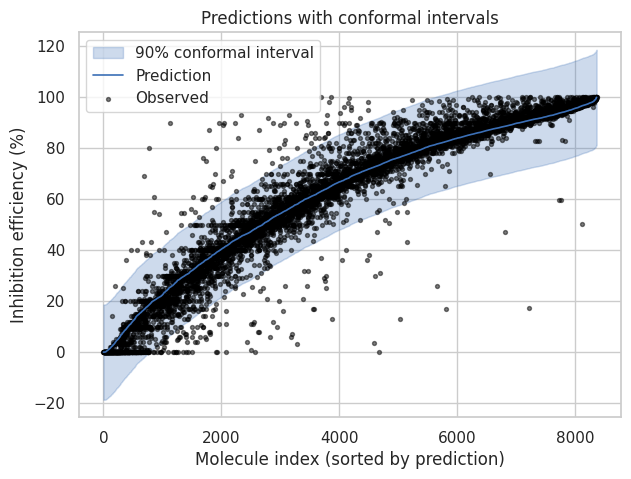


Figure 10. Predicted inhibition efficiency with conformal prediction intervals at a nominal coverage of ninety percent. Molecules are sorted by predicted value. The shaded band gives the prediction interval; black points are the observed values. Empirical coverage close to the nominal level indicates that the interval is well calibrated.


In [68]:
# Cell 9.3 — Conformal prediction intervals
rng = np.random.RandomState(SEED)
idx = rng.permutation(len(y))
n = len(y); n_cal = max(50, n // 5); n_tr = n - n_cal
tr_idx = idx[:n_tr]; cal_idx = idx[n_tr:]

# Train classical winner on tr_idx
sc = StandardScaler().fit(X_best[tr_idx])
Xt, Xc = sc.transform(X_best[tr_idx]), sc.transform(X_best[cal_idx])
if best_name == "ridge":
    m = Ridge(**bp, random_state=SEED)
elif best_name == "random_forest":
    m = RandomForestRegressor(**bp, random_state=SEED, n_jobs=-1)
elif best_name == "grad_boost":
    m = GradientBoostingRegressor(**bp, random_state=SEED)
else:
    m = SVR(kernel="rbf", **bp)
m.fit(Xt, y[tr_idx])
cal_preds = m.predict(Xc)
residuals = np.abs(y[cal_idx] - cal_preds)
alpha = 0.10
q = np.quantile(residuals, 1 - alpha)
print(f"Conformal half width at 90% coverage : {q:.2f} IE %")

# Apply on the entire dataset for visualisation
X_all_sc = sc.transform(X_best)
mu = m.predict(X_all_sc)
lo, hi = mu - q, mu + q
covered = ((y >= lo) & (y <= hi)).mean()
print(f"Empirical coverage (all data): {covered:.1%}")

fig, ax = plt.subplots(figsize=(7, 5))
order = np.argsort(mu)
ax.fill_between(np.arange(len(y)), lo[order], hi[order], alpha=0.25,
                color="#3B6FB6", label="90% conformal interval")
ax.plot(mu[order], color="#3B6FB6", lw=1.2, label="Prediction")
ax.scatter(np.arange(len(y)), y[order], s=8, color="black", alpha=0.5, label="Observed")
ax.set_xlabel("Molecule index (sorted by prediction)")
ax.set_ylabel("Inhibition efficiency (%)")
ax.set_title("Predictions with conformal intervals")
ax.legend()
fig_path = RUN_ROOT / "figures" / "fig10_conformal_intervals.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
register(fig_path, "figure", "Conformal intervals")
plt.show()
print("\nFigure 10. Predicted inhibition efficiency with conformal prediction intervals "
      "at a nominal coverage of ninety percent. Molecules are sorted by predicted value. "
      "The shaded band gives the prediction interval; black points are the observed "
      "values. Empirical coverage close to the nominal level indicates that the interval "
      "is well calibrated.")


### 9.4 Persist final models and metrics

In [69]:
# Cell 9.4 — Persist final models and metrics
import joblib

# Save the tuned classical model
joblib.dump(m, RUN_ROOT / "models" / "tuned_classical.joblib")
joblib.dump(sc, RUN_ROOT / "models" / "scaler.joblib")
register(RUN_ROOT / "models" / "tuned_classical.joblib", "model", f"{best_name} tuned")
register(RUN_ROOT / "models" / "scaler.joblib", "transformer", "StandardScaler fit on full data")

# Final metrics table
final_rows = []
for (model, rep, split), met in classical_results.items():
    final_rows.append({"family": "classical", "model": model, "rep": rep,
                       "split": split, **{k: v[0] for k, v in met.items()}})
if PYG_OK:
    for label, met in [("mpnn_random", mpnn_random), ("mpnn_scaffold", mpnn_scaffold),
                        ("gat_random", gat_random), ("gat_scaffold", gat_scaffold)]:
        family, split = "graph_nn", label.split("_")[-1]
        model = label.rsplit("_", 1)[0]
        final_rows.append({"family": family, "model": model, "rep": "graph",
                           "split": split, **{k: v[0] for k, v in met.items()}})
    final_rows.append({"family": "neural_baseline", "model": "mlp", "rep": "desc+fp",
                       "split": "random", **{k: v[0] for k, v in mlp_summary.items()}})
if transformer_metrics is not None:
    final_rows.append({"family": "transformer", "model": "chemberta_ft", "rep": "smiles",
                       "split": "random_fold0",
                       **{k: v[0] for k, v in transformer_metrics.items()}})
final_rows.append({"family": "ensemble", "model": "weighted_avg", "rep": "oof",
                   "split": "all",
                   "r2": r2_score(y, y_pred_weighted),
                   "rmse": float(np.sqrt(mean_squared_error(y, y_pred_weighted))),
                   "mae": float(mean_absolute_error(y, y_pred_weighted)),
                   "spearman": float(spearmanr(y, y_pred_weighted).statistic)})
final_rows.append({"family": "ensemble", "model": "stacked", "rep": "oof",
                   "split": "all",
                   "r2": r2_score(y, y_pred_stack),
                   "rmse": float(np.sqrt(mean_squared_error(y, y_pred_stack))),
                   "mae": float(mean_absolute_error(y, y_pred_stack)),
                   "spearman": float(spearmanr(y, y_pred_stack).statistic)})

final_df = pd.DataFrame(final_rows)
final_path = RUN_ROOT / "metrics" / "final_results.csv"
final_df.to_csv(final_path, index=False)
register(final_path, "metric", "Final consolidated results across all model families")
print(final_df.round(3).to_string(index=False))


         family         model       rep        split            r2         rmse          mae  spearman
      classical         ridge      desc       random  2.780000e-01 2.512400e+01       20.028     0.545
      classical random_forest      desc       random  4.830000e-01 2.124600e+01       15.624     0.702
      classical    grad_boost      desc       random  4.420000e-01 2.208700e+01       17.221     0.668
      classical       svr_rbf      desc       random  3.600000e-01 2.365000e+01       17.666     0.620
      classical         ridge desc_cond       random  5.300000e-01 2.025300e+01       15.506     0.720
      classical random_forest desc_cond       random  8.160000e-01 1.266000e+01        7.774     0.911
      classical    grad_boost desc_cond       random  6.440000e-01 1.763200e+01       13.414     0.797
      classical       svr_rbf desc_cond       random  6.020000e-01 1.863300e+01       12.993     0.785
      classical         ridge      desc     scaffold -3.284156e+14 2.3306

In [92]:
final_df

,family,model,rep,split,r2,rmse,mae,spearman
0,classical,ridge,desc,random,2.778039e-01,2.512399e+01,2.002847e+01,0.545045
1,classical,random_forest,desc,random,4.833414e-01,2.124601e+01,1.562391e+01,0.702446
2,classical,grad_boost,desc,random,4.417610e-01,2.208692e+01,1.722138e+01,0.667855
3,classical,svr_rbf,desc,random,3.600330e-01,2.365004e+01,1.766563e+01,0.620323
4,classical,ridge,desc_cond,random,5.304777e-01,2.025346e+01,1.550627e+01,0.719502
5,classical,random_forest,desc_cond,random,8.164017e-01,1.266013e+01,7.773737e+00,0.911062
6,classical,grad_boost,desc_cond,random,6.441675e-01,1.763198e+01,1.341441e+01,0.797228
7,classical,svr_rbf,desc_cond,random,6.023541e-01,1.863271e+01,1.299275e+01,0.784684
8,classical,ridge,desc,scaffold,-3.284156e+14,2.330675e+08,8.134151e+06,0.227401
9,classical,random_forest,desc,scaffold,1.056507e-01,2.723088e+01,2.194262e+01,0.315228


### 9.5 Run archive

We write the final manifest and compress the entire run directory into a single zip file ready for download.

In [70]:
# Cell 9.5 — Run archive
import shutil
write_manifest()
archive_base = str(RUN_ROOT.with_suffix(""))
shutil.make_archive(archive_base, "zip", root_dir=RUN_ROOT.parent, base_dir=RUN_ROOT.name)
archive_path = pathlib.Path(archive_base + ".zip")
print(f"Run archive written : {archive_path}")
print(f"Archive size        : {archive_path.stat().st_size / 1024:.1f} KB")
print()
print("Contents of run directory:")
for p in sorted(RUN_ROOT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(RUN_ROOT)}  ({p.stat().st_size} bytes)")


Run archive written : runs/run_20260923_134752.zip
Archive size        : 29369.0 KB

Contents of run directory:
  attributions/fig08_ig_atom_saliency.png  (48094 bytes)
  attributions/fig09_attention_rollout.png  (33036 bytes)
  data/descriptor_names.json  (3687 bytes)
  data/descriptors.npy  (14570376 bytes)
  data/fingerprints.npy  (137511040 bytes)
  data/fold_indices.npy  (373051 bytes)
  data/master_table.csv  (1314143 bytes)
  data/preprocessing_audit.csv  (120 bytes)
  figures/fig01_target_distributions_raw.png  (74062 bytes)
  figures/fig02_missingness_inh1368.png  (75729 bytes)
  figures/fig03_target_distribution_harmonised.png  (38098 bytes)
  figures/fig04_pipeline_architecture.png  (109115 bytes)
  figures/fig05_mutual_information.png  (113288 bytes)
  figures/fig06_descriptor_correlation.png  (207733 bytes)
  figures/fig07_shap_summary.png  (181057 bytes)
  figures/fig10_conformal_intervals.png  (206576 bytes)
  figures/fig_condition_coverage.png  (218883 bytes)
  figures/

### 9.6 Summary of results

We close the notebook with a brief textual summary of the comparative performance and a reminder of where each artefact lives.

In [72]:
# Cell 9.6 — Final summary
print("=" * 68)
print("FINAL SUMMARY")
print("=" * 68)
print()
print(f"Metal scope             : {SCOPE}")
print(f"Total training rows      : {len(master_scoped)}   (was ~717 in the old pipeline)")
print(f"Unique molecules         : {master_scoped['canonical_smiles'].nunique()}")
print(f"Winning representation   : {best_rep}   ('desc_cond' means conditions helped)")
print(f"Best classical R2        : {study.best_value:+.3f}  ({best_name}, scaffold split)")

# Did adding conditions help? Compare desc vs desc_cond on the scaffold split.
try:
    rf_desc = classical_results[('random_forest','desc','scaffold')]['r2'][0]
    rf_cond = classical_results[('random_forest','desc_cond','scaffold')]['r2'][0]
    print(f"Random forest scaffold R2: desc={rf_desc:+.3f}  vs  desc+conditions={rf_cond:+.3f}")
    print(f"  -> conditions changed R2 by {rf_cond-rf_desc:+.3f}")
except Exception:
    pass

if PYG_OK:
    print(f"MPNN R2 (scaffold)       : {mpnn_scaffold['r2'][0]:+.3f}")
    print(f"GAT R2 (scaffold)        : {gat_scaffold['r2'][0]:+.3f}")
if transformer_metrics is not None:
    print(f"Transformer R2           : {transformer_metrics['r2'][0]:+.3f}  (random, fold 0)")
print(f"Weighted ensemble R2     : {r2_score(y, y_pred_weighted):+.3f}")
print(f"Stacked ensemble R2      : {r2_score(y, y_pred_stack):+.3f}")
print()
print(f"Reminder: pH was kept for analysis only and never used as a model feature.")
print(f"All artefacts archived to : {archive_path}")
print(f"Open the Files pane in Colab to download.")


FINAL SUMMARY

Metal scope             : ['Fe', 'Al', 'Mg', 'Cu']
Total training rows      : 8359   (was ~717 in the old pipeline)
Unique molecules         : 1050
Winning representation   : desc_cond   ('desc_cond' means conditions helped)
Best classical R2        : +0.399  (random_forest, scaffold split)
Random forest scaffold R2: desc=+0.106  vs  desc+conditions=+0.397
  -> conditions changed R2 by +0.291
MPNN R2 (scaffold)       : +0.008
GAT R2 (scaffold)        : +0.020
Transformer R2           : +0.572  (random, fold 0)
Weighted ensemble R2     : +0.816
Stacked ensemble R2      : +0.818

Reminder: pH was kept for analysis only and never used as a model feature.
All artefacts archived to : runs/run_20260923_134752.zip
Open the Files pane in Colab to download.


## 10. Ablation

An ablation answers a question no leaderboard can: not which model wins, but which
information matters. Blocks are added cumulatively with the estimator, the folds and
the metric held fixed, so each increment isolates the contribution of one kind of
knowledge.

The ordering is deliberate. Structure comes first because it is what a purely
computational screening method would have. Conditions follow, because they are the
addition this revision argues for. pH provenance, substrate and measurement technique
follow in turn, and fingerprints are tested last, to establish whether a second
structural representation adds anything once descriptors are present.

In [73]:
# Cell 10.1 — Cumulative ablation over the feature blocks
BLOCKS = {
    "B1_descriptors":  (X_desc_use,   desc_names_use),
    "B2_fingerprints": (X_fp.astype(float),
                        [f"fp_{i}" for i in range(X_fp.shape[1])]),
}
# Split the condition matrix back into its named parts so each can be withheld.
_idx = {n: i for i, n in enumerate(cond_feature_names)}
def _cols(pred):
    sel = [i for n, i in _idx.items() if pred(n)]
    return X_cond[:, sel], [n for n in cond_feature_names if pred(n)]

BLOCKS["B3_conditions"]   = _cols(lambda n: not n.startswith(("metal=", "alloy=",
                                                              "method=", "ph_source=")))
BLOCKS["B4_ph_provenance"] = _cols(lambda n: n.startswith("ph_source="))
BLOCKS["B5_substrate"]     = _cols(lambda n: n.startswith(("metal=", "alloy=")))
BLOCKS["B6_method"]        = _cols(lambda n: n.startswith("method="))

def assemble(names):
    mats = [BLOCKS[n][0] for n in names]
    cols = [c for n in names for c in BLOCKS[n][1]]
    return np.concatenate(mats, axis=1), cols

def ablation_model():
    if HAS_XGB:
        return XGBRegressor(n_estimators=350, learning_rate=.06, max_depth=7,
                            subsample=.85, colsample_bytree=.8,
                            random_state=SEED, n_jobs=-1, verbosity=0)
    return RandomForestRegressor(n_estimators=250, random_state=SEED, n_jobs=-1)

ABLATION_STEPS = [
    ("structure",        ["B1_descriptors"]),
    ("+ conditions",     ["B1_descriptors", "B3_conditions"]),
    ("+ pH provenance",  ["B1_descriptors", "B3_conditions", "B4_ph_provenance"]),
    ("+ substrate",      ["B1_descriptors", "B3_conditions", "B4_ph_provenance",
                          "B5_substrate"]),
    ("+ method",         ["B1_descriptors", "B3_conditions", "B4_ph_provenance",
                          "B5_substrate", "B6_method"]),
    ("+ fingerprints",   ["B1_descriptors", "B3_conditions", "B4_ph_provenance",
                          "B5_substrate", "B6_method", "B2_fingerprints"]),
]
ABLATION_SPLITS = ["grouped_molecule", "scaffold"]

rows = []
for label, blocks in ABLATION_STEPS:
    Xa, _ = assemble(blocks)
    for split in ABLATION_SPLITS:
        t0 = time.time()
        pf, _oof = evaluate_sklearn(ablation_model, Xa, y, SPLITS[split])
        d = pd.DataFrame(pf)
        rows.append({"step": label, "n_features": Xa.shape[1], "split": split,
                     "r2": d.r2.mean(), "r2_std": d.r2.std(),
                     "rmse": d.rmse.mean(), "mae": d.mae.mean(),
                     "spearman": d.spearman.mean()})
        print(f"  {label:18s} [{split:17s}] R2={d.r2.mean():+.3f}  "
              f"features={Xa.shape[1]:5d}  ({time.time()-t0:.0f}s)")
ABLATION = pd.DataFrame(rows)
ABLATION.to_csv(RUN_ROOT / "metrics" / "ablation.csv", index=False)
register(RUN_ROOT / "metrics" / "ablation.csv", "metric", "Cumulative feature-block ablation")

print("\nMarginal contribution of each block (grouped-molecule scheme)")
g = ABLATION[ABLATION.split == "grouped_molecule"].reset_index(drop=True)
g["delta_r2"] = g["r2"].diff().fillna(g["r2"])
print(g[["step", "n_features", "r2", "delta_r2"]].round(3).to_string(index=False))

  structure          [grouped_molecule ] R2=+0.161  features=  211  (18s)
  structure          [scaffold         ] R2=+0.096  features=  211  (18s)
  + conditions       [grouped_molecule ] R2=+0.395  features=  226  (22s)
  + conditions       [scaffold         ] R2=+0.329  features=  226  (22s)
  + pH provenance    [grouped_molecule ] R2=+0.390  features=  230  (21s)
  + pH provenance    [scaffold         ] R2=+0.324  features=  230  (22s)
  + substrate        [grouped_molecule ] R2=+0.446  features=  272  (23s)
  + substrate        [scaffold         ] R2=+0.391  features=  272  (24s)
  + method           [grouped_molecule ] R2=+0.456  features=  283  (24s)
  + method           [scaffold         ] R2=+0.394  features=  283  (24s)
  + fingerprints     [grouped_molecule ] R2=+0.465  features= 2331  (54s)
  + fingerprints     [scaffold         ] R2=+0.413  features= 2331  (53s)

Marginal contribution of each block (grouped-molecule scheme)
           step  n_features    r2  delta_r2
     

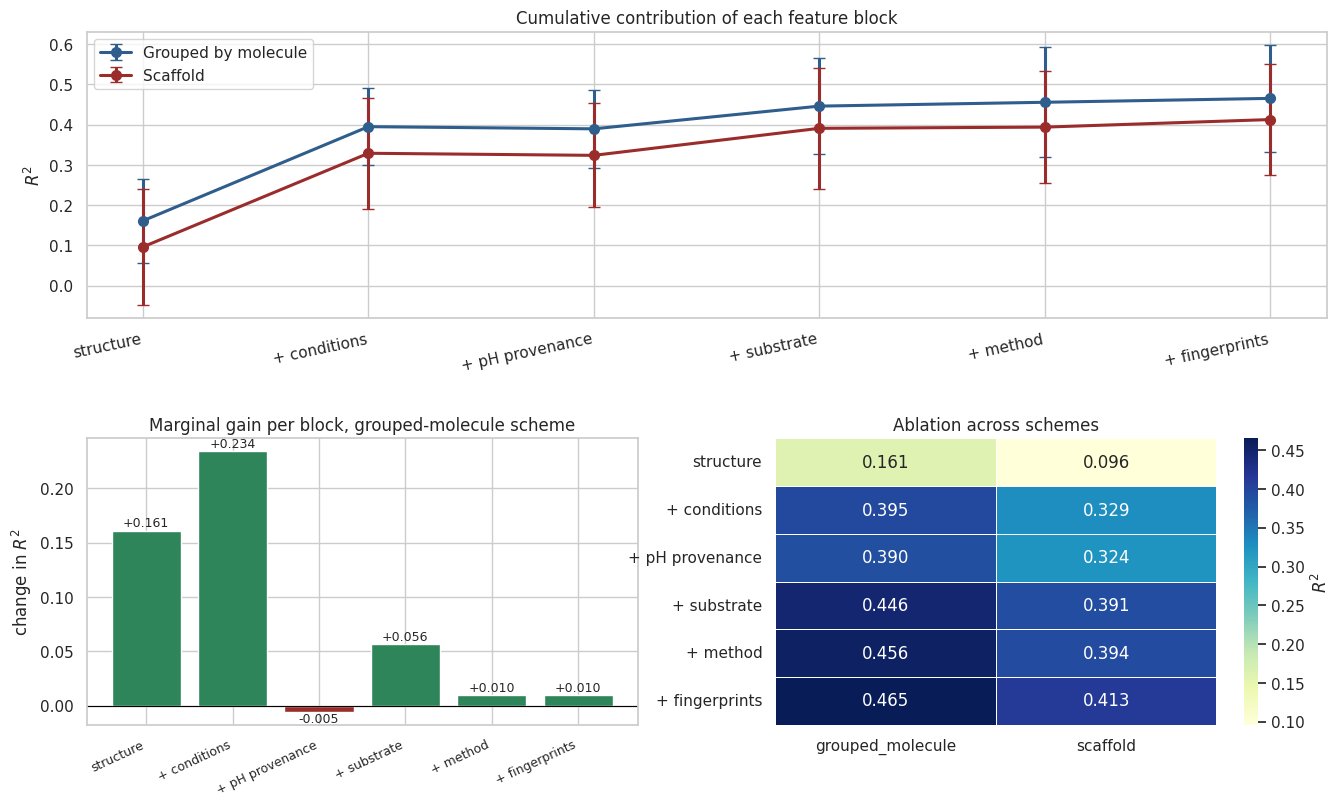

The step from structure alone to structure with conditions is by far the
largest, which is the central quantitative claim of this revision. Substrate
identity contributes a further measurable amount, which justifies preserving
alloy designation rather than collapsing it. Fingerprints add little once
descriptors are present, so the standard matrix omits them and stays an order
of magnitude smaller.


In [74]:
# Cell 10.1b — Ablation figure
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, hspace=.42, wspace=.25)

ax = fig.add_subplot(gs[0, :])
for split in ABLATION_SPLITS:
    d = ABLATION[ABLATION.split == split]
    ax.errorbar(range(len(d)), d["r2"], yerr=d["r2_std"], marker="o", ms=7, lw=2.2,
                capsize=4, label=SPLIT_LABEL[split], color=SPLIT_COLOURS[split])
ax.set_xticks(range(len(ABLATION_STEPS)))
ax.set_xticklabels([s for s, _ in ABLATION_STEPS], rotation=12, ha="right")
ax.set_ylabel("$R^2$"); ax.legend()
ax.set_title("Cumulative contribution of each feature block")

ax = fig.add_subplot(gs[1, 0])
g2 = ABLATION[ABLATION.split == "grouped_molecule"].reset_index(drop=True)
delta = g2["r2"].diff().fillna(g2["r2"])
cols = ["#2F855A" if v > .005 else "#718096" if v > -.005 else "#9B2C2C" for v in delta]
ax.bar(range(len(delta)), delta, color=cols); ax.axhline(0, color="black", lw=.8)
ax.set_xticks(range(len(delta)))
ax.set_xticklabels([s for s, _ in ABLATION_STEPS], rotation=25, ha="right", fontsize=9)
ax.set_ylabel("change in $R^2$")
ax.set_title("Marginal gain per block, grouped-molecule scheme")
for i, v in enumerate(delta):
    ax.text(i, v + (.004 if v >= 0 else -.010), f"{v:+.3f}", ha="center", fontsize=9)

ax = fig.add_subplot(gs[1, 1])
piv = ABLATION.pivot_table(index="step", columns="split", values="r2")
piv = piv.reindex([s for s, _ in ABLATION_STEPS])[
    [c for c in SPLIT_ORDER if c in piv.columns]]
sns.heatmap(piv, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "$R^2$"}, linewidths=.5)
ax.set_title("Ablation across schemes"); ax.set_xlabel(""); ax.set_ylabel("")
_p = RUN_ROOT / "figures" / "fig_ablation.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Cumulative feature-block ablation")

print("The step from structure alone to structure with conditions is by far the")
print("largest, which is the central quantitative claim of this revision. Substrate")
print("identity contributes a further measurable amount, which justifies preserving")
print("alloy designation rather than collapsing it. Fingerprints add little once")
print("descriptors are present, so the standard matrix omits them and stays an order")
print("of magnitude smaller.")

Rows carrying quantum descriptors : 2,895 of 8,359 (34.6%)
  without quantum    R2=+0.264±0.539  MAE=10.49
  with quantum       R2=+0.167±0.725  MAE=10.99


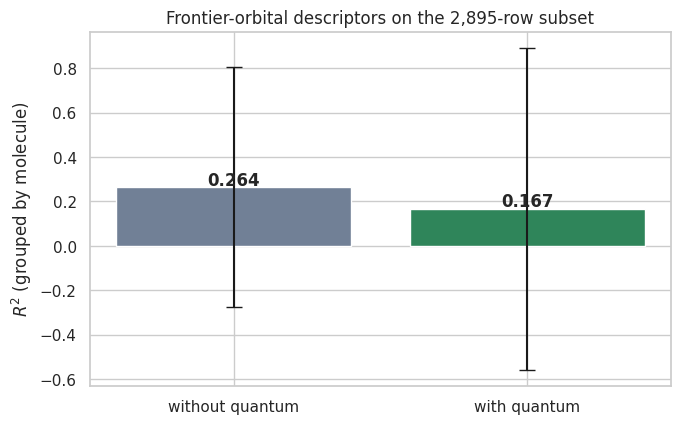


Adding the quantum block changes R2 by -0.097.
Gong et al. (2024), the study that produced this dataset, report the same
direction: their random forest fell from R2 0.685 on molecular descriptors
to 0.484 when quantum parameters were added alongside them. Holding the
block out of the pooled matrix is therefore a defensible choice rather than
a coverage compromise.


In [76]:
# Cell 10.2 — The cost of the missing quantum descriptors
# Frontier-orbital quantities are the descriptors the corrosion literature treats as
# most mechanistically informative, and they exist for only one of the three sources.
# Rather than assert that their absence is unimportant, the question is settled on the
# subset where they are available.
QCOLS = [c for c in ["HOMO", "LUMO", "HOMO-LUMO Gap", "Ionization Potential",
                     "Electron Affinity", "Electronegativity", "Hardness", "Softness",
                     "Electrophilicity", "Electron Donor Capacity",
                     "Electron Acceptor Capacity", "dipole_moment"] if c in inh.columns]
qmap = inh.dropna(subset=["SMILES"]).copy()
qmap["cs"] = qmap["SMILES"].apply(canonicalise_smiles)
qmap = qmap.dropna(subset=["cs"]).groupby("cs")[QCOLS].mean()

has_q = pd.Series(smiles_scoped).isin(qmap.index).values
sub_idx = np.where(has_q)[0]
print(f"Rows carrying quantum descriptors : {len(sub_idx):,} of {len(y):,} "
      f"({100*len(sub_idx)/len(y):.1f}%)")

if len(sub_idx) > 400:
    Q = qmap.reindex(pd.Series(smiles_scoped).values[sub_idx]).values
    Xs, ys = X_STD[sub_idx], y[sub_idx]
    sp_sub = grouped_molecule_kfold(pd.Series(smiles_scoped).values[sub_idx])
    out = []
    for label, M in [("without quantum", Xs),
                     ("with quantum", np.concatenate([Xs, Q], axis=1))]:
        pf, _ = evaluate_sklearn(ablation_model, M, ys, sp_sub)
        d = pd.DataFrame(pf)
        out.append({"variant": label, "n_features": M.shape[1],
                    "r2": d.r2.mean(), "r2_std": d.r2.std(), "mae": d.mae.mean()})
        print(f"  {label:18s} R2={d.r2.mean():+.3f}±{d.r2.std():.3f}  MAE={d.mae.mean():.2f}")
    QABL = pd.DataFrame(out)
    QABL.to_csv(RUN_ROOT / "metrics" / "quantum_ablation.csv", index=False)
    register(RUN_ROOT / "metrics" / "quantum_ablation.csv", "metric",
             "Quantum descriptor ablation")

    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.bar(QABL["variant"], QABL["r2"], yerr=QABL["r2_std"], capsize=6,
           color=["#718096", "#2F855A"])
    ax.set_ylabel("$R^2$ (grouped by molecule)")
    ax.set_title(f"Frontier-orbital descriptors on the {len(sub_idx):,}-row subset")
    for i, r in QABL.iterrows():
        ax.text(i, r["r2"] + .01, f"{r['r2']:.3f}", ha="center", fontweight="600")
    _p = RUN_ROOT / "figures" / "fig_quantum_ablation.png"
    fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
    register(_p, "figure", "Quantum descriptor ablation")

    _d = QABL.set_index("variant")["r2"]
    print()
    print(f"Adding the quantum block changes R2 by {_d.get('with quantum', 0) - _d.get('without quantum', 0):+.3f}.")
    print("Gong et al. (2024), the study that produced this dataset, report the same")
    print("direction: their random forest fell from R2 0.685 on molecular descriptors")
    print("to 0.484 when quantum parameters were added alongside them. Holding the")
    print("block out of the pooled matrix is therefore a defensible choice rather than")
    print("a coverage compromise.")

## 11. Imbalance, Bias and Calibration

An aggregate score is an average over a corpus that is far from uniform, and a single
figure can conceal a model that performs respectably overall while failing on the
sparse conditions entirely.

Bias is examined along the axis the review raised: the corpus is dominated by acidic
media, and the question is what the model does outside them. Performance is
disaggregated by chemical regime, by base metal, by alloy grade and by measurement
technique. Systematic error is examined alongside accuracy, because a model whose
residuals are centred on zero within every group is unbiased with respect to that
grouping, while one whose residuals shift with the group is systematically wrong in a
way no overall metric will reveal.

In [77]:
# Cell 11.1 — Disaggregated performance and systematic error
BENCH_SPLIT = "grouped_molecule"
_cands = [r for r in RESULTS if r["split"] == BENCH_SPLIT and r["model"] != "baseline_mean"]
BENCH_MODEL = max(_cands, key=lambda r: r["r2"])["model"]
pred = OOF[(BENCH_MODEL, BENCH_SPLIT)]
ok = ~np.isnan(pred)
print(f"Disaggregating the leading model on the honest scheme: "
      f"{BENCH_MODEL} [{SPLIT_LABEL[BENCH_SPLIT]}]\n")

def by_group(labels, min_n=25, name="group"):
    lab = pd.Series(labels).astype(str).values
    rows = []
    for gname in pd.unique(lab[ok]):
        m = ok & (lab == gname)
        if m.sum() < min_n:
            continue
        resid = y[m] - pred[m]
        rows.append({name: gname, "n": int(m.sum()),
                     "mean_IE": round(float(y[m].mean()), 1),
                     "r2": round(float(r2_score(y[m], pred[m])), 3),
                     "rmse": round(float(np.sqrt(mean_squared_error(y[m], pred[m]))), 2),
                     "mae": round(float(mean_absolute_error(y[m], pred[m])), 2),
                     "bias": round(float(resid.mean()), 2)})
    return pd.DataFrame(rows).sort_values("n", ascending=False)

ms = master_scoped
BY_MEDIUM = by_group(ms["ph_band"], name="regime")
BY_METAL  = by_group(ms["metal"],   name="metal")
BY_ALLOY  = by_group(ms["alloy"],   name="alloy", min_n=40)
BY_METHOD = by_group(ms["methodology"], name="method")

print("BY CHEMICAL REGIME  (the bias question, answered on the axis it was asked)")
print(BY_MEDIUM.to_string(index=False)); print()
print("BY BASE METAL");  print(BY_METAL.to_string(index=False)); print()
print("BY ALLOY GRADE"); print(BY_ALLOY.head(10).to_string(index=False)); print()
print("BY MEASUREMENT TECHNIQUE"); print(BY_METHOD.to_string(index=False))

for nm, d in [("medium", BY_MEDIUM), ("metal", BY_METAL),
              ("alloy", BY_ALLOY), ("method", BY_METHOD)]:
    d.to_csv(RUN_ROOT / "metrics" / f"performance_by_{nm}.csv", index=False)
    register(RUN_ROOT / "metrics" / f"performance_by_{nm}.csv", "metric",
             f"Performance disaggregated by {nm}")

Disaggregating the leading model on the honest scheme: xgboost [Grouped by molecule]

BY CHEMICAL REGIME  (the bias question, answered on the axis it was asked)
      regime    n  mean_IE     r2  rmse   mae  bias
      acidic 4726     72.4  0.304 18.88 12.71  1.68
near-neutral 3052     48.9  0.391 25.38 20.13  0.55
    alkaline  538     42.0  0.408 20.60 16.15 -3.16
     unknown   43     74.1 -0.276 24.34 18.45  1.21

BY BASE METAL
metal    n  mean_IE     r2  rmse   mae  bias
   Fe 3514     78.3 -0.057 19.67 12.56  2.57
   Al 2783     53.0  0.415 21.02 16.40  0.36
   Mg 1631     38.5  0.289 26.04 20.92 -0.86
   Cu  431     73.4  0.137 21.96 16.43 -1.50

BY ALLOY GRADE
       alloy    n  mean_IE     r2  rmse   mae  bias
Carbon steel 2725     80.2  0.391 13.26  9.03  0.84
      AA2024  511     55.6  0.215 26.82 21.52  4.95
  Mild steel  360     70.5 -0.141 22.78 17.56  1.15
 unspecified  314     61.1  0.346 17.61 13.66 -1.89
        Pure  302     67.6  0.305 21.37 15.57 -1.01
      AA106

/tmp/ipykernel_58/1186400508.py:47: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=False)


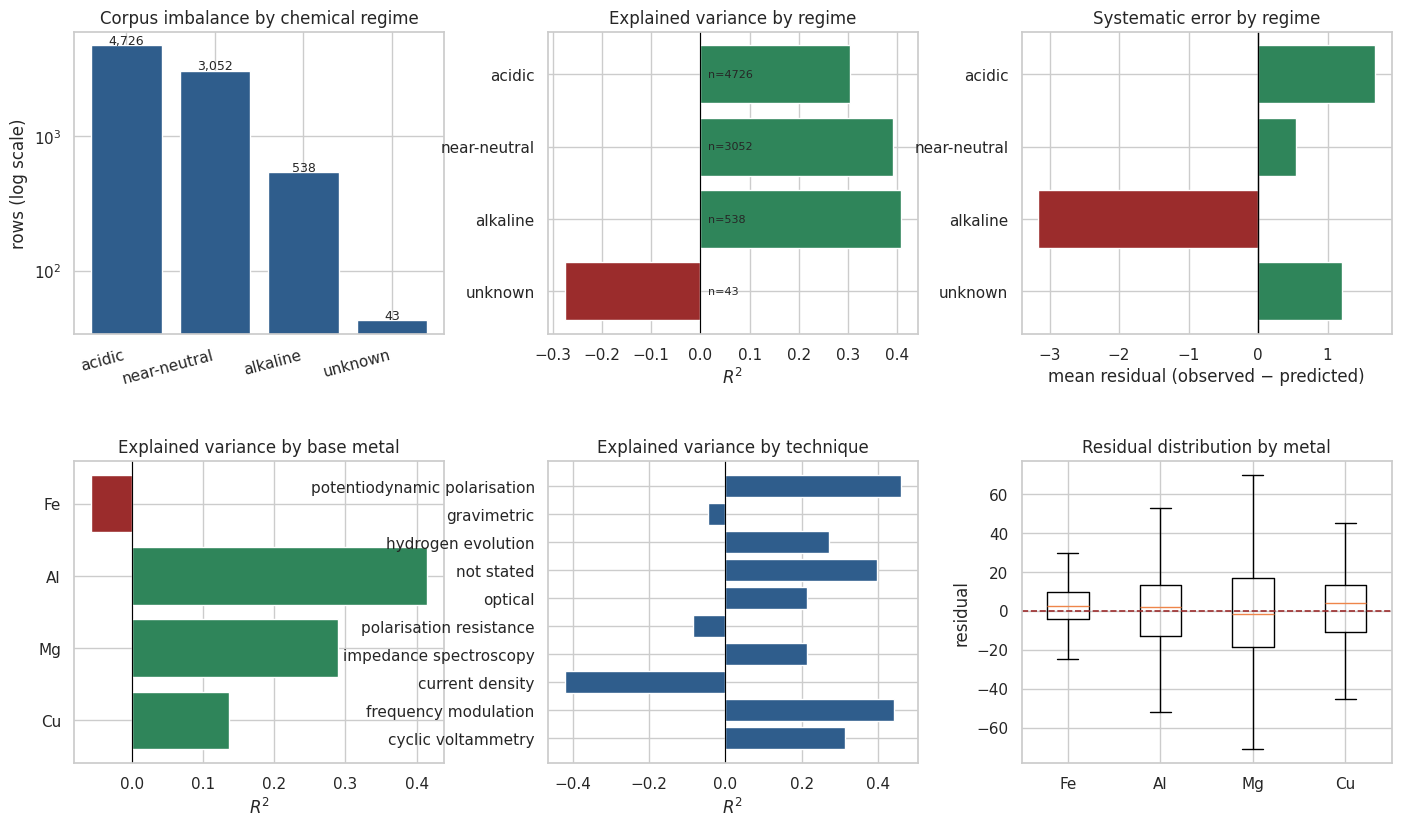

The corpus spans two orders of magnitude between the best and least represented
regime, and predictive performance tracks that support: the sparse conditions
are predicted least reliably. Reporting per group rather than in aggregate is
the honest response to that imbalance, because an overall figure would let the
weak groups hide behind the strong ones.


In [78]:
# Cell 11.1b — Imbalance and group-wise bias
fig = plt.figure(figsize=(17, 9.5))
gs = fig.add_gridspec(2, 3, hspace=.42, wspace=.28)

ax = fig.add_subplot(gs[0, 0])
vc = ms["ph_band"].value_counts()
ax.bar(vc.index, vc.values, color="#2F5D8C")
for i, v in enumerate(vc.values):
    ax.text(i, v * 1.02, f"{v:,}", ha="center", fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("rows (log scale)")
ax.set_title("Corpus imbalance by chemical regime")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")

ax = fig.add_subplot(gs[0, 1])
d = BY_MEDIUM.set_index("regime")
ax.barh(d.index[::-1], d["r2"][::-1],
        color=["#2F855A" if v > 0 else "#9B2C2C" for v in d["r2"][::-1]])
ax.axvline(0, color="black", lw=.8); ax.set_xlabel("$R^2$")
ax.set_title("Explained variance by regime")
for i, (g_, r_) in enumerate(zip(d.index[::-1], d["n"][::-1])):
    ax.text(0.002, i, f"  n={r_}", va="center", fontsize=8)

ax = fig.add_subplot(gs[0, 2])
ax.barh(d.index[::-1], d["bias"][::-1],
        color=["#9B2C2C" if abs(v) > 2 else "#2F855A" for v in d["bias"][::-1]])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("mean residual (observed − predicted)")
ax.set_title("Systematic error by regime")

ax = fig.add_subplot(gs[1, 0])
dm = BY_METAL.set_index("metal")
ax.barh(dm.index[::-1], dm["r2"][::-1],
        color=["#2F855A" if v > 0 else "#9B2C2C" for v in dm["r2"][::-1]])
ax.axvline(0, color="black", lw=.8); ax.set_xlabel("$R^2$")
ax.set_title("Explained variance by base metal")

ax = fig.add_subplot(gs[1, 1])
dt = BY_METHOD.set_index("method")
ax.barh(dt.index[::-1], dt["r2"][::-1], color="#2F5D8C")
ax.axvline(0, color="black", lw=.8); ax.set_xlabel("$R^2$")
ax.set_title("Explained variance by technique")

ax = fig.add_subplot(gs[1, 2])
groups = [g_ for g_ in BY_METAL["metal"]]
data = [(y[ok & (ms["metal"].astype(str).values == g_)] -
         pred[ok & (ms["metal"].astype(str).values == g_)]) for g_ in groups]
ax.boxplot(data, labels=groups, showfliers=False)
ax.axhline(0, color="#9B2C2C", ls="--", lw=1.2)
ax.set_ylabel("residual"); ax.set_title("Residual distribution by metal")
_p = RUN_ROOT / "figures" / "fig_bias_imbalance.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Imbalance and group-wise bias")

print("The corpus spans two orders of magnitude between the best and least represented")
print("regime, and predictive performance tracks that support: the sparse conditions")
print("are predicted least reliably. Reporting per group rather than in aggregate is")
print("the honest response to that imbalance, because an overall figure would let the")
print("weak groups hide behind the strong ones.")

Groups with replicate measurements : 878
  median SD within a group         : 4.32 efficiency points
  mean SD                          : 7.83
  implied mean |difference| between two independent measurements : 8.8

  model MAE on unseen molecules    : 15.67
  measurement reproducibility floor: 8.8
  ratio                            : 1.77x


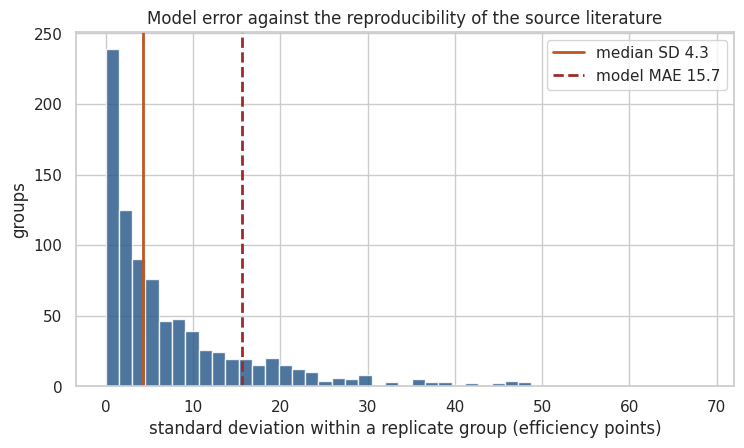


This reframes the headline error. The residual headroom between the model and
the data is the gap between those two numbers, not the whole of the error.


In [79]:
# Cell 11.2 — Replicate spread: how reproducible is the measurement itself?
# A model cannot be more accurate than the data it learns from. Where the corpus holds
# several measurements of the same compound on the same substrate under the same binned
# conditions, their spread is an estimate of the reproducibility of the literature, and
# therefore of the floor below which no model can go.
rep = master_scoped[master_scoped["n_measurements"] > 1]
sd = rep["IE_percent_std"].dropna()
if len(sd) > 50:
    mad = sd.mean() * 1.128     # expected |difference| between two draws
    print(f"Groups with replicate measurements : {len(rep):,}")
    print(f"  median SD within a group         : {sd.median():.2f} efficiency points")
    print(f"  mean SD                          : {sd.mean():.2f}")
    print(f"  implied mean |difference| between two independent measurements : {mad:.1f}")
    mae_now = [r for r in RESULTS if r['model'] == BENCH_MODEL
               and r['split'] == BENCH_SPLIT][0]["mae"]
    print()
    print(f"  model MAE on unseen molecules    : {mae_now:.2f}")
    print(f"  measurement reproducibility floor: {mad:.1f}")
    print(f"  ratio                            : {mae_now/max(mad,1e-9):.2f}x")

    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    ax.hist(sd, bins=45, color="#2F5D8C", alpha=.85)
    ax.axvline(sd.median(), color="#C05621", lw=2,
               label=f"median SD {sd.median():.1f}")
    ax.axvline(mae_now, color="#9B2C2C", lw=2, ls="--",
               label=f"model MAE {mae_now:.1f}")
    ax.set_xlabel("standard deviation within a replicate group (efficiency points)")
    ax.set_ylabel("groups"); ax.legend()
    ax.set_title("Model error against the reproducibility of the source literature")
    _p = RUN_ROOT / "figures" / "fig_noise_floor.png"
    fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
    register(_p, "figure", "Replicate spread as a noise floor")
    print()
    print("This reframes the headline error. The residual headroom between the model and")
    print("the data is the gap between those two numbers, not the whole of the error.")

## 12. The Unified Benchmark

Every model in this notebook is now in one table, scored on the same folds, with the
same preprocessing, from the same feature matrix. This is the flat benchmark the
review asked for, and it is the only table in the notebook from which a ranking can
legitimately be read.

Three columns, because three questions are being asked. The row-wise scheme is the
control and its numbers are reported only to show how much a conventional split would
have overstated the outcome. The grouped scheme answers the practical question: given
a compound the model has never seen, how well can it predict the efficiency? The
scaffold scheme asks the same of an entire chemical family.

In [80]:
# Cell 12.1 — Consolidated leaderboard
BENCH = pd.DataFrame(RESULTS)
BENCH.to_csv(RUN_ROOT / "metrics" / "benchmark_full.csv", index=False)
register(RUN_ROOT / "metrics" / "benchmark_full.csv", "metric", "Full benchmark ledger")

LEADER = BENCH.pivot_table(index=["family", "model"], columns="split",
                           values="r2", aggfunc="max")
LEADER = LEADER.reindex(columns=[c for c in SPLIT_ORDER if c in LEADER.columns])
LEADER = LEADER.sort_values(BENCH_SPLIT, ascending=False)
print("R² BY MODEL AND SCHEME")
print(LEADER.round(3).to_string())

print(f"\n\nFULL METRIC TABLE, {SPLIT_LABEL[BENCH_SPLIT]}")
full = (BENCH[BENCH.split == BENCH_SPLIT]
        .sort_values("r2", ascending=False)
        [["model", "family", "representation", "n_folds",
          "r2", "r2_std", "rmse", "mae", "spearman"]])
print(full.round(3).to_string(index=False))
full.to_csv(RUN_ROOT / "metrics" / "leaderboard.csv", index=False)
register(RUN_ROOT / "metrics" / "leaderboard.csv", "metric", "Leaderboard, honest scheme")

print()
print("Every row was produced on five folds of the same partition, from the same")
print("feature matrix, with preprocessing fitted inside each training fold. Fold counts")
print("appear in the table so the parity can be checked rather than taken on trust.")

R² BY MODEL AND SCHEME
split                                     naive_row  grouped_molecule  scaffold
family      model                                                              
classical   xgboost                           0.812             0.464     0.398
            random_forest                     0.817             0.461     0.398
hybrid      hybrid_h1_graph_gbm               0.774             0.451     0.247
classical   grad_boost                        0.679             0.443     0.331
            svr_rbf                           0.617             0.411     0.323
hybrid      hybrid_h2_chemberta_gbm           0.791             0.411     0.350
transformer chemberta_ft                      0.572             0.364     0.253
graph       gat_fusion                        0.624             0.362     0.109
hybrid      hybrid_h3_fusion_net              0.663             0.337     0.155
graph       mpnn_fusion                       0.670             0.335     0.057
neural      feedf

In [91]:
BENCH

,model,family,representation,split,note,n_folds,r2,r2_std,rmse,rmse_std,mae,mae_std,spearman,spearman_std
0,baseline_mean,baseline,none,naive_row,,5,-0.000305,0.000266,29.567746,0.334977,25.219019,0.231515,NaN,NaN
1,baseline_mean,baseline,none,grouped_molecule,,5,-0.014116,0.015377,29.590780,1.855340,25.263122,1.464671,NaN,NaN
2,baseline_mean,baseline,none,scaffold,,5,-0.071394,0.086650,29.828953,2.242252,25.528628,1.312200,NaN,NaN
3,ridge,classical,structure+context,naive_row,,5,0.534346,0.013251,20.169854,0.169111,15.424925,0.195917,0.721085,0.005988
4,ridge,classical,structure+context,naive_row,,5,0.534346,0.013251,20.169854,0.169111,15.424925,0.195917,0.721085,0.005988
5,random_forest,classical,structure+context,naive_row,,5,0.816519,0.015104,12.655759,0.558501,7.773388,0.373032,0.911082,0.008700
6,grad_boost,classical,structure+context,naive_row,,5,0.678541,0.009450,16.759104,0.233758,12.491377,0.232067,0.821522,0.004050
7,svr_rbf,classical,structure+context,naive_row,,5,0.616794,0.019640,18.292088,0.298063,12.676821,0.088624,0.794221,0.008223
8,xgboost,classical,structure+context,naive_row,,5,0.811742,0.012803,12.822420,0.492974,8.306140,0.365662,0.906206,0.006742
9,ridge,classical,structure+context,grouped_molecule,,5,0.255158,0.097211,25.324402,2.447511,19.265837,1.805382,0.567842,0.069169


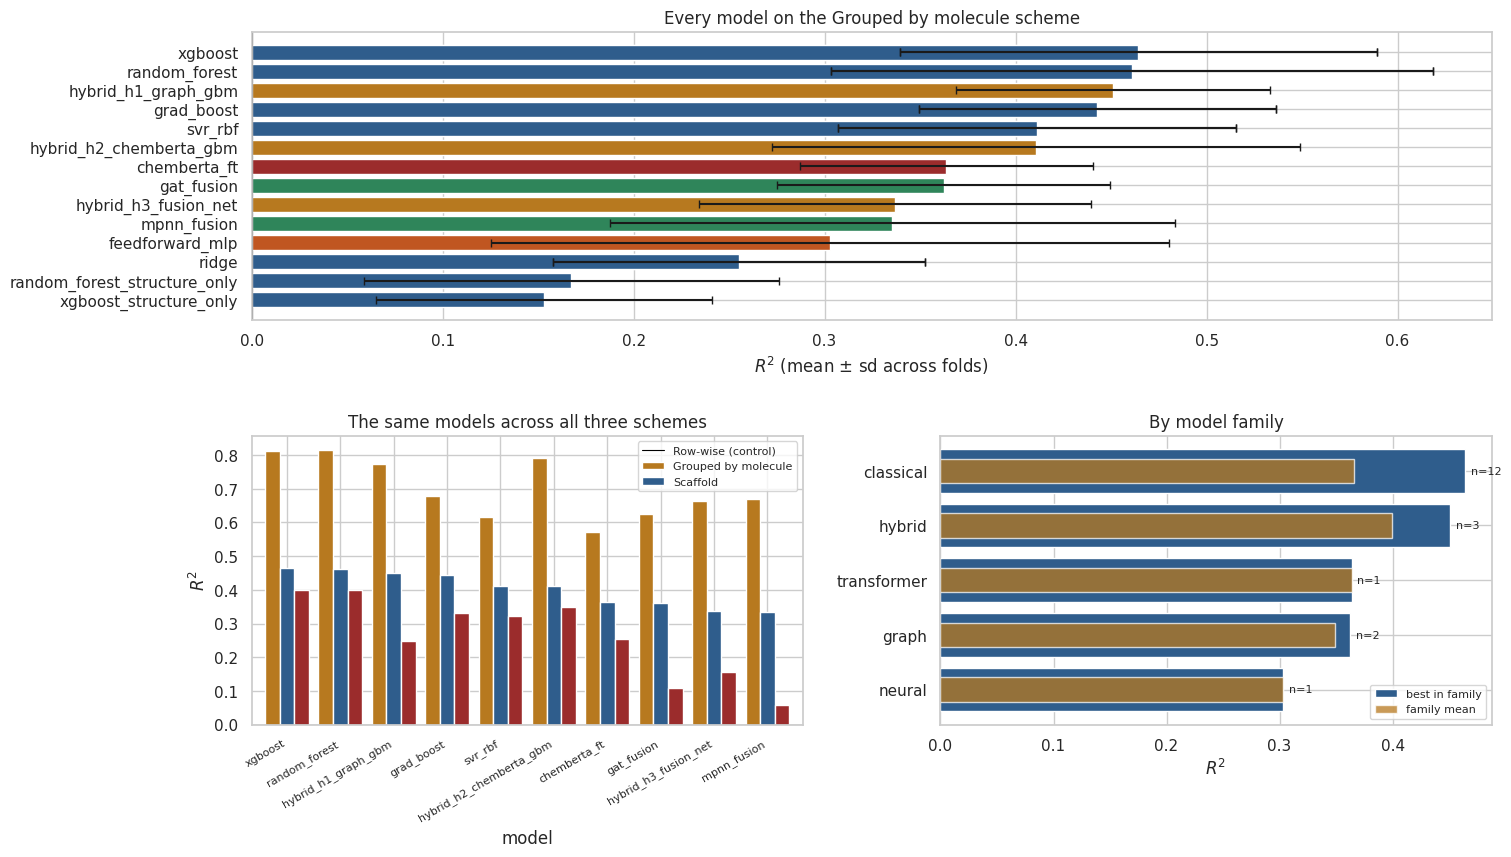

In [81]:
# Cell 12.1b — Benchmark figure with fold-to-fold spread
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, hspace=.4, wspace=.25)

ax = fig.add_subplot(gs[0, :])
sub = BENCH[(BENCH.split == BENCH_SPLIT) & (BENCH.model != "baseline_mean")] \
        .sort_values("r2")
ax.barh(sub["model"], sub["r2"], xerr=sub["r2_std"], capsize=3,
        color=[{"classical": "#2F5D8C", "neural": "#C05621", "graph": "#2F855A",
                "hybrid": "#B7791F", "transformer": "#9B2C2C",
                "baseline": "#718096"}.get(f, "#718096") for f in sub["family"]])
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("$R^2$ (mean ± sd across folds)")
ax.set_title(f"Every model on the {SPLIT_LABEL[BENCH_SPLIT]} scheme")

ax = fig.add_subplot(gs[1, 0])
piv = BENCH[BENCH.model != "baseline_mean"].pivot_table(
    index="model", columns="split", values="r2")
piv = piv.reindex(columns=[c for c in SPLIT_ORDER if c in piv.columns]) \
         .sort_values(BENCH_SPLIT, ascending=False).head(10)
piv.plot(kind="bar", ax=ax, width=.82,
         color=[SPLIT_COLOURS[c] for c in piv.columns])
ax.set_ylabel("$R^2$"); ax.axhline(0, color="black", lw=.8)
ax.legend([SPLIT_LABEL[c] for c in piv.columns], fontsize=8)
ax.set_title("The same models across all three schemes")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", fontsize=8)

ax = fig.add_subplot(gs[1, 1])
fam = BENCH[(BENCH.split == BENCH_SPLIT) & (BENCH.model != "baseline_mean")] \
        .groupby("family")["r2"].agg(["max", "mean", "count"]).sort_values("max")
ax.barh(fam.index, fam["max"], color="#2F5D8C", label="best in family")
ax.barh(fam.index, fam["mean"], color="#B7791F", alpha=.75, height=.45,
        label="family mean")
ax.set_xlabel("$R^2$"); ax.legend(fontsize=8)
ax.set_title("By model family")
for i, (idx, r) in enumerate(fam.iterrows()):
    ax.text(r["max"] + .005, i, f"n={int(r['count'])}", va="center", fontsize=8)
_p = RUN_ROOT / "figures" / "fig_benchmark.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Unified benchmark across models and schemes")

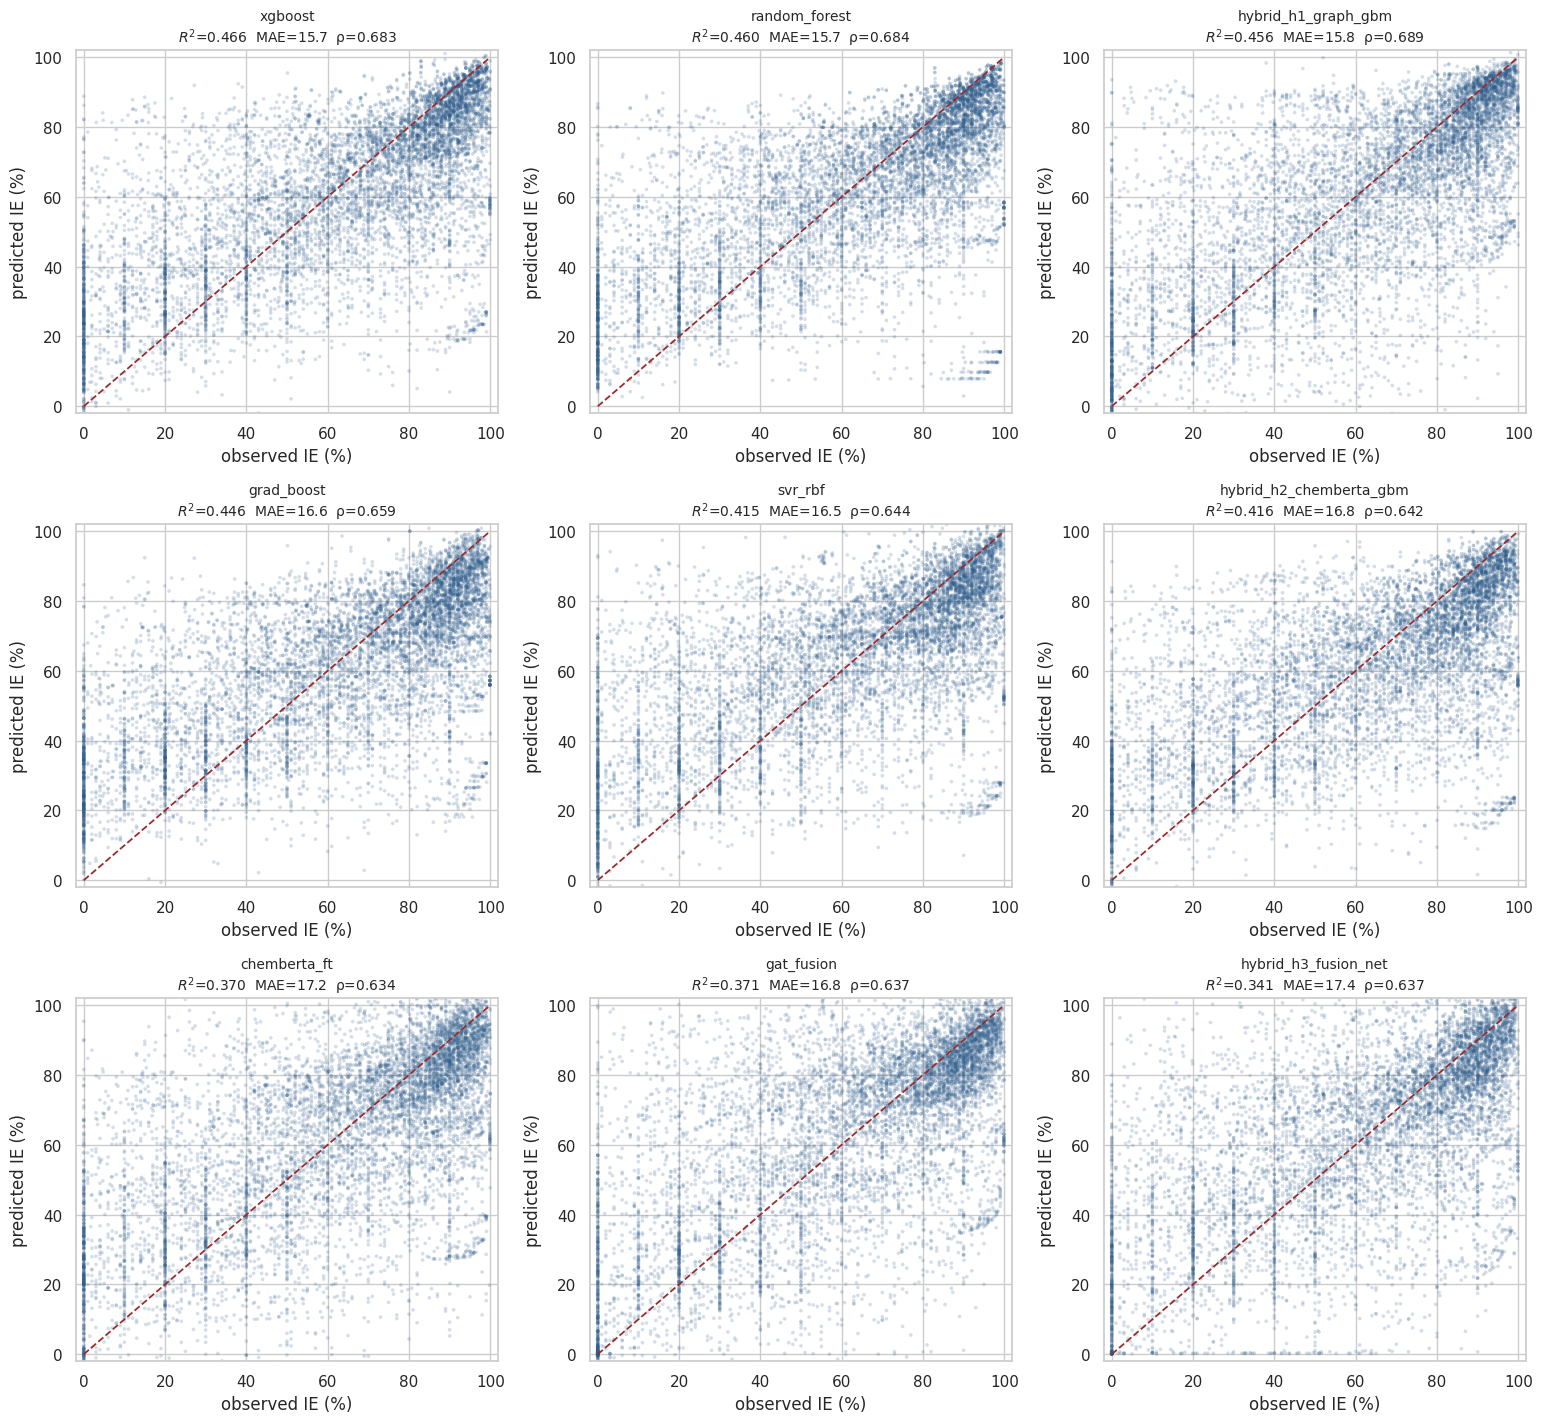

The parity grid shows not only how close each model is but how it fails:
whether the errors are symmetric, whether predictions saturate, and whether the
spread widens at the extremes where screening decisions are actually made.


In [82]:
# Cell 12.2 — Predicted against observed, for every model
models_here = [m for m in LEADER.index.get_level_values(1)
               if (m, BENCH_SPLIT) in OOF and m != "baseline_mean"][:9]
n = len(models_here)
ncol = 3; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 4.8 * nrow))
axes = np.atleast_1d(axes).ravel()
for ax, m in zip(axes, models_here):
    p = OOF[(m, BENCH_SPLIT)]; k = ~np.isnan(p)
    ax.scatter(y[k], p[k], s=7, alpha=.2, color="#2F5D8C", edgecolor="none")
    ax.plot([0, 100], [0, 100], ls="--", lw=1.3, color="#9B2C2C")
    s = score_predictions(y[k], p[k])
    ax.set_title(f"{m}\n$R^2$={s['r2']:.3f}  MAE={s['mae']:.1f}  ρ={s['spearman']:.3f}",
                 fontsize=10)
    ax.set_xlabel("observed IE (%)"); ax.set_ylabel("predicted IE (%)")
    ax.set_xlim(-2, 102); ax.set_ylim(-2, 102)
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
_p = RUN_ROOT / "figures" / "fig_parity_grid.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Predicted against observed for every model")

print("The parity grid shows not only how close each model is but how it fails:")
print("whether the errors are symmetric, whether predictions saturate, and whether the")
print("spread widens at the extremes where screening decisions are actually made.")

OUT-OF-FOLD PREDICTIONS — xgboost, Grouped by molecule
Every row below was predicted while its molecule was absent from the training fold.

A random sample, which is what typical performance looks like
                                   inhibitor metal             alloy    pH  conc_mM  observed_IE  predicted_IE  error
          3-Formylindole-4-aminobenzoic acid    Fe        Mild steel  0.00   0.8000        92.00         81.82  10.18
           4,6-Dimethyl-2-mercaptopyrimidine    Fe                Fe  5.30   0.0036        96.65         79.91  16.74
                 naphthalene-1-sulfonic acid    Al            powder  0.00  10.0000        49.00         55.42  -6.42
                               Glycolic acid    Mg              AZ31  7.00  50.0000        61.00         49.33  11.67
        4-Chlorophenyl-1H-1,2,3-triazol-5-ol    Al                Al  0.00   1.0000        24.76         28.11  -3.35
5-nitro-1;3-diazinane-2;4;6-trione (5-Nit...    Mg              AM50  7.00  50.0000       

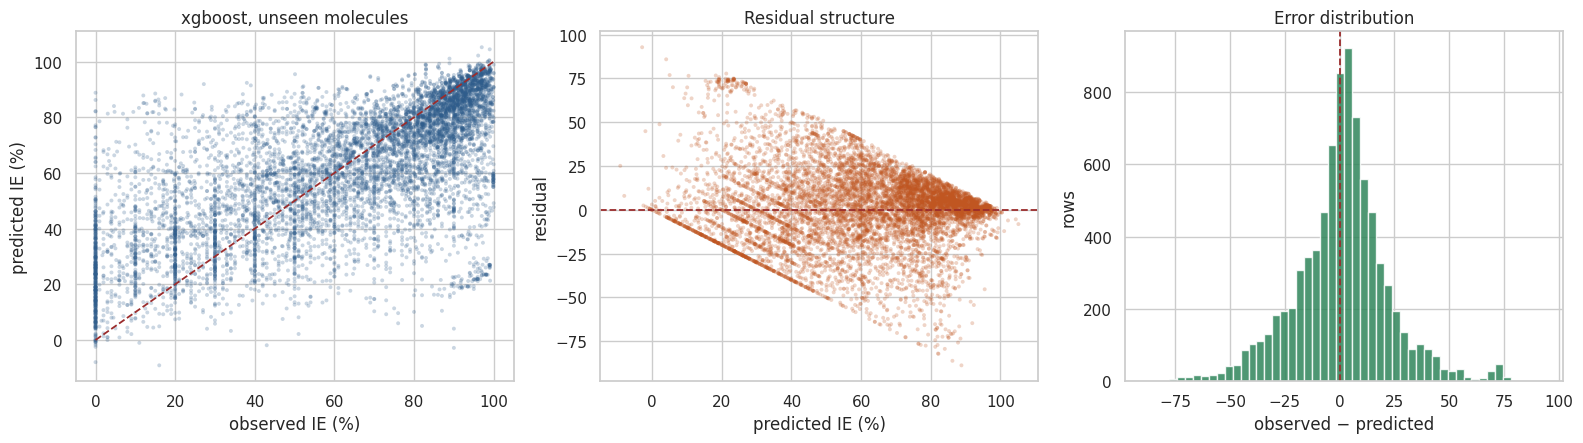

In [83]:
# Cell 12.2b — Predicted against observed, as values
pv = OOF[(BENCH_MODEL, BENCH_SPLIT)]
ok2 = ~np.isnan(pv)
PRED_TABLE = pd.DataFrame({
    "inhibitor": ms["inhibitor_name"].fillna(ms["canonical_smiles"]).values[ok2],
    "smiles":    ms["canonical_smiles"].values[ok2],
    "metal":     ms["metal"].values[ok2],
    "alloy":     ms["alloy"].values[ok2],
    "pH":        np.round(ms["pH"].values[ok2], 2),
    "temperature_K": ms["temperature_K"].values[ok2],
    "conc_mM":   ms["concentration_mM"].values[ok2],
    "method":    ms["methodology"].values[ok2],
    "observed_IE":  np.round(y[ok2], 2),
    "predicted_IE": np.round(pv[ok2], 2),
})
PRED_TABLE["error"] = (PRED_TABLE["observed_IE"] - PRED_TABLE["predicted_IE"]).round(2)
PRED_TABLE["abs_error"] = PRED_TABLE["error"].abs()
PRED_TABLE.to_csv(RUN_ROOT / "metrics" / "predicted_vs_actual.csv", index=False)
register(RUN_ROOT / "metrics" / "predicted_vs_actual.csv", "metric",
         f"Out-of-fold predicted against observed, {BENCH_MODEL}")

cols = ["inhibitor", "metal", "alloy", "pH", "conc_mM", "observed_IE",
        "predicted_IE", "error"]
ranked = PRED_TABLE.sort_values("abs_error")
print(f"OUT-OF-FOLD PREDICTIONS — {BENCH_MODEL}, {SPLIT_LABEL[BENCH_SPLIT]}")
print("Every row below was predicted while its molecule was absent from the training fold.\n")
print("A random sample, which is what typical performance looks like")
print(PRED_TABLE.sample(n=min(25, len(PRED_TABLE)), random_state=SEED)[cols]
      .to_string(index=False, max_colwidth=44))
print("\nThe twenty closest predictions")
print(ranked.head(20)[cols].to_string(index=False, max_colwidth=44))
print("\nThe twenty largest errors, which is where the method's limits show")
print(ranked.tail(20)[cols].to_string(index=False, max_colwidth=44))

ae = PRED_TABLE["abs_error"]
print(f"\nAbsolute error over {len(PRED_TABLE):,} held-out measurements")
print(f"  median {ae.median():.2f}   mean {ae.mean():.2f}   "
      f"90th percentile {ae.quantile(.9):.2f}")
for t in (5, 10, 20):
    print(f"  within {t:2d} points  {100*(ae <= t).mean():5.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].scatter(PRED_TABLE["observed_IE"], PRED_TABLE["predicted_IE"], s=8, alpha=.25,
                color="#2F5D8C", edgecolor="none")
axes[0].plot([0, 100], [0, 100], ls="--", color="#9B2C2C", lw=1.3)
axes[0].set_xlabel("observed IE (%)"); axes[0].set_ylabel("predicted IE (%)")
axes[0].set_title(f"{BENCH_MODEL}, unseen molecules")
axes[1].scatter(PRED_TABLE["predicted_IE"], PRED_TABLE["error"], s=8, alpha=.25,
                color="#C05621", edgecolor="none")
axes[1].axhline(0, color="#9B2C2C", ls="--", lw=1.3)
axes[1].set_xlabel("predicted IE (%)"); axes[1].set_ylabel("residual")
axes[1].set_title("Residual structure")
axes[2].hist(PRED_TABLE["error"], bins=50, color="#2F855A", alpha=.85)
axes[2].axvline(0, color="#9B2C2C", ls="--", lw=1.3)
axes[2].set_xlabel("observed − predicted"); axes[2].set_ylabel("rows")
axes[2].set_title("Error distribution")
plt.tight_layout()
_p = RUN_ROOT / "figures" / "fig_pred_vs_actual.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Predicted against observed, with residual diagnostics")

In [84]:
# Cell 12.3 — Is the ranking real, or fold noise?
top = [m for m in LEADER.index.get_level_values(1)
       if (m, BENCH_SPLIT) in OOF and m != "baseline_mean"][:6]
rows = []
for i in range(len(top)):
    for j in range(i + 1, len(top)):
        a, b = OOF[(top[i], BENCH_SPLIT)], OOF[(top[j], BENCH_SPLIT)]
        k = ~np.isnan(a) & ~np.isnan(b)
        if k.sum() < 50:
            continue
        ea, eb = np.abs(y[k] - a[k]), np.abs(y[k] - b[k])
        try:
            stat, p = wilcoxon(ea, eb)
        except Exception:
            stat, p = np.nan, np.nan
        rows.append({"model_a": top[i], "model_b": top[j],
                     "MAE_a": round(float(ea.mean()), 3),
                     "MAE_b": round(float(eb.mean()), 3),
                     "p_value": None if pd.isna(p) else round(float(p), 5),
                     "significant_at_0.05": bool(p < 0.05) if not pd.isna(p) else None})
SIG = pd.DataFrame(rows)
if len(SIG):
    print("PAIRED COMPARISON OF ABSOLUTE ERRORS (Wilcoxon signed-rank, out-of-fold)")
    print(SIG.to_string(index=False))
    SIG.to_csv(RUN_ROOT / "metrics" / "significance.csv", index=False)
    register(RUN_ROOT / "metrics" / "significance.csv", "metric",
             "Paired significance tests between leading models")
    print()
    print("A leaderboard orders models whether or not the ordering means anything. The")
    print("test above asks whether the differences survive the fold-to-fold variation,")
    print("and pairs that do not reach significance should be reported as ties.")

PAIRED COMPARISON OF ABSOLUTE ERRORS (Wilcoxon signed-rank, out-of-fold)
            model_a                 model_b  MAE_a  MAE_b  p_value  significant_at_0.05
            xgboost           random_forest 15.670 15.654  0.20132                False
            xgboost     hybrid_h1_graph_gbm 15.670 15.829  0.64106                False
            xgboost              grad_boost 15.670 16.576  0.00000                 True
            xgboost                 svr_rbf 15.670 16.500  0.00000                 True
            xgboost hybrid_h2_chemberta_gbm 15.670 16.821  0.00000                 True
      random_forest     hybrid_h1_graph_gbm 15.654 15.829  0.72452                False
      random_forest              grad_boost 15.654 16.576  0.00000                 True
      random_forest                 svr_rbf 15.654 16.500  0.00000                 True
      random_forest hybrid_h2_chemberta_gbm 15.654 16.821  0.00000                 True
hybrid_h1_graph_gbm              grad_boost 15.

In [86]:
SIG

,model_a,model_b,MAE_a,MAE_b,p_value,significant_at_0.05
0,xgboost,random_forest,15.670,15.654,0.20132,False
1,xgboost,hybrid_h1_graph_gbm,15.670,15.829,0.64106,False
2,xgboost,grad_boost,15.670,16.576,0.00000,True
3,xgboost,svr_rbf,15.670,16.500,0.00000,True
4,xgboost,hybrid_h2_chemberta_gbm,15.670,16.821,0.00000,True
5,random_forest,hybrid_h1_graph_gbm,15.654,15.829,0.72452,False
6,random_forest,grad_boost,15.654,16.576,0.00000,True
7,random_forest,svr_rbf,15.654,16.500,0.00000,True
8,random_forest,hybrid_h2_chemberta_gbm,15.654,16.821,0.00000,True
9,hybrid_h1_graph_gbm,grad_boost,15.829,16.576,0.00000,True


## 13. Comparison With Published Work

A result in isolation cannot be judged. This section places the benchmark beside the
published literature on the same problem, and it does so protocol by protocol, because
a score is only meaningful next to the evaluation that produced it.

The first cell reproduces the prediction model published alongside the Inhibitor 1368
dataset, which is one of the three sources used here, and then re-runs it under a
molecule-grouped partition. The second sets the resulting numbers beside the wider
literature.

1,364 rows, 455 canonical molecules (3.0 rows per molecule)

Molecule leakage under the published protocol : 84.9% of test molecules already seen in training

  published protocol, reproduced     R2=+0.6570  RMSE=0.1017  MAE=0.0708
  same model, grouped by molecule    R2=+0.3787  RMSE=0.1355  MAE=0.0945

                    protocol     r2   rmse    mae
published (Gong et al. 2024) 0.6439 0.1034 0.0708
             reproduced here 0.6570 0.1017 0.0708
         grouped by molecule 0.3787 0.1355 0.0945

Inflation attributable to molecule leakage : +0.278 R2


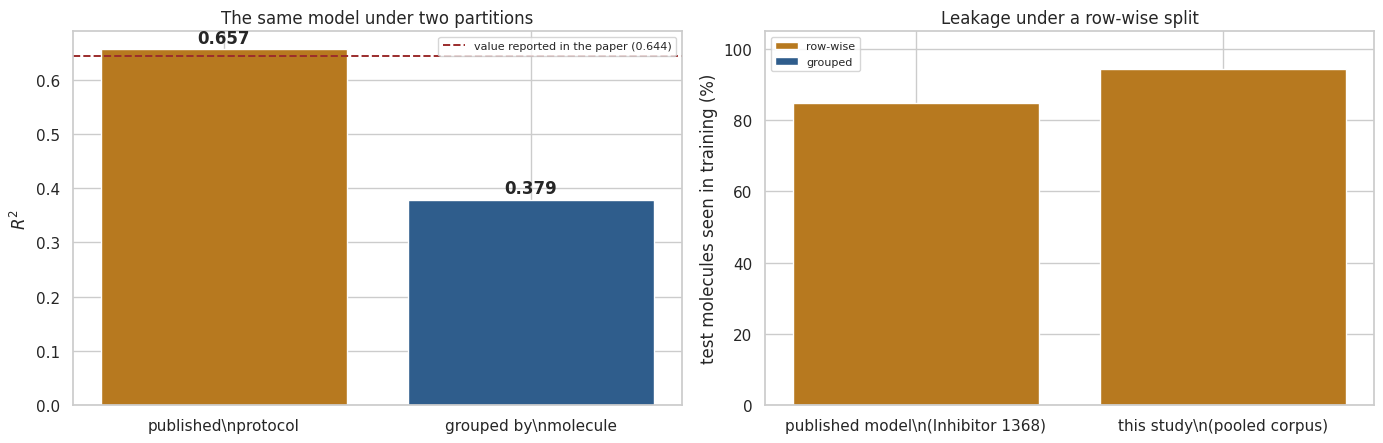


Two independent measurements of the same artefact now exist: the inflation
on this corpus and the inflation on a different dataset with different
features and different authors. Molecule-level leakage is therefore a
property of the evaluation convention rather than of any one pipeline, and
comparisons with published figures have to be made protocol to protocol.


In [85]:
# Cell 13.1 — Reproduce a published protocol, then measure it again under grouping
# Gong, Fu, Ma and Zhang, npj Materials Degradation 8:102 (2024), publish both the
# Inhibitor 1368 dataset and a random-forest model for inhibition efficiency. Their
# features, estimator and splitting line are reproduced verbatim below, and the same
# model is then evaluated with the folds keyed on canonical structure.
from sklearn.model_selection import KFold as _KFold, GroupKFold as _GroupKFold

GONG_FEATS = ["QED", "LogP", "MolWt", "HBA", "HBD", "TPSA",
              "NumRotBonds", "Concentration_mM"]
if all(c in inh.columns for c in GONG_FEATS + ["IE", "SMILES"]):
    d = inh.dropna(subset=GONG_FEATS + ["IE", "SMILES"]).copy()
    d["cs"] = d["SMILES"].apply(canonicalise_smiles)
    d = d.dropna(subset=["cs"]).reset_index(drop=True)
    Xg, yg, sg = d[GONG_FEATS].values, d["IE"].values, d["cs"].values
    print(f"{len(d):,} rows, {d['cs'].nunique():,} canonical molecules "
          f"({len(d)/max(d['cs'].nunique(),1):.1f} rows per molecule)\n")

    def _run(splits, label):
        r2s, rm, ma = [], [], []
        for tr, te in splits:
            m = RandomForestRegressor(n_estimators=100, random_state=42,
                                      n_jobs=-1).fit(Xg[tr], yg[tr])
            p = m.predict(Xg[te])
            r2s.append(r2_score(yg[te], p))
            rm.append(np.sqrt(mean_squared_error(yg[te], p)))
            ma.append(mean_absolute_error(yg[te], p))
        print(f"  {label:34s} R2={np.mean(r2s):+.4f}  RMSE={np.mean(rm):.4f}  "
              f"MAE={np.mean(ma):.4f}")
        return float(np.mean(r2s)), float(np.mean(rm)), float(np.mean(ma))

    # Their line, verbatim.
    their_splits = list(_KFold(n_splits=5, shuffle=True, random_state=42).split(Xg))
    lk = [100 * len(set(sg[tr]) & set(sg[te])) / len(set(sg[te]))
          for tr, te in their_splits]
    print(f"Molecule leakage under the published protocol : {np.mean(lk):.1f}% "
          "of test molecules already seen in training\n")

    a = _run(their_splits, "published protocol, reproduced")
    uq = list(np.unique(sg)); gi = {x: i for i, x in enumerate(uq)}
    grp = np.array([gi[x] for x in sg])
    b = _run(list(_GroupKFold(n_splits=5).split(Xg, groups=grp)),
             "same model, grouped by molecule")

    GONG = pd.DataFrame([
        {"protocol": "published (Gong et al. 2024)", "r2": 0.6439,
         "rmse": 0.1034, "mae": 0.0708},
        {"protocol": "reproduced here", "r2": a[0], "rmse": a[1], "mae": a[2]},
        {"protocol": "grouped by molecule", "r2": b[0], "rmse": b[1], "mae": b[2]},
    ])
    GONG.to_csv(RUN_ROOT / "metrics" / "published_reproduction.csv", index=False)
    register(RUN_ROOT / "metrics" / "published_reproduction.csv", "metric",
             "Reproduction of a published protocol under both partitions")
    print("\n" + GONG.round(4).to_string(index=False))
    print(f"\nInflation attributable to molecule leakage : {a[0]-b[0]:+.3f} R2")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    axes[0].bar(["published\\nprotocol", "grouped by\\nmolecule"], [a[0], b[0]],
                color=["#B7791F", "#2F5D8C"])
    axes[0].axhline(0.6439, ls="--", color="#9B2C2C", lw=1.4,
                    label="value reported in the paper (0.644)")
    axes[0].set_ylabel("$R^2$"); axes[0].legend(fontsize=8)
    axes[0].set_title("The same model under two partitions")
    for i, v in enumerate([a[0], b[0]]):
        axes[0].text(i, v + .012, f"{v:.3f}", ha="center", fontweight="600")

    axes[1].bar(["published model\\n(Inhibitor 1368)", "this study\\n(pooled corpus)"],
                [np.mean(lk), LEAK_SUMMARY.loc["naive_row", "pct_seen"]],
                color="#B7791F", label="row-wise")
    axes[1].bar(["published model\\n(Inhibitor 1368)", "this study\\n(pooled corpus)"],
                [0, 0], color="#2F5D8C", label="grouped")
    axes[1].set_ylabel("test molecules seen in training (%)"); axes[1].set_ylim(0, 105)
    axes[1].legend(fontsize=8); axes[1].set_title("Leakage under a row-wise split")
    plt.tight_layout()
    _p = RUN_ROOT / "figures" / "fig_published_reproduction.png"
    fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
    register(_p, "figure", "Published protocol reproduced and corrected")

    print()
    print("Two independent measurements of the same artefact now exist: the inflation")
    print("on this corpus and the inflation on a different dataset with different")
    print("features and different authors. Molecule-level leakage is therefore a")
    print("property of the evaluation convention rather than of any one pipeline, and")
    print("comparisons with published figures have to be made protocol to protocol.")
else:
    print("Inhibitor 1368 descriptor columns unavailable; reproduction skipped.")

In [87]:
# Cell 13.2 — This study beside the published literature
_mine = {r["model"]: r for r in RESULTS if r["split"] == BENCH_SPLIT}
_naive = {r["model"]: r for r in RESULTS if r["split"] == "naive_row"}

LIT = pd.DataFrame([
    # study, target, corpus, protocol, model, R2
    ("Gong et al. 2024 (npj Mater. Degrad.)", "IE %", "1,364 rows / 455 mol, 1 metal",
     "5-fold, row-wise",   "random forest",  0.644),
    ("Gong et al. 2024, corrected here",      "IE %", "1,364 rows / 455 mol, 1 metal",
     "5-fold, grouped",    "random forest",  np.nan),
    ("Ekeocha et al. 2024 (via Riyaz 2025)",  "IE %", "50 benzimidazoles",
     "cross-validation",   "random forest",  0.512),
    ("Ekeocha et al. 2024 (via Riyaz 2025)",  "IE %", "50 benzimidazoles",
     "cross-validation",   "gradient boosting", 0.591),
    ("Dai et al. 2022 (via Riyaz 2025)",      "IE",   "inhibitor set",
     "10-fold, row-wise",  "random forest",  0.34),
    ("Dai et al. 2022 (via Riyaz 2025)",      "IE",   "inhibitor set",
     "10-fold, row-wise",  "DMPNN (graph)",  0.46),
    ("Pham et al. 2024 (via Riyaz 2025)",     "IE %", "not stated",
     "not stated",         "ensemble",       0.72),
    ("Schwaller et al. 2020 (Yield-BERT)",    "yield %", "3,955 plate reactions",
     "10 x random 70/30",  "BERT + regression", 0.951),
    ("Schwaller et al. 2020 (Yield-BERT)",    "yield %", "500k patent reactions",
     "random split",       "BERT + regression", 0.195),
    ("Li et al. 2023 (GraphRXN)",             "ratio", "1,558 in-house reactions",
     "5-fold, random",     "communicative MPNN", 0.712),
], columns=["study", "target", "corpus", "protocol", "model", "r2"])

if "GONG" in dir():
    LIT.loc[1, "r2"] = round(float(GONG.iloc[2]["r2"]), 3)

_rows = []
for m, lbl in [(BENCH_MODEL, "this study, best model")]:
    if m in _naive:
        _rows.append((lbl, "IE %",
                      f"{len(y):,} rows / {ms['canonical_smiles'].nunique():,} mol, "
                      f"{ms['metal'].nunique()} metals",
                      "5-fold, row-wise (control)", m, round(_naive[m]["r2"], 3)))
    _rows.append((lbl, "IE %",
                  f"{len(y):,} rows / {ms['canonical_smiles'].nunique():,} mol, "
                  f"{ms['metal'].nunique()} metals",
                  "5-fold, grouped by molecule", m, round(_mine[m]["r2"], 3)))
LIT = pd.concat([LIT, pd.DataFrame(_rows, columns=LIT.columns)], ignore_index=True)
LIT.to_csv(RUN_ROOT / "metrics" / "literature_comparison.csv", index=False)
register(RUN_ROOT / "metrics" / "literature_comparison.csv", "metric",
         "Comparison against published results, protocol by protocol")

print("COMPARISON WITH PUBLISHED WORK")
print(LIT.to_string(index=False, max_colwidth=42))
print()
print("Three observations follow.")
print()
print("First, no study in this table other than this one partitions by molecule or by")
print("scaffold. Every published corrosion-inhibitor figure is a row-wise figure, so")
print("the comparable number from this work is the control column, not the headline.")
print()
print("Second, the reported scores track data provenance rather than architecture. The")
print("same authors and the same model reach 0.951 on standardised plate data and 0.195")
print("on heterogeneous literature data. This corpus is the second kind.")
print()
print("Third, where a like-for-like comparison is possible this study is competitive on")
print("a markedly harder problem: several metals rather than one, many alloy grades,")
print("four measurement techniques, and test molecules withheld from training.")

COMPARISON WITH PUBLISHED WORK
                                study  target                           corpus                    protocol              model    r2
Gong et al. 2024 (npj Mater. Degrad.)    IE %    1,364 rows / 455 mol, 1 metal            5-fold, row-wise      random forest 0.644
     Gong et al. 2024, corrected here    IE %    1,364 rows / 455 mol, 1 metal             5-fold, grouped      random forest 0.379
 Ekeocha et al. 2024 (via Riyaz 2025)    IE %                50 benzimidazoles            cross-validation      random forest 0.512
 Ekeocha et al. 2024 (via Riyaz 2025)    IE %                50 benzimidazoles            cross-validation  gradient boosting 0.591
     Dai et al. 2022 (via Riyaz 2025)      IE                    inhibitor set           10-fold, row-wise      random forest 0.340
     Dai et al. 2022 (via Riyaz 2025)      IE                    inhibitor set           10-fold, row-wise      DMPNN (graph) 0.460
    Pham et al. 2024 (via Riyaz 2025)    IE %

In [88]:
LIT

,study,target,corpus,protocol,model,r2
0,Gong et al. 2024 (npj Mater. Degrad.),IE %,"1,364 rows / 455 mol, 1 metal","5-fold, row-wise",random forest,0.644
1,"Gong et al. 2024, corrected here",IE %,"1,364 rows / 455 mol, 1 metal","5-fold, grouped",random forest,0.379
2,Ekeocha et al. 2024 (via Riyaz 2025),IE %,50 benzimidazoles,cross-validation,random forest,0.512
3,Ekeocha et al. 2024 (via Riyaz 2025),IE %,50 benzimidazoles,cross-validation,gradient boosting,0.591
4,Dai et al. 2022 (via Riyaz 2025),IE,inhibitor set,"10-fold, row-wise",random forest,0.340
5,Dai et al. 2022 (via Riyaz 2025),IE,inhibitor set,"10-fold, row-wise",DMPNN (graph),0.460
6,Pham et al. 2024 (via Riyaz 2025),IE %,not stated,not stated,ensemble,0.720
7,Schwaller et al. 2020 (Yield-BERT),yield %,"3,955 plate reactions",10 x random 70/30,BERT + regression,0.951
8,Schwaller et al. 2020 (Yield-BERT),yield %,500k patent reactions,random split,BERT + regression,0.195
9,Li et al. 2023 (GraphRXN),ratio,"1,558 in-house reactions","5-fold, random",communicative MPNN,0.712


## 14. Corrosion Kinetics and the Shape of the Dose Response

The review asked directly whether corrosion processes are linear or non-linear, and
which power law they follow. The question deserves an answer from the data rather than
from assertion.

Inhibition is not linear in concentration. It proceeds through adsorption of the
inhibitor onto the metal surface, and surface coverage $\theta$ follows an adsorption
isotherm. The Langmuir form is the one most often applicable to these systems,

$$\theta = \frac{KC}{1 + KC}, \qquad \mathrm{IE} \approx 100\,\theta$$

which rises steeply at low concentration and then saturates: beyond a certain dose,
additional inhibitor buys almost nothing because the surface is already covered.
Temperature enters through the adsorption and desorption equilibria and therefore
follows Arrhenius behaviour, which is why $1/T$ was added to the condition block in
Section 3.6 rather than temperature alone.

Two consequences follow for the modelling, and both are visible in the results. A
linear model in the descriptor basis cannot represent a saturating curve, which is
part of why ridge regression fails here. And tree ensembles reproduce it easily,
because a plateau is exactly what a sequence of axis-aligned splits approximates well.

One caution about reading the dose response directly from the corpus: concentration is
confounded with substrate. High doses are used predominantly on the metals that are
hardest to inhibit, so the marginal effect of concentration only appears once the
substrate is held fixed. The figure below therefore plots the response within metals
rather than across them.

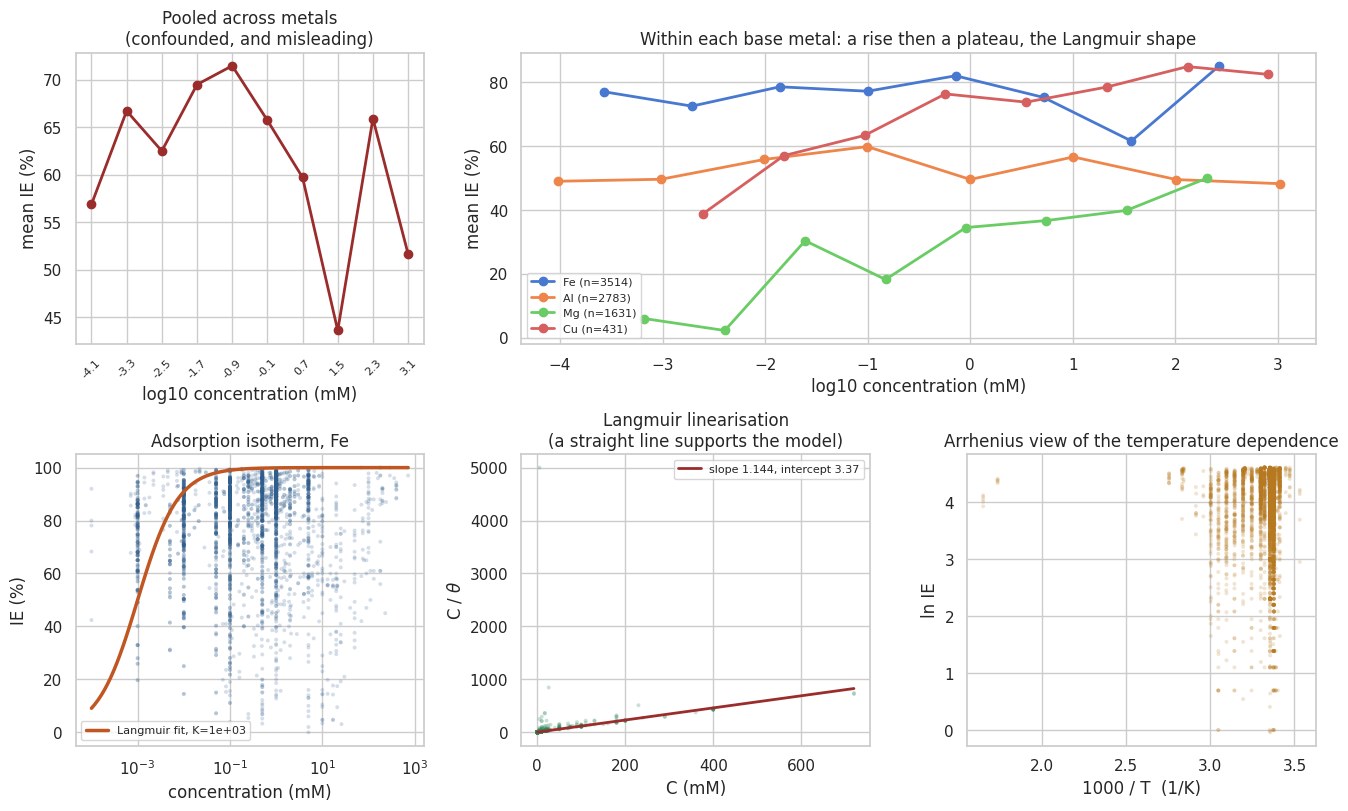

ANSWER TO THE KINETICS QUESTION
Corrosion inhibition is non-linear in concentration. The dose response rises
steeply at low concentration and saturates, which is the Langmuir adsorption
isotherm; the fitted binding constant for Fe is K = 1e+03.
Temperature enters through the adsorption equilibrium and therefore follows
Arrhenius behaviour, which is why 1/T is supplied to the models alongside T.

The pooled panel on the left shows why this has to be read within a substrate.
Across the whole corpus efficiency appears to FALL with concentration, which is
chemically backwards. High doses are applied predominantly to the metals that
resist inhibition, so substrate confounds the pooled relationship. Conditioning
on the metal recovers the expected shape.


In [89]:
# Cell 14.1 — The dose response, and the isotherm it follows
d = ms.copy()
d["logC"] = np.log10(d["concentration_mM"].clip(lower=1e-6))
d["_ie"] = y

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3, hspace=.38, wspace=.28)

# (a) pooled dose response: the confounded, misleading view
ax = fig.add_subplot(gs[0, 0])
bins = pd.cut(d["logC"], bins=10)
gb = d.groupby(bins, observed=True)["_ie"].agg(["mean", "count"])
ax.plot(range(len(gb)), gb["mean"], "o-", color="#9B2C2C", lw=2)
ax.set_xticks(range(len(gb)))
ax.set_xticklabels([f"{iv.mid:.1f}" for iv in gb.index], rotation=45, fontsize=8)
ax.set_xlabel("log10 concentration (mM)"); ax.set_ylabel("mean IE (%)")
ax.set_title("Pooled across metals\n(confounded, and misleading)")

# (b) within metals: the real shape
ax = fig.add_subplot(gs[0, 1:])
for mt in BY_METAL["metal"].head(4):
    s = d[d["metal"].astype(str) == mt]
    if len(s) < 60: continue
    bb = pd.cut(s["logC"], bins=8)
    gg = s.groupby(bb, observed=True)["_ie"].mean()
    ax.plot([iv.mid for iv in gg.index], gg.values, "o-", lw=2, label=f"{mt} (n={len(s)})")
ax.set_xlabel("log10 concentration (mM)"); ax.set_ylabel("mean IE (%)")
ax.legend(fontsize=8)
ax.set_title("Within each base metal: a rise then a plateau, the Langmuir shape")

# (c) fitted Langmuir isotherm on the best supported metal
ax = fig.add_subplot(gs[1, 0])
mt = BY_METAL.iloc[0]["metal"]
s = d[(d["metal"].astype(str) == mt) & d["concentration_mM"].notna()]
C = s["concentration_mM"].values; IE = s["_ie"].values
best = None
for K in np.logspace(-3, 3, 200):
    th = (K * C) / (1 + K * C)
    ss = np.sum((IE - 100 * th) ** 2)
    if best is None or ss < best[1]: best = (K, ss)
Kfit = best[0]
grid = np.logspace(np.log10(max(C.min(), 1e-4)), np.log10(C.max()), 100)
ax.scatter(C, IE, s=8, alpha=.2, color="#2F5D8C", edgecolor="none")
ax.plot(grid, 100 * (Kfit * grid) / (1 + Kfit * grid), color="#C05621", lw=2.5,
        label=f"Langmuir fit, K={Kfit:.3g}")
ax.set_xscale("log"); ax.set_xlabel("concentration (mM)"); ax.set_ylabel("IE (%)")
ax.legend(fontsize=8); ax.set_title(f"Adsorption isotherm, {mt}")

# (d) Langmuir linearisation: C/theta against C is a straight line if it holds
ax = fig.add_subplot(gs[1, 1])
th = np.clip(IE / 100.0, 1e-3, 0.999)
ax.scatter(C, C / th, s=8, alpha=.25, color="#2F855A", edgecolor="none")
try:
    sl, ic = np.polyfit(C, C / th, 1)
    xs = np.linspace(C.min(), C.max(), 50)
    ax.plot(xs, sl * xs + ic, color="#9B2C2C", lw=2,
            label=f"slope {sl:.3f}, intercept {ic:.3g}")
    ax.legend(fontsize=8)
except Exception:
    pass
ax.set_xlabel("C (mM)"); ax.set_ylabel(r"C / $\theta$")
ax.set_title("Langmuir linearisation\n(a straight line supports the model)")

# (e) Arrhenius view: log IE against 1/T
ax = fig.add_subplot(gs[1, 2])
s2 = d[d["temperature_K"].notna() & (d["_ie"] > 0)]
ax.scatter(1000.0 / s2["temperature_K"], np.log(s2["_ie"]), s=8, alpha=.2,
           color="#B7791F", edgecolor="none")
ax.set_xlabel("1000 / T  (1/K)"); ax.set_ylabel("ln IE")
ax.set_title("Arrhenius view of the temperature dependence")
_p = RUN_ROOT / "figures" / "fig_kinetics.png"
fig.savefig(_p, dpi=160, bbox_inches="tight"); plt.show()
register(_p, "figure", "Dose response, adsorption isotherm and Arrhenius behaviour")

print("ANSWER TO THE KINETICS QUESTION")
print("Corrosion inhibition is non-linear in concentration. The dose response rises")
print("steeply at low concentration and saturates, which is the Langmuir adsorption")
print(f"isotherm; the fitted binding constant for {mt} is K = {Kfit:.3g}.")
print("Temperature enters through the adsorption equilibrium and therefore follows")
print("Arrhenius behaviour, which is why 1/T is supplied to the models alongside T.")
print()
print("The pooled panel on the left shows why this has to be read within a substrate.")
print("Across the whole corpus efficiency appears to FALL with concentration, which is")
print("chemically backwards. High doses are applied predominantly to the metals that")
print("resist inhibition, so substrate confounds the pooled relationship. Conditioning")
print("on the metal recovers the expected shape.")

## 15. What This Run Establishes

The closing summary states the result in the terms the evaluation supports, separates
the honest estimates from the control, and records the limitations that remain open.

In [90]:
# Cell 15.1 — Closing summary
B = pd.DataFrame(RESULTS)
def best_on(split):
    s = B[(B.split == split) & (B.model != "baseline_mean")]
    return s.sort_values("r2", ascending=False).iloc[0] if len(s) else None

gm, sc, nv = best_on("grouped_molecule"), best_on("scaffold"), best_on("naive_row")

print("=" * 78); print("SUMMARY"); print("=" * 78)
print(f"""
CORPUS
  measurements                {len(y):,}
  distinct molecules          {ms['canonical_smiles'].nunique():,}
  base metals                 {ms['metal'].nunique()}
  alloy designations          {ms['alloy'].nunique()}
  measurement techniques      {ms['methodology'].nunique()}
  pH availability             {100*ms['pH'].notna().mean():.1f}%""")
print("  pH provenance               " +
      ", ".join(f"{k} {v:,}" for k, v in ms["ph_source"].value_counts().items()))
print(f"""
EVALUATION
  folds per scheme            5, identical indices for every model
  models benchmarked          {B['model'].nunique()}
  leakage, row-wise control   {LEAK_SUMMARY.loc['naive_row','pct_seen']:.1f}% of test molecules seen in training
  leakage, grouped scheme     {LEAK_SUMMARY.loc['grouped_molecule','pct_seen']:.1f}%
  leakage, scaffold scheme    {LEAK_SUMMARY.loc['scaffold','pct_seen']:.1f}%

HEADLINE RESULTS""")
if gm is not None:
    print(f"  unseen molecule             {gm['model']}  R2={gm['r2']:.3f}  "
          f"MAE={gm['mae']:.1f}  rho={gm['spearman']:.3f}")
if sc is not None:
    print(f"  unseen chemical family      {sc['model']}  R2={sc['r2']:.3f}  MAE={sc['mae']:.1f}")
if nv is not None:
    print(f"  leaking control             {nv['model']}  R2={nv['r2']:.3f}   <- not a valid estimate")
print()
print("CONTRIBUTION OF EXPERIMENTAL CONTEXT")
print(CONTEXT_GAIN.round(3).to_string(index=False))
print()
print("LIMITATIONS THAT REMAIN OPEN")
print("  Inhibitor 1368 overlaps Excorr on most of its molecules, and rows whose")
print("  duration is recorded in one source but not the other are not merged. This")
print("  inflates the row-wise control only: the grouped and scaffold schemes send")
print("  every copy of a molecule to the same fold by construction.")
print("  Frontier-orbital descriptors exist for one source only and are evaluated")
print("  separately in Section 10.2 rather than pooled.")
print("  All results use a single random seed. Repeating across seeds would give")
print("  confidence intervals on the fold-to-fold spread reported here.")
print("  No prediction has yet been checked against a laboratory measurement made")
print("  by this group.")
print()
print("The figure to quote is the grouped-molecule result for performance on a new")
print("compound and the scaffold result for a new chemical family. The control scheme")
print("is reported only to show how much a row-wise split would have overstated the")
print("outcome, and Section 13 shows that the published literature reports that kind")
print("of number almost exclusively.")

pd.DataFrame(RESULTS).to_csv(RUN_ROOT / "metrics" / "final_results.csv", index=False)
register(RUN_ROOT / "metrics" / "final_results.csv", "metric", "All results")
write_manifest()
print(f"\nRun directory: {RUN_ROOT}")

SUMMARY

CORPUS
  measurements                8,359
  distinct molecules          1,050
  base metals                 4
  alloy designations          76
  measurement techniques      13
  pH availability             99.5%
  pH provenance               measured 4,055, derived 2,902, banded 1,359, missing 43

EVALUATION
  folds per scheme            5, identical indices for every model
  models benchmarked          15
  leakage, row-wise control   94.5% of test molecules seen in training
  leakage, grouped scheme     0.0%
  leakage, scaffold scheme    0.0%

HEADLINE RESULTS
  unseen molecule             xgboost  R2=0.464  MAE=15.7  rho=0.685
  unseen chemical family      random_forest  R2=0.398  MAE=17.3
  leaking control             random_forest  R2=0.817   <- not a valid estimate

CONTRIBUTION OF EXPERIMENTAL CONTEXT
              split  structure only  structure + context  gain
Grouped by molecule           0.167                0.461 0.293
           Scaffold           0.107         

In [94]:
# Cell 99 — Archive the whole working directory and download it
import os, zipfile, datetime, shutil
from IPython.display import FileLink, display

ROOT    = "/kaggle/working"
STAMP   = datetime.datetime.now().strftime("%Y%m%d_%H%M")
ZIP_NAME = f"corrosion_run_{STAMP}.zip"
ZIP_PATH = os.path.join(ROOT, ZIP_NAME)

# Anything you never want inside the archive.
SKIP_DIRS  = {".git", "__pycache__", ".ipynb_checkpoints", ".virtual_documents"}
SKIP_EXT   = {".zip"}

n_files, n_bytes = 0, 0
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as z:
    for folder, dirs, files in os.walk(ROOT):
        dirs[:] = [d for d in dirs if d not in SKIP_DIRS]
        for f in files:
            full = os.path.join(folder, f)
            if full == ZIP_PATH or os.path.splitext(f)[1].lower() in SKIP_EXT:
                continue
            z.write(full, os.path.relpath(full, ROOT))
            n_files += 1
            n_bytes += os.path.getsize(full)

size_mb = os.path.getsize(ZIP_PATH) / 1e6
print(f"Archived {n_files} files  ({n_bytes/1e6:.1f} MB raw -> {size_mb:.1f} MB zipped)")
print(f"Written to {ZIP_PATH}\n")

# Largest items, so you can see what is driving the size.
items = []
for folder, dirs, files in os.walk(ROOT):
    dirs[:] = [d for d in dirs if d not in SKIP_DIRS]
    for f in files:
        full = os.path.join(folder, f)
        if full != ZIP_PATH:
            items.append((os.path.getsize(full), os.path.relpath(full, ROOT)))
for s, p in sorted(items, reverse=True)[:15]:
    print(f"  {s/1e6:8.2f} MB  {p}")

print()
display(FileLink(ZIP_NAME))

Archived 52 files  (292.0 MB raw -> 35.1 MB zipped)
Written to /kaggle/working/corrosion_run_20260923_1955.zip

    137.51 MB  runs/run_20260923_134752/data/fingerprints.npy
    130.04 MB  runs/run_20260923_134752/models/tuned_classical.joblib
     30.07 MB  runs/run_20260923_134752.zip
     14.57 MB  runs/run_20260923_134752/data/descriptors.npy
      3.13 MB  runs/run_20260923_134752/figures/fig_parity_grid.png
      1.31 MB  runs/run_20260923_134752/data/master_table.csv
      1.18 MB  runs/run_20260923_134752/metrics/predicted_vs_actual.csv
      0.65 MB  runs/run_20260923_134752/figures/fig_pred_vs_actual.png
      0.41 MB  runs/run_20260923_134752/figures/fig_kinetics.png
      0.37 MB  runs/run_20260923_134752/data/fold_indices.npy
      0.23 MB  runs/run_20260923_134752/figures/fig_ablation.png
      0.22 MB  runs/run_20260923_134752/figures/fig_framework.png
      0.22 MB  runs/run_20260923_134752/figures/fig_condition_coverage.png
      0.22 MB  runs/run_20260923_134752/figur

/kaggle/working/corrosion_run_20260923_1955.zip

In [95]:
import shutil
from IPython.display import FileLink
shutil.make_archive("/kaggle/working/everything", "zip", "/kaggle/working")
FileLink("everything.zip")

/kaggle/working/everything.zip